# Basat: user-defined objectives and unified experiments

**Sections 1–4: archived example outputs.** Experiment summaries and figures below were rebuilt from the current saved result JSON files, without running optimization again. Each refreshed output identifies its source file and preserves recorded warnings and stopping reasons. Execution counters are cleared for those cells to distinguish this refresh from running the code. Editing an experiment configuration does not change its saved measurements until you execute it again. The distributional example uses the completed OPSD wind-power run with 5 trials and 50 evaluations.

This guide has four main sections: **1. Synthetic Functions Optimizations**,
**2. Real Data Formatting** (including **2.1 Real Life Objective Optimization**),
**3. Early Stopping**, and **4. Different Settings Examples**.

Install the updated checkout with `python -m pip install .`, or install its
supplied wheel. Installing Basat installs its runtime dependencies. Every
executable example imports only `basat` and uses Python built-ins. No other package imports are required in the cells. Section 5's SAASBO
reproduction additionally requires the optional `numpyro` installation extra.
These changes must be released before a package-index installation provides
this exact API. Open this notebook with
`python -m basat notebook docs/basat_user_guide.ipynb`.

Each experiment block runs independently: copy the entire block, including
its import and configuration definitions. Earlier blocks are not prerequisites.
This notebook is the current guide; older exported companions are historical snapshots.
Data files live in the project's external `data` directory; locate this guide
within that project, or edit the explicit data path.

The execution manifest records the Python version, platform and backend
versions reported by `basat.runtime_info()`. The exact dependency snapshot
is retained at `output/last_guide/execution_requirements.txt` and included
with the editable Overleaf source. Basat installs its runtime dependencies
automatically; these recorded versions identify the environment that
produced the figures.

`Experiment` is the single runner. Its `algorithm` argument accepts one
algorithm, a list/tuple of algorithms, or a label-to-algorithm dictionary.
A dictionary makes labels explicit when comparing several configurations of
the same method. Multiple algorithms receive independent environments and
stopping rules; each has its own budget (50 evaluations in Sections 1–4). Individual failures
are reported and the other methods continue. With the default `trials=1`,
single-algorithm exceptions remain visible to the caller. With `trials>1`,
a failed single-algorithm trial is recorded and the remaining seeds continue.

**There is no profile setting.** Omitting optional configuration fields uses
the algorithm's dataclass defaults; required scientific choices must still be
supplied. No preset chooses your objective, environment, threshold, or budget.
The expanded configurations below show algorithm hyperparameters, including
options inactive for the selected method variant. Environment observations
and support belong to the environment, not to algorithm configurations.
Example compute budgets are deliberately modest and are not convergence claims.

## Reproduction section

Section 5 contains the independent nine-method Hartmann6_300 reproduction with five seeds and method-specific paper budgets (SAASBO/ALEBO: 200; the other Song baselines: 600), plus two AG-VS comparisons with an added 600-evaluation budget. The current TuRBO result uses D=300 and numerical policy v3; all five historical incumbent trajectories match within 1.75e-09. Its displayed final mean is 2.816661574. The other eight curves remain archived measurements. Sections 1-4 retain their separate tutorial outputs, not Hartmann results.


# 1. Synthetic Functions Optimizations

Define an objective as an ordinary Python function returning one finite
scalar. Basat maximizes reward by default, so negate a loss to minimize it.
There is no predefined synthetic benchmark inside the library. You can
replace any function body below with your own calculation or simulator.

A stochastic function receives the chosen action. A contextual function also
receives a context revealed before selection. A distributional function
receives the context sampled after action selection; the learner sees a
reference distribution beforehand. An adversarial function receives the
evaluated coordinate after the environment has applied its attack.

These four definitions are repeated in the independent experiments below.
Only the distributional function includes an added sinusoidal component.
Observation noise is configured separately in each environment.

In [1]:
import basat

def stochastic_objective(values):
    target = (0.2, 0.65, 0.4)
    return -sum((x - t) ** 2 for x, t in zip(values, target))


def contextual_objective(values, context):
    c = float(context[0])
    target = (0.2 + 0.5 * c, 0.75 - 0.4 * c, 0.4)
    return -sum((x - t) ** 2 for x, t in zip(values, target))


def reveal_context(*, round_index, generator):
    return [float(round_index % 2)]


def distributional_objective(values, context):
    c = float(context[0])
    target = (0.25 + 0.35 * c, 0.6 - 0.2 * c, 0.3)
    distance = sum((x - t) ** 2 for x, t in zip(values, target))
    wave = 0.08 * basat.sin(6.0 * 3.141592653589793 * values[0])
    return float(-distance + wave)


def adversarial_objective(values):
    # This function receives the evaluated (already perturbed) coordinate.
    target = (0.3, 0.7, 0.5)
    return -sum((x - t) ** 2 for x, t in zip(values, target))


def apply_attack(action, *, round_index, generator):
    direction = 1.0 if round_index % 2 else -1.0
    changed = min(1.0, max(0.0, float(action[0]) + 0.05 * direction))
    return [changed - float(action[0]), 0.0, 0.0]

## How to read the full configurations

### Five independent trials and vertical uncertainty bars

The tutorial blocks in Sections 1–4 use `experiment.run(trials=5, max_evaluations=50)`.
Section 5 instead uses the source seeds 2021–2025 and per-method paper budgets.
Trial 1 uses each algorithm's configured seed; trials 2-5 add 1-4. A base seed
of 42 therefore becomes 42, 43, 44, 45, 46. Explicit nested acquisition seeds
and the environment's own base seed advance by the same trial offset. Each
trial starts with fresh algorithm state, embeddings, environment history and
stopping rules. Configured previous data remain available to every trial.
The total budget is up to 250 evaluations per algorithm, 50 per trial.

`trials=1` (the default) preserves the existing single-run result type.
Repeated runs return `ExperimentTrialsResult`: `result.results[label]` contains
the individual outcomes (or `None` for failed methods), `result.statistics[label]`
contains means, sample standard deviations and contributing counts, and
`experiment.trial_experiments` exposes the independent trial coordinators.
The original algorithm objects serve as configuration templates.

`basat.plot(experiment)` draws mean reward and mean per-trial incumbent curves.
It computes each trial's best-so-far curve before averaging. Vertical bars
show mean ± 1.96 sample standard deviations (`uncertainty="std95"`), describing
between-trial variability. They are not a 95% confidence interval for the mean,
and five trials do not establish 95% coverage. Use `uncertainty="std"` for one
sample SD or `uncertainty=None` for means only. No shaded bands are used.
`errorbar_cycles=5` controls the target repetition frequency; Basat scales
spacing with the evaluation range and number of methods, and gives each method
a different offset. All bars use actual integer evaluation positions within
the data. If there are more methods than evaluations, some methods cannot have
distinct bar positions. No SD bar is drawn when only one trial contributes.
Changing the seed does not force randomness: deterministic finite-table
policies can follow identical trajectories across trials, giving zero sample
SD and invisible zero-height bars.

Early-stopped or failed histories are never extended. Later means can therefore
use fewer trials; inspect `result.statistics[label].count` before comparing
tails. Failed trials and their partial measurements remain in the audit data.
Five-trial success does not validate every algorithm's modeling assumptions.

Checkpoints live under `trials/trial-001/` through `trials/trial-005/`; each
multi-algorithm trial has its own `algorithms/` subdirectories. The root JSON
stores aggregate statistics and all per-trial records. To resume, reconstruct
the same base configurations and output directory with `resume=True`, then call
`run(trials=5, max_evaluations=50)`. Do not increment seeds yourself. Completed
evaluations are retained; increasing a run-call ceiling extends each trial,
while completed trials at the requested ceiling perform no new evaluations.
Changing the saved trial count, base seeds or immutable algorithm/environment
settings is rejected. Mutable numerical fit budgets follow the checkpoint
compatibility policy. Stateful external
objectives still need their own durable side-effect handling.


### Environment information versus algorithm settings

The environment supplies observations during optimization; algorithms do not
receive the environment object in their configuration. The papers specify
an information protocol, not a Python constructor design. Known domains and
kernels are legitimate initial information, whereas future observations and
the hidden sampling distribution must not leak into decisions.

| Method | Before choosing an action | After choosing an action | Algorithm settings |
| --- | --- | --- | --- |
| CGP_UCB | Current context from environment | Reward | Action/context kernels, confidence, numerical solver |
| DRBO | Public context support, current reference distribution and ambiguity margin | Realized context and reward | Kernel, confidence, divergence and solver |
| RoBOS | Public context support and current reference distribution | Realized context and reward | Aspiration, kernel and fragility solver |
| AdveRS | Feasible action domain | Perturbed action and reward | Aspiration, metric and solver; actual attack budget is unknown |
| StableOPT | Declared robustness model | Evaluated action and reward | Chosen perturbation radius and metric |

Contexts, support and reference probabilities are environment inputs. They
are not fields to set through `AlgorithmConfig()`. Environment-provided
values take precedence over the algorithm's internal fallback values.
Missing current context uses an internal zero context of the required
dimension. A distributional environment reveals its realized context only
after the action: CGP_UCB therefore chooses using the zero default, then
trains on the actual observed context. The warning explains this mismatch;
the future realized context is not leaked into decisions.
A distributional algorithm outside its native environment uses a point mass
at the current environment context, or at zero if no context was supplied.
Missing reference probabilities use a uniform distribution over known
support, and a missing ambiguity margin uses zero. The warning records the
specific adaptation used. The true
sampling distribution remains private. A changed reference distribution is
allowed; changing the finite support during a run is rejected.
`context_kernel` is a model choice, not an observed context. Likewise,
`distribution_grid` and `distribution_floor` are numerical search controls,
not the environment's reference or sampling probabilities.

The AdveRS examples use `FullDomainPerturbations`: the actual attack stays in
the environment. Its L2 metric is a modeling choice; the paper's kernel-metric
guarantees do not automatically transfer to it. StableOPT's robustness radius
is a user-selected decision criterion, not an observation of the next attack.
These distinctions follow the original
[CGP-UCB paper](https://papers.neurips.cc/paper/4487-contextual-gaussian-process-bandit-optimization.pdf),
[DRBO Algorithm 1](https://proceedings.mlr.press/v108/kirschner20a/kirschner20a.pdf),
[RoBOS Algorithm 1](https://proceedings.neurips.cc/paper_files/paper/2023/file/daa098aa8e1fc718943ff1ab7b5b30c9-Paper-Conference.pdf), and
[AdveRS formulation](https://proceedings.neurips.cc/paper_files/paper/2025/file/4830a9b95a2f63fc4b3fe09abc18f045-Paper-Conference.pdf).


All 19 methods are submitted once per trial in each environment: 14 stochastic, one
contextual (CGP_UCB), two distributional (DRBO and RoBOS), and two robust or
adversarial methods (StableOPT and AdveRS). Cross-environment execution is
automatic when the available internal defaults make it technically possible.
Extra context, distribution or attack metadata are ignored by algorithms that
do not need them. Missing attack feedback means the nominal action is also
the evaluated action: no perturbation is invented. Warnings identify the
non-native pairing, the missing information, and each fallback used. A
genuine inability to select or evaluate an action still raises an error;
non-standard modeling assumptions alone do not stop an experiment.

Required embedding dimensions, decomposition groups, thresholds, aspirations,
and robustness settings are visible in algorithm code. Context support belongs
to the environment configuration. Optional
kernel names apply only where a method exposes a kernel field; some methods
fix a source-specific kernel. An isotropic kernel uses one lengthscale across
all its inputs. Setting `ard_num_dims` requests separate lengthscales.
`active_dims=None` gives the GP every relevant action/context coordinate.

For `AcquisitionConfig` UCB, beta is inside the square root: mean + sqrt(beta)
times standard deviation. CGP_UCB and DRBO use the same beta convention.
MCTS_VS instead uses its own `acquisition_beta` directly as the standard-
deviation multiplier. EI uses `xi` as its improvement offset. Standard
acquisition objects are not interchangeable with algorithm-specific robust
decision rules. Sequential examples use `batch_size=1, q_batch=None`.
Exactly one batching mode may be active. A method that only supports one
action per round rejects a larger batch.

Initial designs, candidate counts, GP optimizer steps, NUTS settings, solver
tolerances, and presentation flags are exposed. These numerical settings
affect speed and approximation quality. SAASBO runs genuine NUTS and prints
its diagnostics; a short chain with warnings is not a validated posterior.
ALEBO's current `metric_inference="laplace"` option records fixed-scale
local metric perturbations; it is not Hessian-derived Laplace inference,
and acquisition decisions use the fitted GP rather than integrating those
recorded samples. The numerical audit below states this limitation.
Changing an environment changes an experiment's assumptions;
a cross-family curve does not inherit the original paper's guarantees.

The main tutorial experiments in Sections 1–4 use only `max_evaluations=50`; they have no patience, target,
or time stopping rules. Initialization counts toward this budget. A failure
or exhausted finite source may still prevent completion; diagnostics identify
it. Those tutorial figures end at evaluation 50 and never extend partial histories.

### TuRBO: general examples versus Song reproduction

TuRBO always models and searches the full action dimension given by `bounds`. For Hartmann6_300 this is **D=300**, not `d_eff=6`; only the user-defined objective knows the first six coordinates are active. Embedding and variable-selection algorithms have their own explicitly different model spaces.

The small examples above/below use native `source_protocol="basat"` (the default), often with EI. They are not Song-paper reproductions and their saved outputs were not replaced with Hartmann measurements. Section 5 uses `source_protocol="mcts_vs_2022"`, predictive Thompson sampling, 20 initial points, batch 10, 5,000 candidates and 50 GP Adam steps.

Source numerical policy v3 restores historical rank-100 Lanczos sampling within a local settings context. Modern BoTorch otherwise forces dense Cholesky, changing the Thompson samples and subsequent random stream. This was the demonstrated cause of the old Hartmann TuRBO discrepancy, not a six-dimensional shortcut or an unexplained seed effect. Native mode is unchanged. Use fresh output directories for changed source-mode TuRBO and its inner-optimizer variants; restart the kernel after updating Basat.

## 1.1 Stochastic: all algorithms

        This block defines its own objective, providers, settings, environment,
        and results directory. Every method is reconstructed with explicit
        settings for this environment. Run the complete block independently.

Saved-result refresh (no optimization was executed).
Source: results/last_guide/synthetic_stochastic/run_lz813p1t/results.json
Trials: 5/5; limits: {'max_evaluations': 50, 'max_rounds': None}
Algorithm | evaluations per trial | final mean best reward | failures
REMBO | [50, 50, 50, 50, 50] | -0.036508777 | 0
HeSBO | [50, 50, 50, 50, 50] | -0.054792659 | 0
ALEBO | [50, 50, 50, 50, 50] | -0.029956413 | 0
ADD_GP_UCB | [50, 50, 50, 50, 50] | 0.016784718 | 0
TuRBO | [50, 50, 50, 50, 50] | 0.016255605 | 0
Dropout | [50, 50, 50, 50, 50] | 0.008254622 | 0
MCTS_VS | [50, 50, 50, 50, 50] | -0.0071462707 | 0
SAASBO | [50, 50, 50, 50, 50] | 0.015450853 | 0
AG_VS | [50, 50, 50, 50, 50] | 0.0096887352 | 0
LA_MCTS | [50, 50, 50, 50, 50] | 0.0083738455 | 0
PG | [50, 50, 50, 50, 50] | -0.055902838 | 0
EG | [50, 50, 50, 50, 50] | -0.022810343 | 0
GS | [50, 50, 50, 50, 50] | -0.01597157 | 0
Satisficing_TS | [50, 50, 50, 50, 50] | -0.05163461 | 0
CGP_UCB | [50, 50, 50, 50, 50] | 0.016034203 | 0
DRBO | [50

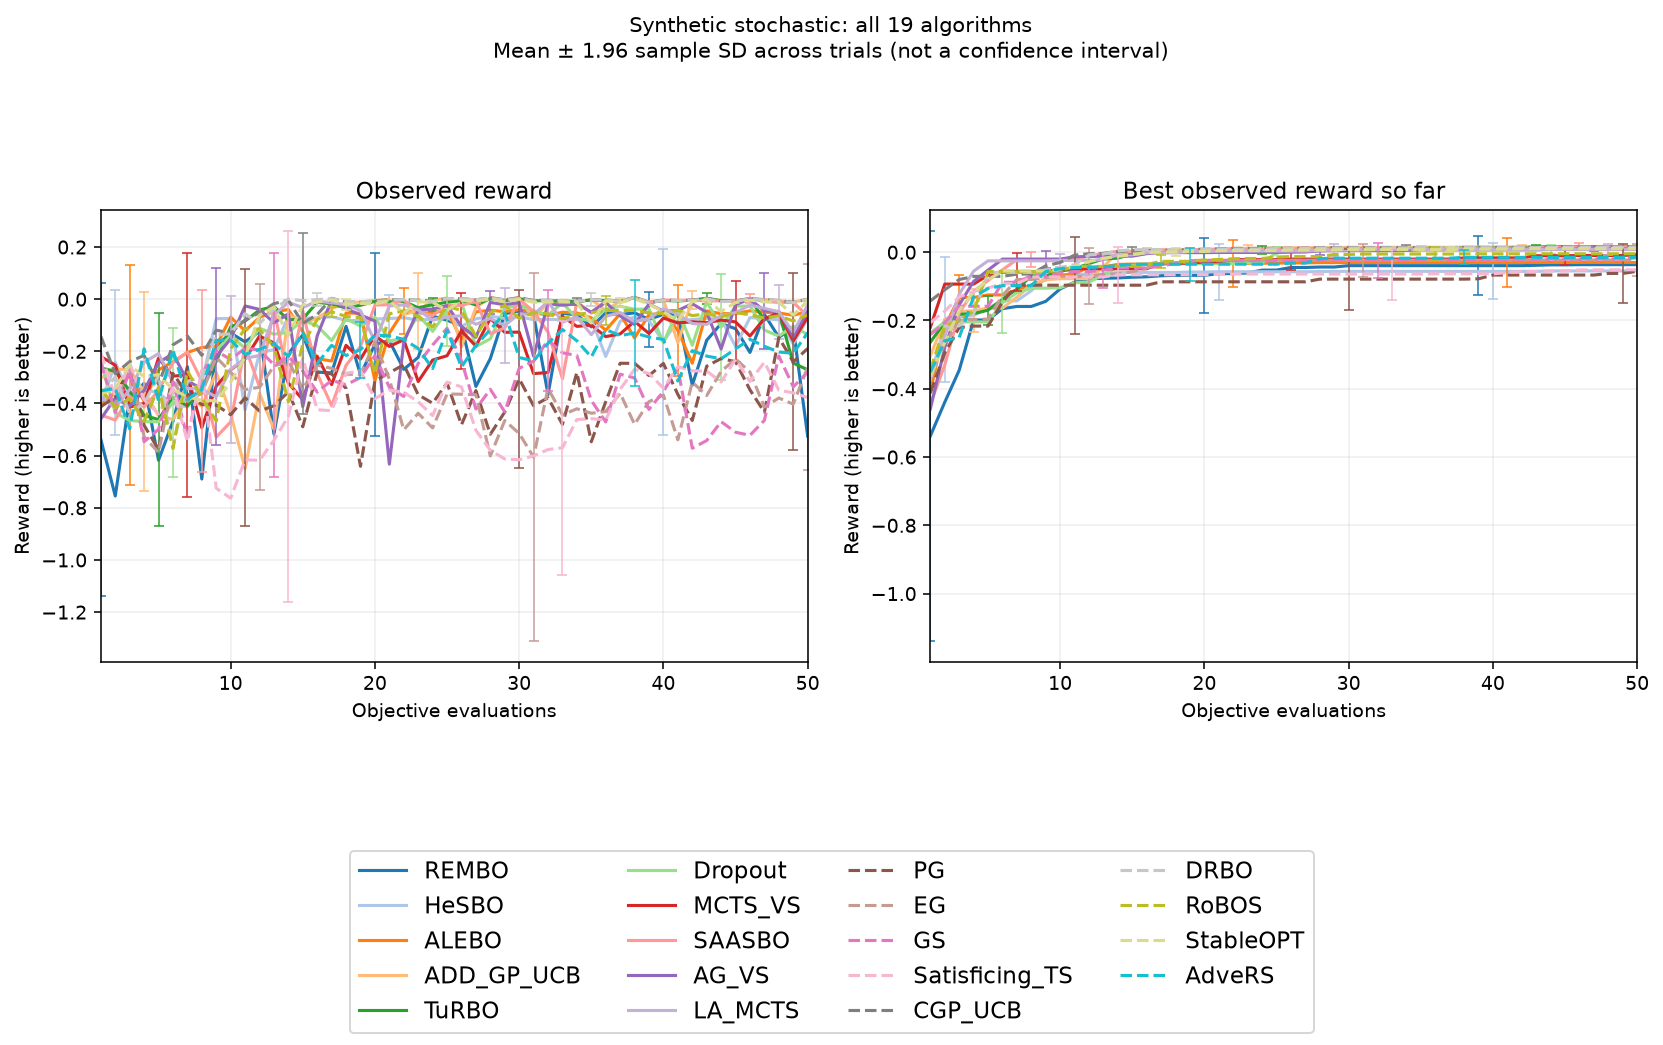

In [ ]:
import basat

seed = basat.set_seed(110, threads=1)
run_directory = basat.new_run_directory("results/last_guide/synthetic_stochastic")
bounds = basat.Bounds(lower=[0.0] * 3, upper=[1.0] * 3)

def stochastic_objective(values):
    target = (0.2, 0.65, 0.4)
    return -sum((x - t) ** 2 for x, t in zip(values, target))

# Fresh, fully explicit configurations for stochastic observations.
# These bounded computation settings are editable examples.
# No setting overrides are hidden behind a profile.
dimension = bounds.dimension
reduced_dimension = min(2, dimension)
constructor_options = {
    'maximize': True,
    'dtype': 'float64',
    'device': 'cpu',
    'plot': False,
    'verbose': False,
    'verbose_setting': False,
    'verbose_iter_by_iter': False,
}

# Isotropic kernels model every input; no active coordinates are given.
action_kernel = basat.KernelConfig(
    name='matern52',
    ard_num_dims=None,
    active_dims=None,
    use_outputscale=True,
    lengthscale_prior=None,
    outputscale_prior=None,
    kwargs={},
)
context_kernel = basat.KernelConfig(
    name='rbf',
    ard_num_dims=None,
    active_dims=None,
    use_outputscale=True,
    lengthscale_prior=None,
    outputscale_prior=None,
    kwargs={},
)
ei = basat.AcquisitionConfig(
    name='EI',
    beta=3.0,
    xi=0.0,
    mc_samples=64,
    seed=seed,
)
ucb = basat.AcquisitionConfig(
    name='UCB',
    beta=3.0,
    xi=0.0,
    mc_samples=64,
    seed=seed,
)
contextual_solver = basat.AcquisitionOptimizerSpec(
    raw_samples=32,
    restarts=2,
    maxiter=50,
    fit_maxiter=50,
    solver_tolerance=1e-06,
)
distributional_solver = basat.ActionOptimizerSpec(
    raw_samples=24,
    restarts=2,
    maxiter=50,
    fit_maxiter=50,
)
robust_solver = basat.MultiStartSolver(
    method='multistart',
)

rembo_config = basat.REMBOConfig(
    embedding_dimension=reduced_dimension,
    finite_candidate_mode='project',
    Y_lower=None,
    Y_upper=None,
    kernel_type='low_dimensional',
    custom_kernel=None,
    acquisition='EI',
    initial_points=8,
    initial_points_sampling_method='sobol',
    batch_size=1,
    q_batch=None,
    lengthscale_lower=0.01,
    lengthscale_upper=50.0,
    initial_lengthscale=None,
    t_sigma=0.002,
    refit_interval=20,
    exploitation_count_limit=5,
    upper_bound_multiplier=0.9,
    seed=seed + 0,
)

hesbo_config = basat.HeSBOConfig(
    embedding_dimension=reduced_dimension,
    finite_candidate_mode='project',
    acquisition=ei,
    initial_points=8,
    initial_points_sampling_method='sobol',
    hash_family='paper',
    batch_size=1,
    q_batch=None,
    seed=seed + 1,
)

alebo_config = basat.ALEBOConfig(
    embedding_dimension=reduced_dimension,
    finite_candidate_mode='project',
    initial_points=8,
    initial_points_sampling_method='sobol',
    acquisition=ei,
    metric_inference='laplace',
    metric_posterior_samples=8,
    feasibility_tolerance=1e-09,
    acquisition_solver='slsqp',
    raw_feasible_samples=64,
    num_restarts=2,
    batch_size=1,
    q_batch=None,
    seed=seed + 2,
)

add_gp_ucb_config = basat.AddGPUCBConfig(
    groups=tuple((i,) for i in range(dimension)),
    maximum_group_size=1,
    learn_decomposition=False,
    decomposition_candidates=None,
    refresh_cycle=25,
    beta=3.0,
    initial_points=8,
    initial_points_sampling_method='sobol',
    component_optimizer=None,
    batch_size=1,
    q_batch=None,
    seed=seed + 3,
)

turbo_config = basat.TuRBOConfig(
    batch_size=1,
    q_batch=None,
    initial_points=8,
    initial_points_sampling_method='sobol',
    length_init=0.8,
    length_min=0.0078125,
    length_max=1.6,
    success_tolerance=3,
    failure_tolerance=None,
    candidate_count=128,
    perturbation_cap=20.0,
    acquisition=ei,
    success_relative_tolerance=0.001,
    noisy_center='posterior_mean',
    max_cholesky_size=2000,
    gp_training_steps=50,
    seed=seed + 4,
)

dropout_config = basat.DropoutConfig(
    active_dimension=reduced_dimension,
    fill_strategy='mix',
    random_fill_probability=0.1,
    beta=3.0,
    acquisition_optimizer=None,
    initial_points=8,
    initial_points_sampling_method='sobol',
    batch_size=1,
    q_batch=None,
    seed=seed + 5,
)

mcts_vs_config = basat.MCTSVSConfig(
    Nv=2,
    Ns=2,
    archive_size=20,
    initial_points=8,
    initial_points_sampling_method='sobol',
    bad_count_limit=5,
    split_threshold=3,
    exploration_constant=0.1,
    inner_optimizer='bo',
    candidate_pool_size=64,
    kernel_lengthscale=0.2,
    acquisition_beta=3.0,
    gp_maxiter=50,
    batch_size=1,
    q_batch=None,
    seed=seed + 6,
)

saasbo_config = basat.SAASBOConfig(
    shrinkage_scale=0.1,
    warmup_steps=64,
    posterior_samples=64,
    thinning=4,
    num_chains=1,
    initial_points=8,
    initial_points_sampling_method='sobol',
    acquisition='EI',
    max_tree_depth=4,
    target_accept_prob=0.8,
    num_restarts=2,
    raw_samples=32,
    mc_samples=32,
    ucb_beta=3.0,
    max_r_hat=1.1,
    min_effective_sample_size=10.0,
    allow_divergences=False,
    batch_size=1,
    q_batch=None,
    seed=seed + 7,
)

ag_vs_config = basat.AG_VSConfig(
    effective_dimension=reduced_dimension,
    sequence_length=2,
    split_groups=2,
    initial_points=8,
    initial_points_sampling_method='sobol',
    acquisition=ucb,
    stopping_threshold=None,
    stopping_delta=None,
    stagnation_patience=None,
    gp_fit_method='mle',
    gp_maxiter=50,
    acquisition_restarts=2,
    acquisition_raw_samples=64,
    batch_size=1,
    q_batch=None,
    seed=seed + 8,
)

la_mcts_config = basat.LAMCTSConfig(
    initial_points=8,
    initial_points_sampling_method='sobol',
    exploration_constant=1.0,
    split_threshold=12,
    min_child_size=3,
    max_depth=20,
    classifier='svm_rbf',
    local_sampler='turbo',
    candidate_pool_size=64,
    max_resampling_attempts=4,
    kernel_lengthscale=0.2,
    acquisition_beta=3.0,
    gp_maxiter=50,
    batch_size=1,
    q_batch=None,
    seed=seed + 9,
)

pg_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=8,
    initial_points_sampling_method='sobol',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 10,
)

eg_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=8,
    initial_points_sampling_method='sobol',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 11,
)

gs_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=8,
    initial_points_sampling_method='sobol',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 12,
)

satisficing_ts_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=8,
    initial_points_sampling_method='sobol',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 13,
)

cgp_ucb_config = basat.CGPUCBConfig(
    action_bounds=bounds,
    action_set=None,
    action_kernel=action_kernel,
    context_kernel=context_kernel,
    kernel_combination='product',
    beta=3.0,
    delta=0.1,
    finite_domain_cardinality=None,
    acquisition_optimizer=contextual_solver,
    initial_points=8,
    batch_size=1,
    q_batch=None,
    seed=seed + 14,
)

drbo_config = basat.DRBOConfig(
    context_kernel=context_kernel,
    action_kernel=action_kernel,
    beta=3.0,
    ambiguity_metric='mmd',
    inner_solver='slsqp',
    action_optimizer=distributional_solver,
    distribution_grid=None,
    enumeration_resolution=20,
    initial_points=8,
    feasibility_tolerance=1e-08,
    optimizer_tolerance=1e-06,
    batch_size=1,
    q_batch=None,
    seed=seed + 15,
)

robos_config = basat.RoBOSConfig(
    aspiration=-0.1,
    context_kernel=context_kernel,
    action_kernel=action_kernel,
    joint_kernel_combination='product',
    joint_kernel=None,
    beta=3.0,
    simplex_solver='slsqp',
    distribution_floor=0.0,
    distribution_grid=None,
    enumeration_resolution=20,
    action_raw_samples=24,
    action_restarts=2,
    action_maxiter=50,
    initial_points=8,
    fit_maxiter=50,
    feasibility_tolerance=1e-08,
    optimizer_tolerance=1e-06,
    batch_size=1,
    q_batch=None,
    seed=seed + 16,
)

stableopt_config = basat.StableOPTConfig(
    perturbation_radius=0.08,
    distance=basat.L2Distance(),
    beta=3.0,
    inner_solver=robust_solver,
    outer_solver=robust_solver,
    inner_raw_samples=16,
    outer_raw_samples=32,
    inner_restarts=2,
    outer_restarts=2,
    solver_tolerance=1e-06,
    initial_points=8,
    fit_maxiter=50,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 17,
)

advers_config = basat.AdveRSConfig(
    variant='RS1',
    aspiration=-0.1,
    p=1.0,
    beta=3.0,
    perturbation_domain=basat.FullDomainPerturbations(norm='l2', distance_floor=1e-8),
    candidate_solver=robust_solver,
    inner_solver=robust_solver,
    decision_model='ucb',
    outer_raw_samples=32,
    inner_raw_samples=16,
    radius_bisection_steps=8,
    solver_tolerance=1e-06,
    initial_points=8,
    fit_maxiter=50,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 18,
)

# SAASBO uses actual NUTS. Short chains can report poor ESS/divergences.
# Warnings retain finite draws; they do not certify convergence.
# For inference increase warmup/draws and use at least two chains.
algorithms = {
    'REMBO': basat.REMBO(
        bounds=bounds, config=rembo_config,
        **constructor_options,
    ),
    'HeSBO': basat.HeSBO(
        bounds=bounds, config=hesbo_config,
        **constructor_options,
    ),
    'ALEBO': basat.ALEBO(
        bounds=bounds, config=alebo_config,
        **constructor_options,
    ),
    'ADD_GP_UCB': basat.ADD_GP_UCB(
        bounds=bounds, config=add_gp_ucb_config,
        **constructor_options,
    ),
    'TuRBO': basat.TuRBO(
        bounds=bounds, config=turbo_config,
        **constructor_options,
    ),
    'Dropout': basat.Dropout(
        bounds=bounds, config=dropout_config,
        **constructor_options,
    ),
    'MCTS_VS': basat.MCTS_VS(
        bounds=bounds, config=mcts_vs_config,
        **constructor_options,
    ),
    'SAASBO': basat.SAASBO(
        bounds=bounds, config=saasbo_config,
        **constructor_options,
        diagnostic_policy='warn',
        jit_compile=True,
        mcmc_num_threads=1,
    ),
    'AG_VS': basat.AG_VS(
        bounds=bounds, config=ag_vs_config,
        **constructor_options,
    ),
    'LA_MCTS': basat.LA_MCTS(
        bounds=bounds, config=la_mcts_config,
        **constructor_options,
    ),
    'PG': basat.PG(
        bounds=bounds, config=pg_config,
        **constructor_options,
    ),
    'EG': basat.EG(
        bounds=bounds, config=eg_config,
        **constructor_options,
    ),
    'GS': basat.GS(
        bounds=bounds, config=gs_config,
        **constructor_options,
    ),
    'Satisficing_TS': basat.Satisficing_TS(
        bounds=bounds, config=satisficing_ts_config,
        **constructor_options,
    ),
    'CGP_UCB': basat.CGP_UCB(
        bounds=bounds, config=cgp_ucb_config,
        **constructor_options,
    ),
    'DRBO': basat.DRBO(
        bounds=bounds, config=drbo_config,
        **constructor_options,
    ),
    'RoBOS': basat.RoBOS(
        bounds=bounds, config=robos_config,
        **constructor_options,
    ),
    'StableOPT': basat.StableOPT(
        bounds=bounds, config=stableopt_config,
        **constructor_options,
    ),
    'AdveRS': basat.AdveRS(
        bounds=bounds, config=advers_config,
        **constructor_options,
    ),
}
print('Configured algorithms:', len(algorithms), list(algorithms))


environment = basat.StochasticEnvironment(
    bounds=bounds, function=stochastic_objective,
    dataset=None, previous_data=None, dtype="float64", device="cpu",
    noise_std=0.01, noise_fn=None, add_noise_to_data=False,
    allow_repeated_actions=False, data_row_selection="first", seed=seed,
)

assert set(algorithms) == set(basat.algorithm_names())
print("Algorithms submitted:", len(algorithms))
print("Names:", list(algorithms))
experiment = basat.Experiment(
    environment=environment, algorithm=algorithms,
    output_directory=run_directory, resume=False, save_every=10,
    stopping_rule=None,
)
result = experiment.run(
    trials=5, max_evaluations=50, plot=False, show=False, progress=True,
)
print(experiment.summary())
print(experiment.diagnostics())
figure = basat.plot(
    experiment, kind="comparison", title="Synthetic stochastic: all 19 algorithms",
    titles=("Observed reward", "Best observed reward so far"),
    xlabel="Objective evaluations", ylabel="Reward (higher is better)",
    figsize=(12.0, 7.5), xlim=(1, 50), grid=True,
    legend=True, legend_columns=4, legend_fontsize=12.0,
    save_path=basat.join_path(run_directory, "all_algorithms.png"),
    dpi=180, show=True,
)
print("Saved results:", run_directory)

## 1.2 Contextual: all algorithms

        This block defines its own objective, providers, settings, environment,
        and results directory. Every method is reconstructed with explicit
        settings for this environment. Run the complete block independently.

Saved-result refresh (no optimization was executed).
Source: results/last_guide/synthetic_contextual/run_afer_4e9/results.json
Trials: 5/5; limits: {'max_evaluations': 50, 'max_rounds': None}
Algorithm | evaluations per trial | final mean best reward | failures
REMBO | [50, 50, 50, 50, 50] | -0.038469907 | 0
HeSBO | [50, 50, 50, 50, 50] | -0.02335136 | 0
ALEBO | [50, 50, 50, 50, 50] | -0.025897367 | 0
ADD_GP_UCB | [50, 50, 50, 50, 50] | -0.041991983 | 0
TuRBO | [50, 50, 50, 50, 50] | -0.017621211 | 0
Dropout | [50, 50, 50, 50, 50] | -0.030845763 | 0
MCTS_VS | [50, 50, 50, 50, 50] | -0.037111047 | 0
SAASBO | [50, 50, 50, 50, 50] | -0.021687364 | 0
AG_VS | [50, 50, 50, 50, 50] | -0.017438459 | 0
LA_MCTS | [50, 50, 50, 50, 50] | -0.034880386 | 0
PG | [50, 50, 50, 50, 50] | -0.0797253 | 0
EG | [50, 50, 50, 50, 50] | -0.013252706 | 0
GS | [50, 50, 50, 50, 50] | -0.033458616 | 0
Satisficing_TS | [50, 50, 50, 50, 50] | -0.033770236 | 0
CGP_UCB | [50, 50, 50, 50, 50] | 0.014661133 | 0
DRBO | [

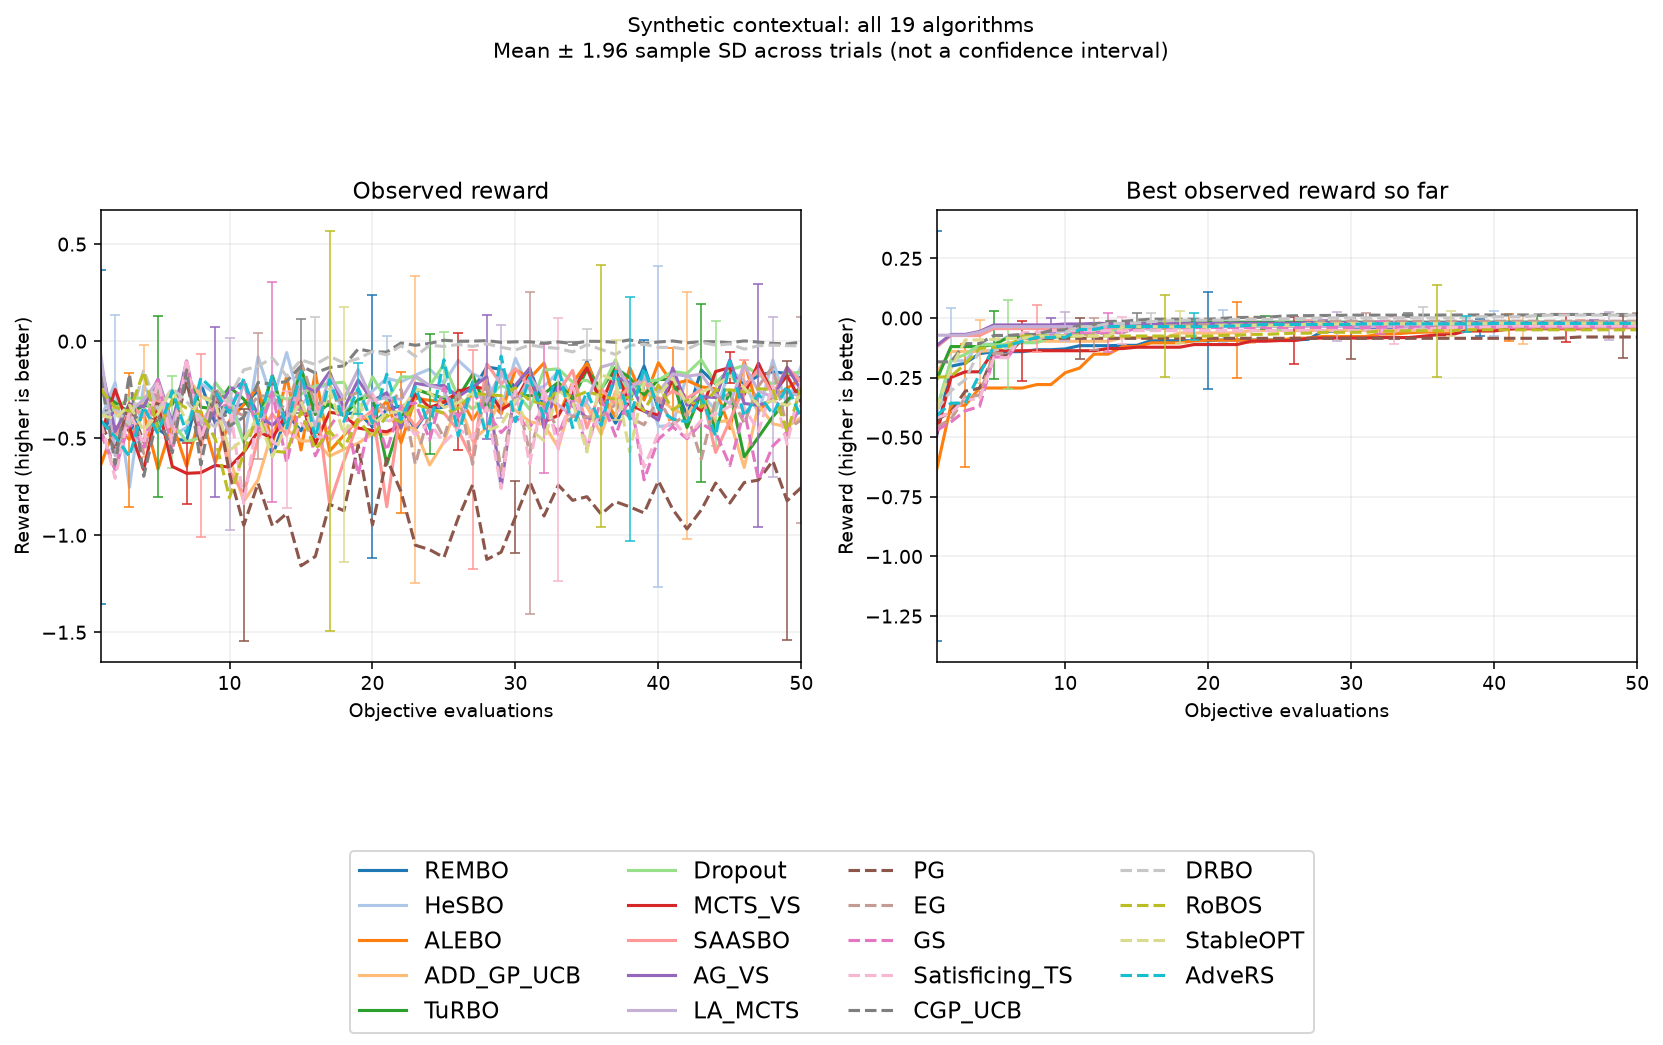

In [ ]:
import basat

seed = basat.set_seed(111, threads=1)
run_directory = basat.new_run_directory("results/last_guide/synthetic_contextual")
bounds = basat.Bounds(lower=[0.0] * 3, upper=[1.0] * 3)

def contextual_objective(values, context):
    c = float(context[0])
    target = (0.2 + 0.5 * c, 0.75 - 0.4 * c, 0.4)
    return -sum((x - t) ** 2 for x, t in zip(values, target))


def reveal_context(*, round_index, generator):
    return [float(round_index % 2)]

# Fresh, fully explicit configurations for contextual observations.
# These bounded computation settings are editable examples.
# No setting overrides are hidden behind a profile.
dimension = bounds.dimension
reduced_dimension = min(2, dimension)
constructor_options = {
    'maximize': True,
    'dtype': 'float64',
    'device': 'cpu',
    'plot': False,
    'verbose': False,
    'verbose_setting': False,
    'verbose_iter_by_iter': False,
}

# Isotropic kernels model every input; no active coordinates are given.
action_kernel = basat.KernelConfig(
    name='rbf',
    ard_num_dims=None,
    active_dims=None,
    use_outputscale=True,
    lengthscale_prior=None,
    outputscale_prior=None,
    kwargs={},
)
context_kernel = basat.KernelConfig(
    name='rbf',
    ard_num_dims=None,
    active_dims=None,
    use_outputscale=True,
    lengthscale_prior=None,
    outputscale_prior=None,
    kwargs={},
)
ei = basat.AcquisitionConfig(
    name='EI',
    beta=2.5,
    xi=0.0,
    mc_samples=64,
    seed=seed,
)
ucb = basat.AcquisitionConfig(
    name='UCB',
    beta=2.5,
    xi=0.0,
    mc_samples=64,
    seed=seed,
)
contextual_solver = basat.AcquisitionOptimizerSpec(
    raw_samples=32,
    restarts=2,
    maxiter=50,
    fit_maxiter=50,
    solver_tolerance=1e-06,
)
distributional_solver = basat.ActionOptimizerSpec(
    raw_samples=24,
    restarts=2,
    maxiter=50,
    fit_maxiter=50,
)
robust_solver = basat.MultiStartSolver(
    method='multistart',
)

rembo_config = basat.REMBOConfig(
    embedding_dimension=reduced_dimension,
    finite_candidate_mode='project',
    Y_lower=None,
    Y_upper=None,
    kernel_type='low_dimensional',
    custom_kernel=None,
    acquisition='EI',
    initial_points=9,
    initial_points_sampling_method='uniform',
    batch_size=1,
    q_batch=None,
    lengthscale_lower=0.01,
    lengthscale_upper=50.0,
    initial_lengthscale=None,
    t_sigma=0.002,
    refit_interval=20,
    exploitation_count_limit=5,
    upper_bound_multiplier=0.9,
    seed=seed + 0,
)

hesbo_config = basat.HeSBOConfig(
    embedding_dimension=reduced_dimension,
    finite_candidate_mode='project',
    acquisition=ei,
    initial_points=9,
    initial_points_sampling_method='uniform',
    hash_family='paper',
    batch_size=1,
    q_batch=None,
    seed=seed + 1,
)

alebo_config = basat.ALEBOConfig(
    embedding_dimension=reduced_dimension,
    finite_candidate_mode='project',
    initial_points=9,
    initial_points_sampling_method='uniform',
    acquisition=ei,
    metric_inference='laplace',
    metric_posterior_samples=8,
    feasibility_tolerance=1e-09,
    acquisition_solver='slsqp',
    raw_feasible_samples=64,
    num_restarts=2,
    batch_size=1,
    q_batch=None,
    seed=seed + 2,
)

add_gp_ucb_config = basat.AddGPUCBConfig(
    groups=tuple((i,) for i in range(dimension)),
    maximum_group_size=1,
    learn_decomposition=False,
    decomposition_candidates=None,
    refresh_cycle=25,
    beta=2.5,
    initial_points=9,
    initial_points_sampling_method='uniform',
    component_optimizer=None,
    batch_size=1,
    q_batch=None,
    seed=seed + 3,
)

turbo_config = basat.TuRBOConfig(
    batch_size=1,
    q_batch=None,
    initial_points=9,
    initial_points_sampling_method='uniform',
    length_init=0.8,
    length_min=0.0078125,
    length_max=1.6,
    success_tolerance=3,
    failure_tolerance=None,
    candidate_count=128,
    perturbation_cap=20.0,
    acquisition=ei,
    success_relative_tolerance=0.001,
    noisy_center='posterior_mean',
    max_cholesky_size=2000,
    gp_training_steps=50,
    seed=seed + 4,
)

dropout_config = basat.DropoutConfig(
    active_dimension=reduced_dimension,
    fill_strategy='mix',
    random_fill_probability=0.1,
    beta=2.5,
    acquisition_optimizer=None,
    initial_points=9,
    initial_points_sampling_method='uniform',
    batch_size=1,
    q_batch=None,
    seed=seed + 5,
)

mcts_vs_config = basat.MCTSVSConfig(
    Nv=2,
    Ns=2,
    archive_size=20,
    initial_points=9,
    initial_points_sampling_method='uniform',
    bad_count_limit=5,
    split_threshold=3,
    exploration_constant=0.1,
    inner_optimizer='bo',
    candidate_pool_size=64,
    kernel_lengthscale=0.2,
    acquisition_beta=2.5,
    gp_maxiter=50,
    batch_size=1,
    q_batch=None,
    seed=seed + 6,
)

saasbo_config = basat.SAASBOConfig(
    shrinkage_scale=0.1,
    warmup_steps=64,
    posterior_samples=64,
    thinning=4,
    num_chains=1,
    initial_points=9,
    initial_points_sampling_method='uniform',
    acquisition='EI',
    max_tree_depth=4,
    target_accept_prob=0.8,
    num_restarts=2,
    raw_samples=32,
    mc_samples=32,
    ucb_beta=2.5,
    max_r_hat=1.1,
    min_effective_sample_size=10.0,
    allow_divergences=False,
    batch_size=1,
    q_batch=None,
    seed=seed + 7,
)

ag_vs_config = basat.AG_VSConfig(
    effective_dimension=reduced_dimension,
    sequence_length=2,
    split_groups=2,
    initial_points=9,
    initial_points_sampling_method='uniform',
    acquisition=ucb,
    stopping_threshold=None,
    stopping_delta=None,
    stagnation_patience=None,
    gp_fit_method='mle',
    gp_maxiter=50,
    acquisition_restarts=2,
    acquisition_raw_samples=64,
    batch_size=1,
    q_batch=None,
    seed=seed + 8,
)

la_mcts_config = basat.LAMCTSConfig(
    initial_points=9,
    initial_points_sampling_method='uniform',
    exploration_constant=1.0,
    split_threshold=12,
    min_child_size=3,
    max_depth=20,
    classifier='svm_rbf',
    local_sampler='turbo',
    candidate_pool_size=64,
    max_resampling_attempts=4,
    kernel_lengthscale=0.2,
    acquisition_beta=2.5,
    gp_maxiter=50,
    batch_size=1,
    q_batch=None,
    seed=seed + 9,
)

pg_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=9,
    initial_points_sampling_method='uniform',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 10,
)

eg_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=9,
    initial_points_sampling_method='uniform',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 11,
)

gs_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=9,
    initial_points_sampling_method='uniform',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 12,
)

satisficing_ts_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=9,
    initial_points_sampling_method='uniform',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 13,
)

cgp_ucb_config = basat.CGPUCBConfig(
    action_bounds=bounds,
    action_set=None,
    action_kernel=action_kernel,
    context_kernel=context_kernel,
    kernel_combination='product',
    beta=2.5,
    delta=0.1,
    finite_domain_cardinality=None,
    acquisition_optimizer=contextual_solver,
    initial_points=9,
    batch_size=1,
    q_batch=None,
    seed=seed + 14,
)

drbo_config = basat.DRBOConfig(
    context_kernel=context_kernel,
    action_kernel=action_kernel,
    beta=2.5,
    ambiguity_metric='mmd',
    inner_solver='slsqp',
    action_optimizer=distributional_solver,
    distribution_grid=None,
    enumeration_resolution=20,
    initial_points=9,
    feasibility_tolerance=1e-08,
    optimizer_tolerance=1e-06,
    batch_size=1,
    q_batch=None,
    seed=seed + 15,
)

robos_config = basat.RoBOSConfig(
    aspiration=-0.1,
    context_kernel=context_kernel,
    action_kernel=action_kernel,
    joint_kernel_combination='product',
    joint_kernel=None,
    beta=2.5,
    simplex_solver='slsqp',
    distribution_floor=0.0,
    distribution_grid=None,
    enumeration_resolution=20,
    action_raw_samples=24,
    action_restarts=2,
    action_maxiter=50,
    initial_points=9,
    fit_maxiter=50,
    feasibility_tolerance=1e-08,
    optimizer_tolerance=1e-06,
    batch_size=1,
    q_batch=None,
    seed=seed + 16,
)

stableopt_config = basat.StableOPTConfig(
    perturbation_radius=0.08,
    distance=basat.L2Distance(),
    beta=2.5,
    inner_solver=robust_solver,
    outer_solver=robust_solver,
    inner_raw_samples=16,
    outer_raw_samples=32,
    inner_restarts=2,
    outer_restarts=2,
    solver_tolerance=1e-06,
    initial_points=9,
    fit_maxiter=50,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 17,
)

advers_config = basat.AdveRSConfig(
    variant='RS1',
    aspiration=-0.1,
    p=1.0,
    beta=2.5,
    perturbation_domain=basat.FullDomainPerturbations(norm='l2', distance_floor=1e-8),
    candidate_solver=robust_solver,
    inner_solver=robust_solver,
    decision_model='ucb',
    outer_raw_samples=32,
    inner_raw_samples=16,
    radius_bisection_steps=8,
    solver_tolerance=1e-06,
    initial_points=9,
    fit_maxiter=50,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 18,
)

# SAASBO uses actual NUTS. Short chains can report poor ESS/divergences.
# Warnings retain finite draws; they do not certify convergence.
# For inference increase warmup/draws and use at least two chains.
algorithms = {
    'REMBO': basat.REMBO(
        bounds=bounds, config=rembo_config,
        **constructor_options,
    ),
    'HeSBO': basat.HeSBO(
        bounds=bounds, config=hesbo_config,
        **constructor_options,
    ),
    'ALEBO': basat.ALEBO(
        bounds=bounds, config=alebo_config,
        **constructor_options,
    ),
    'ADD_GP_UCB': basat.ADD_GP_UCB(
        bounds=bounds, config=add_gp_ucb_config,
        **constructor_options,
    ),
    'TuRBO': basat.TuRBO(
        bounds=bounds, config=turbo_config,
        **constructor_options,
    ),
    'Dropout': basat.Dropout(
        bounds=bounds, config=dropout_config,
        **constructor_options,
    ),
    'MCTS_VS': basat.MCTS_VS(
        bounds=bounds, config=mcts_vs_config,
        **constructor_options,
    ),
    'SAASBO': basat.SAASBO(
        bounds=bounds, config=saasbo_config,
        **constructor_options,
        diagnostic_policy='warn',
        jit_compile=True,
        mcmc_num_threads=1,
    ),
    'AG_VS': basat.AG_VS(
        bounds=bounds, config=ag_vs_config,
        **constructor_options,
    ),
    'LA_MCTS': basat.LA_MCTS(
        bounds=bounds, config=la_mcts_config,
        **constructor_options,
    ),
    'PG': basat.PG(
        bounds=bounds, config=pg_config,
        **constructor_options,
    ),
    'EG': basat.EG(
        bounds=bounds, config=eg_config,
        **constructor_options,
    ),
    'GS': basat.GS(
        bounds=bounds, config=gs_config,
        **constructor_options,
    ),
    'Satisficing_TS': basat.Satisficing_TS(
        bounds=bounds, config=satisficing_ts_config,
        **constructor_options,
    ),
    'CGP_UCB': basat.CGP_UCB(
        bounds=bounds, config=cgp_ucb_config,
        **constructor_options,
    ),
    'DRBO': basat.DRBO(
        bounds=bounds, config=drbo_config,
        **constructor_options,
    ),
    'RoBOS': basat.RoBOS(
        bounds=bounds, config=robos_config,
        **constructor_options,
    ),
    'StableOPT': basat.StableOPT(
        bounds=bounds, config=stableopt_config,
        **constructor_options,
    ),
    'AdveRS': basat.AdveRS(
        bounds=bounds, config=advers_config,
        **constructor_options,
    ),
}
print('Configured algorithms:', len(algorithms), list(algorithms))


environment = basat.ContextualEnvironment(
    bounds=bounds, function=contextual_objective,
    context_provider=reveal_context,
    dataset=None, previous_data=None, dtype="float64", device="cpu",
    noise_std=0.01, noise_fn=None, add_noise_to_data=False,
    allow_repeated_actions=False, data_row_selection="first", seed=seed,
)

assert set(algorithms) == set(basat.algorithm_names())
print("Algorithms submitted:", len(algorithms))
print("Names:", list(algorithms))
experiment = basat.Experiment(
    environment=environment, algorithm=algorithms,
    output_directory=run_directory, resume=False, save_every=10,
    stopping_rule=None,
)
result = experiment.run(
    trials=5, max_evaluations=50, plot=False, show=False, progress=True,
)
print(experiment.summary())
print(experiment.diagnostics())
figure = basat.plot(
    experiment, kind="comparison", title="Synthetic contextual: all 19 algorithms",
    titles=("Observed reward", "Best observed reward so far"),
    xlabel="Objective evaluations", ylabel="Reward (higher is better)",
    figsize=(12.0, 7.5), xlim=(1, 50), grid=True,
    legend=True, legend_columns=4, legend_fontsize=12.0,
    save_path=basat.join_path(run_directory, "all_algorithms.png"),
    dpi=180, show=True,
)
print("Saved results:", run_directory)

## 1.3 Distributional: all algorithms

        This block defines its own objective, providers, settings, environment,
        and results directory. Every method is reconstructed with explicit
        settings for this environment. Run the complete block independently.

Saved-result refresh (no optimization was executed).
Source: results/last_guide/synthetic_distributional/run_9g6_fprs/results.json
Trials: 5/5; limits: {'max_evaluations': 50, 'max_rounds': None}
Algorithm | evaluations per trial | final mean best reward | failures
REMBO | [50, 50, 50, 50, 50] | 0.0065654118 | 0
HeSBO | [50, 50, 50, 50, 50] | 0.0303242 | 0
ALEBO | [50, 50, 50, 50, 50] | 0.023973059 | 0
ADD_GP_UCB | [50, 50, 50, 50, 50] | 0.053510693 | 0
TuRBO | [50, 50, 50, 50, 50] | 0.025572192 | 0
Dropout | [50, 50, 50, 50, 50] | 0.039349369 | 0
MCTS_VS | [50, 50, 50, 50, 50] | 0.039916003 | 0
SAASBO | [50, 50, 50, 50, 50] | 0.055273367 | 0
AG_VS | [50, 50, 50, 50, 50] | 0.044804688 | 0
LA_MCTS | [50, 50, 50, 50, 50] | 0.035250981 | 0
PG | [50, 50, 50, 50, 50] | -0.0089023057 | 0
EG | [50, 50, 50, 50, 50] | 0.022438961 | 0
GS | [50, 50, 50, 50, 50] | 0.011525091 | 0
Satisficing_TS | [50, 50, 50, 50, 50] | 0.025894152 | 0
CGP_UCB | [50, 50, 50, 50, 50] | 0.062909364 | 0
DRBO | [50, 50

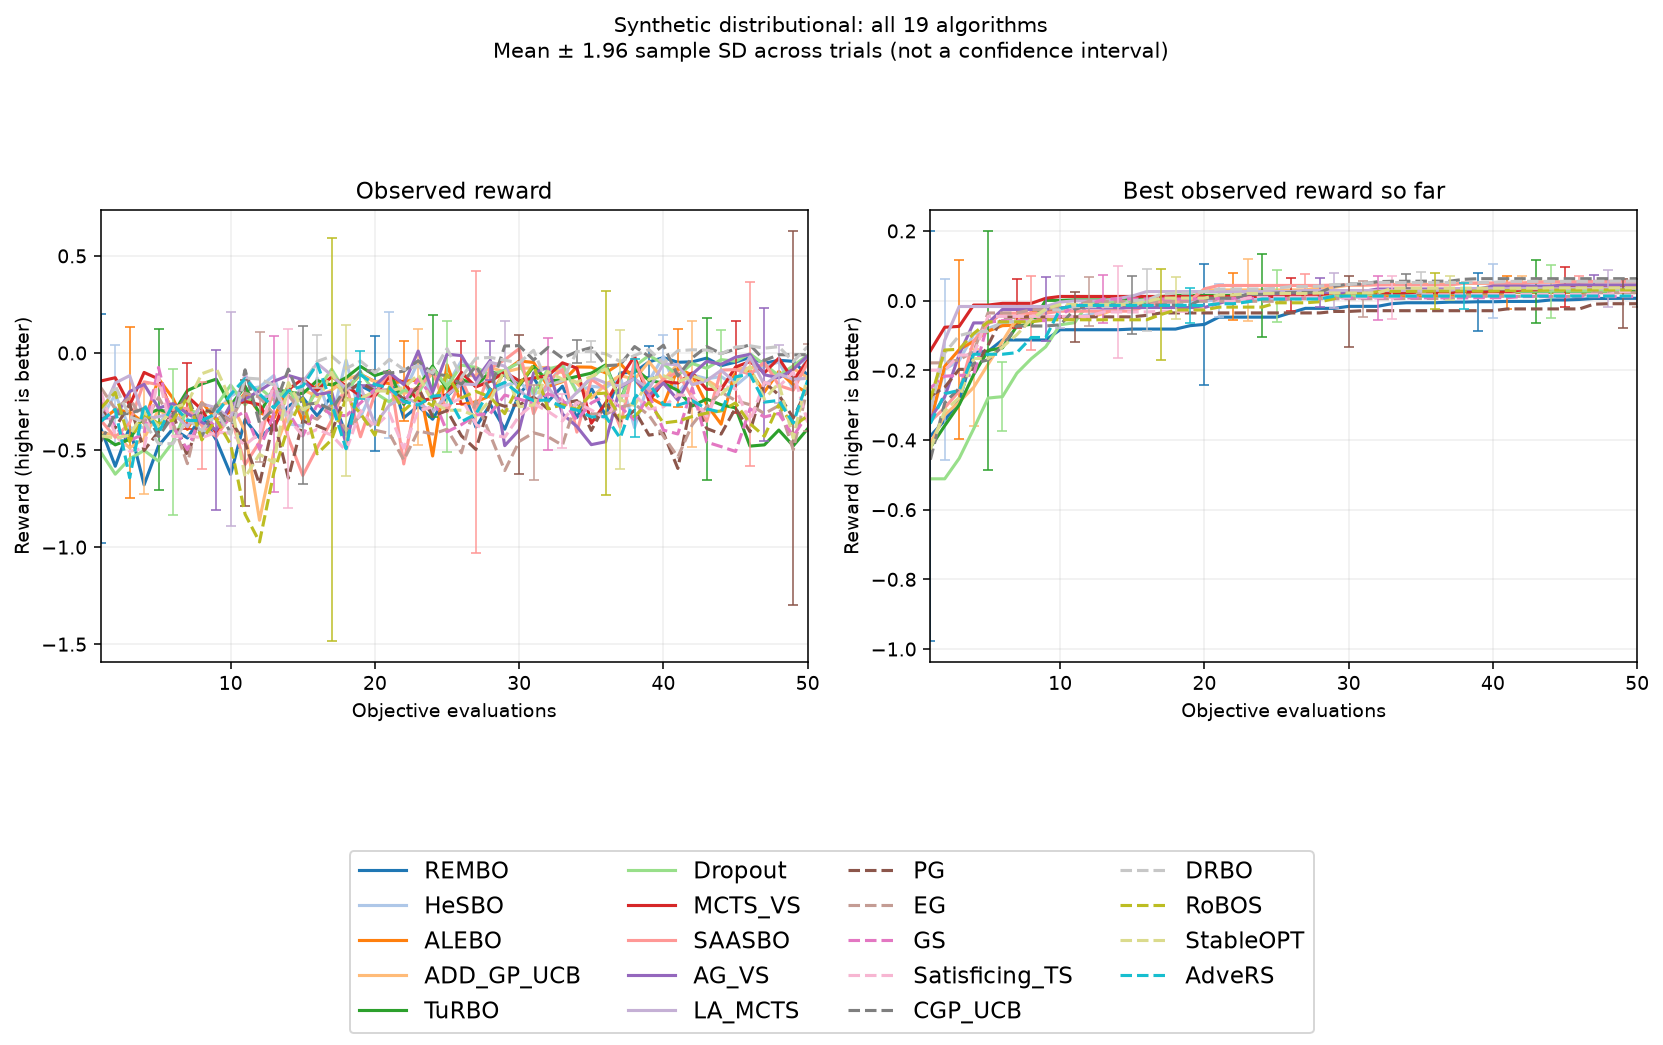

In [ ]:
import basat

seed = basat.set_seed(112, threads=1)
run_directory = basat.new_run_directory("results/last_guide/synthetic_distributional")
bounds = basat.Bounds(lower=[0.0] * 3, upper=[1.0] * 3)
contexts = basat.array([[0.0], [1.0]], dtype="float64")

def distributional_objective(values, context):
    c = float(context[0])
    target = (0.25 + 0.35 * c, 0.6 - 0.2 * c, 0.3)
    distance = sum((x - t) ** 2 for x, t in zip(values, target))
    wave = 0.08 * basat.sin(6.0 * 3.141592653589793 * values[0])
    return float(-distance + wave)

# Fresh, fully explicit configurations for distributional observations.
# These bounded computation settings are editable examples.
# No setting overrides are hidden behind a profile.
dimension = bounds.dimension
reduced_dimension = min(2, dimension)
constructor_options = {
    'maximize': True,
    'dtype': 'float64',
    'device': 'cpu',
    'plot': False,
    'verbose': False,
    'verbose_setting': False,
    'verbose_iter_by_iter': False,
}

# Isotropic kernels model every input; no active coordinates are given.
action_kernel = basat.KernelConfig(
    name='matern32',
    ard_num_dims=None,
    active_dims=None,
    use_outputscale=True,
    lengthscale_prior=None,
    outputscale_prior=None,
    kwargs={},
)
context_kernel = basat.KernelConfig(
    name='rbf',
    ard_num_dims=None,
    active_dims=None,
    use_outputscale=True,
    lengthscale_prior=None,
    outputscale_prior=None,
    kwargs={},
)
ei = basat.AcquisitionConfig(
    name='EI',
    beta=3.5,
    xi=0.0,
    mc_samples=64,
    seed=seed,
)
ucb = basat.AcquisitionConfig(
    name='UCB',
    beta=3.5,
    xi=0.0,
    mc_samples=64,
    seed=seed,
)
contextual_solver = basat.AcquisitionOptimizerSpec(
    raw_samples=32,
    restarts=2,
    maxiter=50,
    fit_maxiter=50,
    solver_tolerance=1e-06,
)
distributional_solver = basat.ActionOptimizerSpec(
    raw_samples=24,
    restarts=2,
    maxiter=50,
    fit_maxiter=50,
)
robust_solver = basat.MultiStartSolver(
    method='multistart',
)

rembo_config = basat.REMBOConfig(
    embedding_dimension=reduced_dimension,
    finite_candidate_mode='project',
    Y_lower=None,
    Y_upper=None,
    kernel_type='low_dimensional',
    custom_kernel=None,
    acquisition='EI',
    initial_points=10,
    initial_points_sampling_method='sobol',
    batch_size=1,
    q_batch=None,
    lengthscale_lower=0.01,
    lengthscale_upper=50.0,
    initial_lengthscale=None,
    t_sigma=0.002,
    refit_interval=20,
    exploitation_count_limit=5,
    upper_bound_multiplier=0.9,
    seed=seed + 0,
)

hesbo_config = basat.HeSBOConfig(
    embedding_dimension=reduced_dimension,
    finite_candidate_mode='project',
    acquisition=ei,
    initial_points=10,
    initial_points_sampling_method='sobol',
    hash_family='paper',
    batch_size=1,
    q_batch=None,
    seed=seed + 1,
)

alebo_config = basat.ALEBOConfig(
    embedding_dimension=reduced_dimension,
    finite_candidate_mode='project',
    initial_points=10,
    initial_points_sampling_method='sobol',
    acquisition=ei,
    metric_inference='laplace',
    metric_posterior_samples=8,
    feasibility_tolerance=1e-09,
    acquisition_solver='slsqp',
    raw_feasible_samples=64,
    num_restarts=2,
    batch_size=1,
    q_batch=None,
    seed=seed + 2,
)

add_gp_ucb_config = basat.AddGPUCBConfig(
    groups=tuple((i,) for i in range(dimension)),
    maximum_group_size=1,
    learn_decomposition=False,
    decomposition_candidates=None,
    refresh_cycle=25,
    beta=3.5,
    initial_points=10,
    initial_points_sampling_method='sobol',
    component_optimizer=None,
    batch_size=1,
    q_batch=None,
    seed=seed + 3,
)

turbo_config = basat.TuRBOConfig(
    batch_size=1,
    q_batch=None,
    initial_points=10,
    initial_points_sampling_method='sobol',
    length_init=0.8,
    length_min=0.0078125,
    length_max=1.6,
    success_tolerance=3,
    failure_tolerance=None,
    candidate_count=128,
    perturbation_cap=20.0,
    acquisition=ei,
    success_relative_tolerance=0.001,
    noisy_center='posterior_mean',
    max_cholesky_size=2000,
    gp_training_steps=50,
    seed=seed + 4,
)

dropout_config = basat.DropoutConfig(
    active_dimension=reduced_dimension,
    fill_strategy='mix',
    random_fill_probability=0.1,
    beta=3.5,
    acquisition_optimizer=None,
    initial_points=10,
    initial_points_sampling_method='sobol',
    batch_size=1,
    q_batch=None,
    seed=seed + 5,
)

mcts_vs_config = basat.MCTSVSConfig(
    Nv=2,
    Ns=2,
    archive_size=20,
    initial_points=10,
    initial_points_sampling_method='sobol',
    bad_count_limit=5,
    split_threshold=3,
    exploration_constant=0.1,
    inner_optimizer='bo',
    candidate_pool_size=64,
    kernel_lengthscale=0.2,
    acquisition_beta=3.5,
    gp_maxiter=50,
    batch_size=1,
    q_batch=None,
    seed=seed + 6,
)

saasbo_config = basat.SAASBOConfig(
    shrinkage_scale=0.1,
    warmup_steps=64,
    posterior_samples=64,
    thinning=4,
    num_chains=1,
    initial_points=10,
    initial_points_sampling_method='sobol',
    acquisition='EI',
    max_tree_depth=4,
    target_accept_prob=0.8,
    num_restarts=2,
    raw_samples=32,
    mc_samples=32,
    ucb_beta=3.5,
    max_r_hat=1.1,
    min_effective_sample_size=10.0,
    allow_divergences=False,
    batch_size=1,
    q_batch=None,
    seed=seed + 7,
)

ag_vs_config = basat.AG_VSConfig(
    effective_dimension=reduced_dimension,
    sequence_length=2,
    split_groups=2,
    initial_points=10,
    initial_points_sampling_method='sobol',
    acquisition=ucb,
    stopping_threshold=None,
    stopping_delta=None,
    stagnation_patience=None,
    gp_fit_method='mle',
    gp_maxiter=50,
    acquisition_restarts=2,
    acquisition_raw_samples=64,
    batch_size=1,
    q_batch=None,
    seed=seed + 8,
)

la_mcts_config = basat.LAMCTSConfig(
    initial_points=10,
    initial_points_sampling_method='sobol',
    exploration_constant=1.0,
    split_threshold=12,
    min_child_size=3,
    max_depth=20,
    classifier='svm_rbf',
    local_sampler='turbo',
    candidate_pool_size=64,
    max_resampling_attempts=4,
    kernel_lengthscale=0.2,
    acquisition_beta=3.5,
    gp_maxiter=50,
    batch_size=1,
    q_batch=None,
    seed=seed + 9,
)

pg_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=10,
    initial_points_sampling_method='sobol',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 10,
)

eg_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=10,
    initial_points_sampling_method='sobol',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 11,
)

gs_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=10,
    initial_points_sampling_method='sobol',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 12,
)

satisficing_ts_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=10,
    initial_points_sampling_method='sobol',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 13,
)

cgp_ucb_config = basat.CGPUCBConfig(
    action_bounds=bounds,
    action_set=None,
    action_kernel=action_kernel,
    context_kernel=context_kernel,
    kernel_combination='product',
    beta=3.5,
    delta=0.1,
    finite_domain_cardinality=None,
    acquisition_optimizer=contextual_solver,
    initial_points=10,
    batch_size=1,
    q_batch=None,
    seed=seed + 14,
)

drbo_config = basat.DRBOConfig(
    context_kernel=context_kernel,
    action_kernel=action_kernel,
    beta=3.5,
    ambiguity_metric='mmd',
    inner_solver='slsqp',
    action_optimizer=distributional_solver,
    distribution_grid=None,
    enumeration_resolution=20,
    initial_points=10,
    feasibility_tolerance=1e-08,
    optimizer_tolerance=1e-06,
    batch_size=1,
    q_batch=None,
    seed=seed + 15,
)

robos_config = basat.RoBOSConfig(
    aspiration=-0.1,
    context_kernel=context_kernel,
    action_kernel=action_kernel,
    joint_kernel_combination='product',
    joint_kernel=None,
    beta=3.5,
    simplex_solver='slsqp',
    distribution_floor=0.0,
    distribution_grid=None,
    enumeration_resolution=20,
    action_raw_samples=24,
    action_restarts=2,
    action_maxiter=50,
    initial_points=10,
    fit_maxiter=50,
    feasibility_tolerance=1e-08,
    optimizer_tolerance=1e-06,
    batch_size=1,
    q_batch=None,
    seed=seed + 16,
)

stableopt_config = basat.StableOPTConfig(
    perturbation_radius=0.08,
    distance=basat.L2Distance(),
    beta=3.5,
    inner_solver=robust_solver,
    outer_solver=robust_solver,
    inner_raw_samples=16,
    outer_raw_samples=32,
    inner_restarts=2,
    outer_restarts=2,
    solver_tolerance=1e-06,
    initial_points=10,
    fit_maxiter=50,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 17,
)

advers_config = basat.AdveRSConfig(
    variant='RS1',
    aspiration=-0.1,
    p=1.0,
    beta=3.5,
    perturbation_domain=basat.FullDomainPerturbations(norm='l2', distance_floor=1e-8),
    candidate_solver=robust_solver,
    inner_solver=robust_solver,
    decision_model='ucb',
    outer_raw_samples=32,
    inner_raw_samples=16,
    radius_bisection_steps=8,
    solver_tolerance=1e-06,
    initial_points=10,
    fit_maxiter=50,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 18,
)

# SAASBO uses actual NUTS. Short chains can report poor ESS/divergences.
# Warnings retain finite draws; they do not certify convergence.
# For inference increase warmup/draws and use at least two chains.
algorithms = {
    'REMBO': basat.REMBO(
        bounds=bounds, config=rembo_config,
        **constructor_options,
    ),
    'HeSBO': basat.HeSBO(
        bounds=bounds, config=hesbo_config,
        **constructor_options,
    ),
    'ALEBO': basat.ALEBO(
        bounds=bounds, config=alebo_config,
        **constructor_options,
    ),
    'ADD_GP_UCB': basat.ADD_GP_UCB(
        bounds=bounds, config=add_gp_ucb_config,
        **constructor_options,
    ),
    'TuRBO': basat.TuRBO(
        bounds=bounds, config=turbo_config,
        **constructor_options,
    ),
    'Dropout': basat.Dropout(
        bounds=bounds, config=dropout_config,
        **constructor_options,
    ),
    'MCTS_VS': basat.MCTS_VS(
        bounds=bounds, config=mcts_vs_config,
        **constructor_options,
    ),
    'SAASBO': basat.SAASBO(
        bounds=bounds, config=saasbo_config,
        **constructor_options,
        diagnostic_policy='warn',
        jit_compile=True,
        mcmc_num_threads=1,
    ),
    'AG_VS': basat.AG_VS(
        bounds=bounds, config=ag_vs_config,
        **constructor_options,
    ),
    'LA_MCTS': basat.LA_MCTS(
        bounds=bounds, config=la_mcts_config,
        **constructor_options,
    ),
    'PG': basat.PG(
        bounds=bounds, config=pg_config,
        **constructor_options,
    ),
    'EG': basat.EG(
        bounds=bounds, config=eg_config,
        **constructor_options,
    ),
    'GS': basat.GS(
        bounds=bounds, config=gs_config,
        **constructor_options,
    ),
    'Satisficing_TS': basat.Satisficing_TS(
        bounds=bounds, config=satisficing_ts_config,
        **constructor_options,
    ),
    'CGP_UCB': basat.CGP_UCB(
        bounds=bounds, config=cgp_ucb_config,
        **constructor_options,
    ),
    'DRBO': basat.DRBO(
        bounds=bounds, config=drbo_config,
        **constructor_options,
    ),
    'RoBOS': basat.RoBOS(
        bounds=bounds, config=robos_config,
        **constructor_options,
    ),
    'StableOPT': basat.StableOPT(
        bounds=bounds, config=stableopt_config,
        **constructor_options,
    ),
    'AdveRS': basat.AdveRS(
        bounds=bounds, config=advers_config,
        **constructor_options,
    ),
}
print('Configured algorithms:', len(algorithms), list(algorithms))


environment = basat.DistributionalEnvironment(
    bounds=bounds, function=distributional_objective,
    context_support=contexts, reference_distribution=[0.5, 0.5],
    sampling_distribution=[0.65, 0.35], margin=0.25,
    dataset=None, previous_data=None, dtype="float64", device="cpu",
    noise_std=0.01, noise_fn=None, add_noise_to_data=False,
    allow_repeated_actions=False, data_row_selection="first", seed=seed,
)

assert set(algorithms) == set(basat.algorithm_names())
print("Algorithms submitted:", len(algorithms))
print("Names:", list(algorithms))
experiment = basat.Experiment(
    environment=environment, algorithm=algorithms,
    output_directory=run_directory, resume=False, save_every=10,
    stopping_rule=None,
)
result = experiment.run(
    trials=5, max_evaluations=50, plot=False, show=False, progress=True,
)
print(experiment.summary())
print(experiment.diagnostics())
figure = basat.plot(
    experiment, kind="comparison", title="Synthetic distributional: all 19 algorithms",
    titles=("Observed reward", "Best observed reward so far"),
    xlabel="Objective evaluations", ylabel="Reward (higher is better)",
    figsize=(12.0, 7.5), xlim=(1, 50), grid=True,
    legend=True, legend_columns=4, legend_fontsize=12.0,
    save_path=basat.join_path(run_directory, "all_algorithms.png"),
    dpi=180, show=True,
)
print("Saved results:", run_directory)

## 1.4 Adversarial: all algorithms

        This block defines its own objective, providers, settings, environment,
        and results directory. Every method is reconstructed with explicit
        settings for this environment. Run the complete block independently.

Saved-result refresh (no optimization was executed).
Source: results/last_guide/synthetic_adversarial/run_crdnppew/results.json
Trials: 5/5; limits: {'max_evaluations': 50, 'max_rounds': None}
Algorithm | evaluations per trial | final mean best reward | failures
REMBO | [50, 50, 50, 50, 50] | -0.00055410314 | 0
HeSBO | [50, 50, 50, 50, 50] | -0.016273457 | 0
ALEBO | [50, 50, 50, 50, 50] | 0.00280157 | 0
ADD_GP_UCB | [50, 50, 50, 50, 50] | 0.013408545 | 0
TuRBO | [50, 50, 50, 50, 50] | 0.013585926 | 0
Dropout | [50, 50, 50, 50, 50] | 0.0021817932 | 0
MCTS_VS | [50, 50, 50, 50, 50] | -0.022155244 | 0
SAASBO | [50, 50, 50, 50, 50] | 0.011131831 | 0
AG_VS | [50, 50, 50, 50, 50] | 0.0078923088 | 0
LA_MCTS | [50, 50, 50, 50, 50] | 0.0021800672 | 0
PG | [50, 50, 50, 50, 50] | -0.043551361 | 0
EG | [50, 50, 50, 50, 50] | -0.0076407504 | 0
GS | [50, 50, 50, 50, 50] | -0.017379693 | 0
Satisficing_TS | [50, 50, 50, 50, 50] | -0.052480618 | 0
CGP_UCB | [50, 50, 50, 50, 50] | 0.014266291 | 0
DRBO |

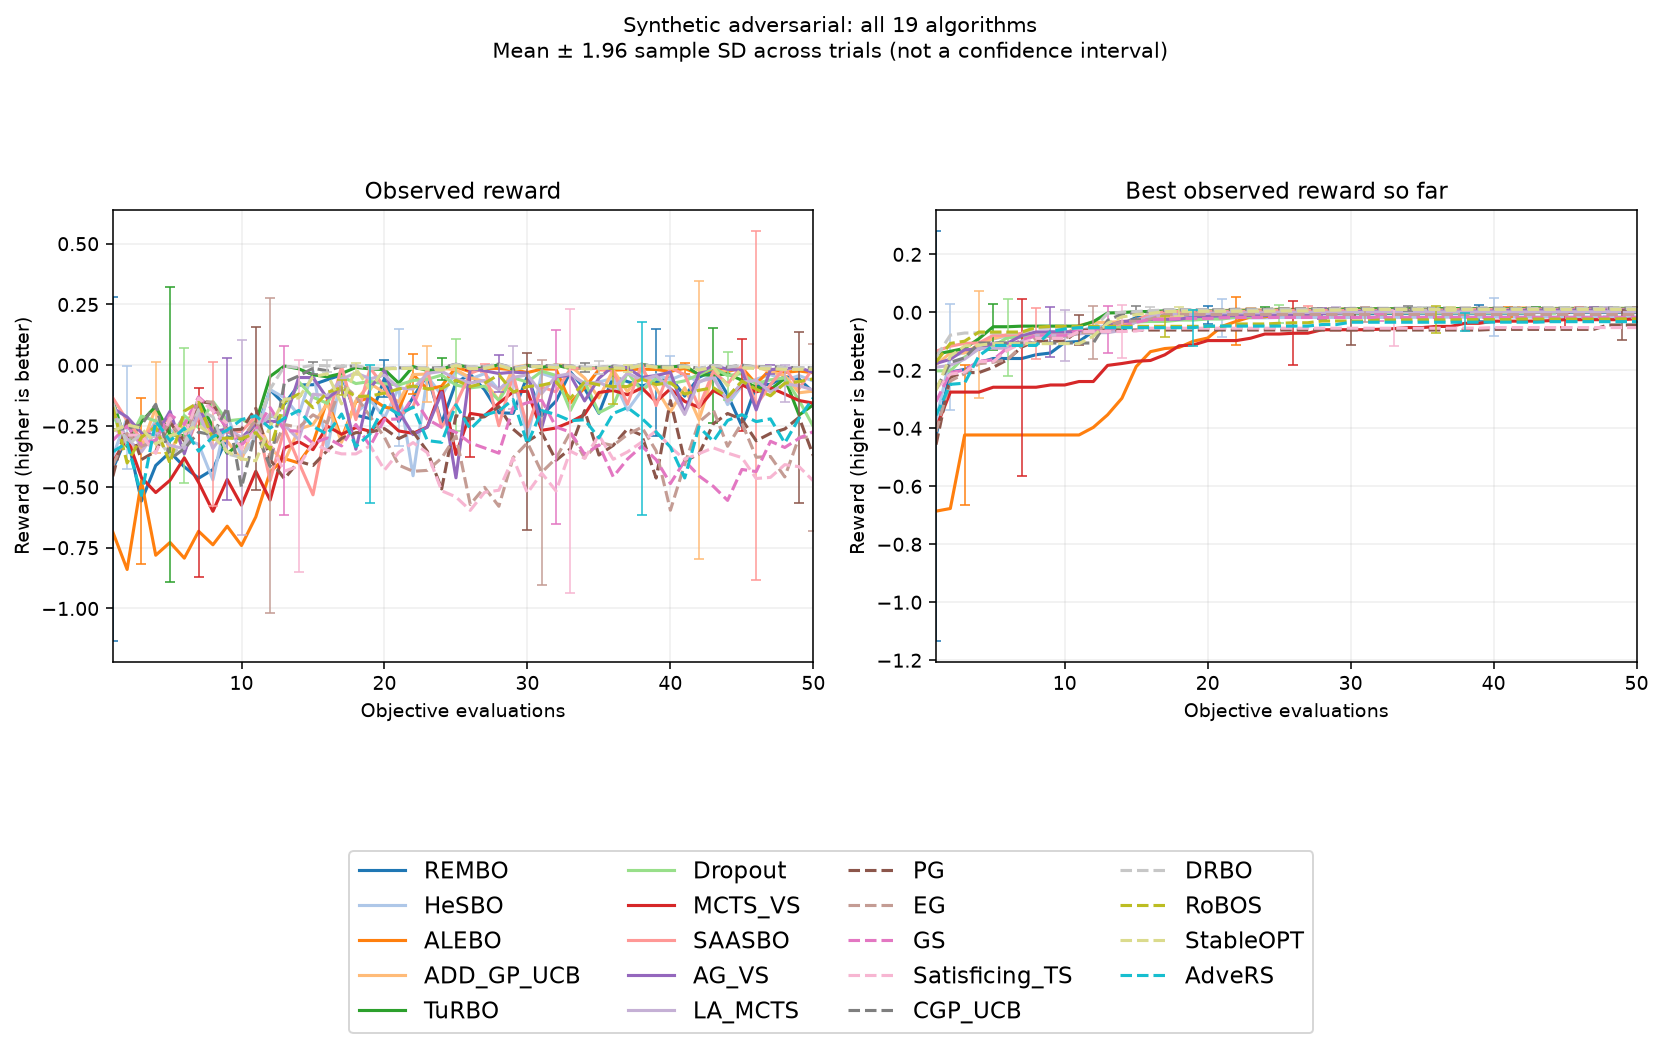

In [ ]:
import basat

seed = basat.set_seed(113, threads=1)
run_directory = basat.new_run_directory("results/last_guide/synthetic_adversarial")
bounds = basat.Bounds(lower=[0.0] * 3, upper=[1.0] * 3)

def adversarial_objective(values):
    # This function receives the evaluated (already perturbed) coordinate.
    target = (0.3, 0.7, 0.5)
    return -sum((x - t) ** 2 for x, t in zip(values, target))


def apply_attack(action, *, round_index, generator):
    direction = 1.0 if round_index % 2 else -1.0
    changed = min(1.0, max(0.0, float(action[0]) + 0.05 * direction))
    return [changed - float(action[0]), 0.0, 0.0]

# Fresh, fully explicit configurations for adversarial observations.
# These bounded computation settings are editable examples.
# No setting overrides are hidden behind a profile.
dimension = bounds.dimension
reduced_dimension = min(2, dimension)
constructor_options = {
    'maximize': True,
    'dtype': 'float64',
    'device': 'cpu',
    'plot': False,
    'verbose': False,
    'verbose_setting': False,
    'verbose_iter_by_iter': False,
}

# Isotropic kernels model every input; no active coordinates are given.
action_kernel = basat.KernelConfig(
    name='matern52',
    ard_num_dims=None,
    active_dims=None,
    use_outputscale=True,
    lengthscale_prior=None,
    outputscale_prior=None,
    kwargs={},
)
context_kernel = basat.KernelConfig(
    name='rbf',
    ard_num_dims=None,
    active_dims=None,
    use_outputscale=True,
    lengthscale_prior=None,
    outputscale_prior=None,
    kwargs={},
)
ei = basat.AcquisitionConfig(
    name='EI',
    beta=4.0,
    xi=0.0,
    mc_samples=64,
    seed=seed,
)
ucb = basat.AcquisitionConfig(
    name='UCB',
    beta=4.0,
    xi=0.0,
    mc_samples=64,
    seed=seed,
)
contextual_solver = basat.AcquisitionOptimizerSpec(
    raw_samples=32,
    restarts=2,
    maxiter=50,
    fit_maxiter=50,
    solver_tolerance=1e-06,
)
distributional_solver = basat.ActionOptimizerSpec(
    raw_samples=24,
    restarts=2,
    maxiter=50,
    fit_maxiter=50,
)
robust_solver = basat.MultiStartSolver(
    method='multistart',
)

rembo_config = basat.REMBOConfig(
    embedding_dimension=reduced_dimension,
    finite_candidate_mode='project',
    Y_lower=None,
    Y_upper=None,
    kernel_type='low_dimensional',
    custom_kernel=None,
    acquisition='EI',
    initial_points=11,
    initial_points_sampling_method='uniform',
    batch_size=1,
    q_batch=None,
    lengthscale_lower=0.01,
    lengthscale_upper=50.0,
    initial_lengthscale=None,
    t_sigma=0.002,
    refit_interval=20,
    exploitation_count_limit=5,
    upper_bound_multiplier=0.9,
    seed=seed + 0,
)

hesbo_config = basat.HeSBOConfig(
    embedding_dimension=reduced_dimension,
    finite_candidate_mode='project',
    acquisition=ei,
    initial_points=11,
    initial_points_sampling_method='uniform',
    hash_family='paper',
    batch_size=1,
    q_batch=None,
    seed=seed + 1,
)

alebo_config = basat.ALEBOConfig(
    embedding_dimension=reduced_dimension,
    finite_candidate_mode='project',
    initial_points=11,
    initial_points_sampling_method='uniform',
    acquisition=ei,
    metric_inference='laplace',
    metric_posterior_samples=8,
    feasibility_tolerance=1e-09,
    acquisition_solver='slsqp',
    raw_feasible_samples=64,
    num_restarts=2,
    batch_size=1,
    q_batch=None,
    seed=seed + 2,
)

add_gp_ucb_config = basat.AddGPUCBConfig(
    groups=tuple((i,) for i in range(dimension)),
    maximum_group_size=1,
    learn_decomposition=False,
    decomposition_candidates=None,
    refresh_cycle=25,
    beta=4.0,
    initial_points=11,
    initial_points_sampling_method='uniform',
    component_optimizer=None,
    batch_size=1,
    q_batch=None,
    seed=seed + 3,
)

turbo_config = basat.TuRBOConfig(
    batch_size=1,
    q_batch=None,
    initial_points=11,
    initial_points_sampling_method='uniform',
    length_init=0.8,
    length_min=0.0078125,
    length_max=1.6,
    success_tolerance=3,
    failure_tolerance=None,
    candidate_count=128,
    perturbation_cap=20.0,
    acquisition=ei,
    success_relative_tolerance=0.001,
    noisy_center='posterior_mean',
    max_cholesky_size=2000,
    gp_training_steps=50,
    seed=seed + 4,
)

dropout_config = basat.DropoutConfig(
    active_dimension=reduced_dimension,
    fill_strategy='mix',
    random_fill_probability=0.1,
    beta=4.0,
    acquisition_optimizer=None,
    initial_points=11,
    initial_points_sampling_method='uniform',
    batch_size=1,
    q_batch=None,
    seed=seed + 5,
)

mcts_vs_config = basat.MCTSVSConfig(
    Nv=2,
    Ns=2,
    archive_size=20,
    initial_points=11,
    initial_points_sampling_method='uniform',
    bad_count_limit=5,
    split_threshold=3,
    exploration_constant=0.1,
    inner_optimizer='bo',
    candidate_pool_size=64,
    kernel_lengthscale=0.2,
    acquisition_beta=4.0,
    gp_maxiter=50,
    batch_size=1,
    q_batch=None,
    seed=seed + 6,
)

saasbo_config = basat.SAASBOConfig(
    shrinkage_scale=0.1,
    warmup_steps=64,
    posterior_samples=64,
    thinning=4,
    num_chains=1,
    initial_points=11,
    initial_points_sampling_method='uniform',
    acquisition='EI',
    max_tree_depth=4,
    target_accept_prob=0.8,
    num_restarts=2,
    raw_samples=32,
    mc_samples=32,
    ucb_beta=4.0,
    max_r_hat=1.1,
    min_effective_sample_size=10.0,
    allow_divergences=False,
    batch_size=1,
    q_batch=None,
    seed=seed + 7,
)

ag_vs_config = basat.AG_VSConfig(
    effective_dimension=reduced_dimension,
    sequence_length=2,
    split_groups=2,
    initial_points=11,
    initial_points_sampling_method='uniform',
    acquisition=ucb,
    stopping_threshold=None,
    stopping_delta=None,
    stagnation_patience=None,
    gp_fit_method='mle',
    gp_maxiter=50,
    acquisition_restarts=2,
    acquisition_raw_samples=64,
    batch_size=1,
    q_batch=None,
    seed=seed + 8,
)

la_mcts_config = basat.LAMCTSConfig(
    initial_points=11,
    initial_points_sampling_method='uniform',
    exploration_constant=1.0,
    split_threshold=12,
    min_child_size=3,
    max_depth=20,
    classifier='svm_rbf',
    local_sampler='turbo',
    candidate_pool_size=64,
    max_resampling_attempts=4,
    kernel_lengthscale=0.2,
    acquisition_beta=4.0,
    gp_maxiter=50,
    batch_size=1,
    q_batch=None,
    seed=seed + 9,
)

pg_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=11,
    initial_points_sampling_method='uniform',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 10,
)

eg_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=11,
    initial_points_sampling_method='uniform',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 11,
)

gs_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=11,
    initial_points_sampling_method='uniform',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 12,
)

satisficing_ts_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=11,
    initial_points_sampling_method='uniform',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 13,
)

cgp_ucb_config = basat.CGPUCBConfig(
    action_bounds=bounds,
    action_set=None,
    action_kernel=action_kernel,
    context_kernel=context_kernel,
    kernel_combination='product',
    beta=4.0,
    delta=0.1,
    finite_domain_cardinality=None,
    acquisition_optimizer=contextual_solver,
    initial_points=11,
    batch_size=1,
    q_batch=None,
    seed=seed + 14,
)

drbo_config = basat.DRBOConfig(
    context_kernel=context_kernel,
    action_kernel=action_kernel,
    beta=4.0,
    ambiguity_metric='mmd',
    inner_solver='slsqp',
    action_optimizer=distributional_solver,
    distribution_grid=None,
    enumeration_resolution=20,
    initial_points=11,
    feasibility_tolerance=1e-08,
    optimizer_tolerance=1e-06,
    batch_size=1,
    q_batch=None,
    seed=seed + 15,
)

robos_config = basat.RoBOSConfig(
    aspiration=-0.1,
    context_kernel=context_kernel,
    action_kernel=action_kernel,
    joint_kernel_combination='product',
    joint_kernel=None,
    beta=4.0,
    simplex_solver='slsqp',
    distribution_floor=0.0,
    distribution_grid=None,
    enumeration_resolution=20,
    action_raw_samples=24,
    action_restarts=2,
    action_maxiter=50,
    initial_points=11,
    fit_maxiter=50,
    feasibility_tolerance=1e-08,
    optimizer_tolerance=1e-06,
    batch_size=1,
    q_batch=None,
    seed=seed + 16,
)

stableopt_config = basat.StableOPTConfig(
    perturbation_radius=0.08,
    distance=basat.L2Distance(),
    beta=4.0,
    inner_solver=robust_solver,
    outer_solver=robust_solver,
    inner_raw_samples=16,
    outer_raw_samples=32,
    inner_restarts=2,
    outer_restarts=2,
    solver_tolerance=1e-06,
    initial_points=11,
    fit_maxiter=50,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 17,
)

advers_config = basat.AdveRSConfig(
    variant='RS1',
    aspiration=-0.1,
    p=1.0,
    beta=4.0,
    perturbation_domain=basat.FullDomainPerturbations(norm='l2', distance_floor=1e-8),
    candidate_solver=robust_solver,
    inner_solver=robust_solver,
    decision_model='ucb',
    outer_raw_samples=32,
    inner_raw_samples=16,
    radius_bisection_steps=8,
    solver_tolerance=1e-06,
    initial_points=11,
    fit_maxiter=50,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 18,
)

# SAASBO uses actual NUTS. Short chains can report poor ESS/divergences.
# Warnings retain finite draws; they do not certify convergence.
# For inference increase warmup/draws and use at least two chains.
algorithms = {
    'REMBO': basat.REMBO(
        bounds=bounds, config=rembo_config,
        **constructor_options,
    ),
    'HeSBO': basat.HeSBO(
        bounds=bounds, config=hesbo_config,
        **constructor_options,
    ),
    'ALEBO': basat.ALEBO(
        bounds=bounds, config=alebo_config,
        **constructor_options,
    ),
    'ADD_GP_UCB': basat.ADD_GP_UCB(
        bounds=bounds, config=add_gp_ucb_config,
        **constructor_options,
    ),
    'TuRBO': basat.TuRBO(
        bounds=bounds, config=turbo_config,
        **constructor_options,
    ),
    'Dropout': basat.Dropout(
        bounds=bounds, config=dropout_config,
        **constructor_options,
    ),
    'MCTS_VS': basat.MCTS_VS(
        bounds=bounds, config=mcts_vs_config,
        **constructor_options,
    ),
    'SAASBO': basat.SAASBO(
        bounds=bounds, config=saasbo_config,
        **constructor_options,
        diagnostic_policy='warn',
        jit_compile=True,
        mcmc_num_threads=1,
    ),
    'AG_VS': basat.AG_VS(
        bounds=bounds, config=ag_vs_config,
        **constructor_options,
    ),
    'LA_MCTS': basat.LA_MCTS(
        bounds=bounds, config=la_mcts_config,
        **constructor_options,
    ),
    'PG': basat.PG(
        bounds=bounds, config=pg_config,
        **constructor_options,
    ),
    'EG': basat.EG(
        bounds=bounds, config=eg_config,
        **constructor_options,
    ),
    'GS': basat.GS(
        bounds=bounds, config=gs_config,
        **constructor_options,
    ),
    'Satisficing_TS': basat.Satisficing_TS(
        bounds=bounds, config=satisficing_ts_config,
        **constructor_options,
    ),
    'CGP_UCB': basat.CGP_UCB(
        bounds=bounds, config=cgp_ucb_config,
        **constructor_options,
    ),
    'DRBO': basat.DRBO(
        bounds=bounds, config=drbo_config,
        **constructor_options,
    ),
    'RoBOS': basat.RoBOS(
        bounds=bounds, config=robos_config,
        **constructor_options,
    ),
    'StableOPT': basat.StableOPT(
        bounds=bounds, config=stableopt_config,
        **constructor_options,
    ),
    'AdveRS': basat.AdveRS(
        bounds=bounds, config=advers_config,
        **constructor_options,
    ),
}
print('Configured algorithms:', len(algorithms), list(algorithms))


environment = basat.AdversarialEnvironment(
    bounds=bounds, function=adversarial_objective,
    attack=apply_attack,
    dataset=None, previous_data=None, dtype="float64", device="cpu",
    noise_std=0.01, noise_fn=None, add_noise_to_data=False,
    allow_repeated_actions=False, data_row_selection="first", seed=seed,
)

assert set(algorithms) == set(basat.algorithm_names())
print("Algorithms submitted:", len(algorithms))
print("Names:", list(algorithms))
experiment = basat.Experiment(
    environment=environment, algorithm=algorithms,
    output_directory=run_directory, resume=False, save_every=10,
    stopping_rule=None,
)
result = experiment.run(
    trials=5, max_evaluations=50, plot=False, show=False, progress=True,
)
print(experiment.summary())
print(experiment.diagnostics())
figure = basat.plot(
    experiment, kind="comparison", title="Synthetic adversarial: all 19 algorithms",
    titles=("Observed reward", "Best observed reward so far"),
    xlabel="Objective evaluations", ylabel="Reward (higher is better)",
    figsize=(12.0, 7.5), xlim=(1, 50), grid=True,
    legend=True, legend_columns=4, legend_fontsize=12.0,
    save_path=basat.join_path(run_directory, "all_algorithms.png"),
    dpi=180, show=True,
)
print("Saved results:", run_directory)

# 2. Real Data Formatting

The strict native loader is `basat.load_dataset(path, environment="...")`.
It reads a finite table of **explicit rewards**, not a model-training dataset
whose last column is an arbitrary label. A row is an observation at the
named action and, where relevant, context. The library never invents missing
rewards or interpolates an unmeasured row. Your objective can instead train
a model or run a simulator inside a user-defined function if new evaluations
are possible.

Reserved columns use zero-based contiguous numbering. `action_0` through
`action_{d-1}` identify learner-controlled coordinates. `reward` is required
and must be the final column. Numeric values must be finite. Context vectors
describe exogenous information and need not have the same dimension as actions;
there is no automatic one-context-column-per-action-column rule.

| Environment | Required column order / roles | Learner sees before acting |
|---|---|---|
| Stochastic | action_0,...,action_(d-1),reward | Available action coordinates |
| Contextual | action_0,...,context_0,...,reward | Current context and actions available there |
| Distributional | action_0,...,context_0,...,reference_probability, optional sampling_probability and margin, reward | Support, reference probabilities, ambiguity margin |
| Adversarial | action_0,...,evaluated_action_0,...,reward | Nominal action coordinates; evaluated coordinate arrives in feedback |

Context is not a reward and must not contain the observed target as a shortcut.
Reward columns remain hidden from the learner until the environment evaluates
its selected action. This is offline finite search, not a causal evaluation of
treatments or a policy-value estimator for incomplete logged bandit data.
Arbitrary logged actions without counterfactual coverage cannot be treated as
a complete distributional reward grid.

The four code blocks below write actual sample rows using only Basat, reload
them, and print the exact CSV format. Replace the rows with your own measurements.
They demonstrate formatting; the four large experiments use the full external
files and reconstruct their own environments.

## Stochastic CSV

Only action columns and the final reward are required. The example
        records three scaled patient descriptors and a negative recorded response.
        Searching rows selects measured records, not a medical intervention.

In [6]:
import basat

# Four actual rows from the external example table.
columns = [
    'action_0',
    'action_1',
    'action_2',
    'reward',
]
rows = [
    [
        0.5826446280991735,
        0.5492957746478874,
        0.5622169960335567,
        -151.0,
    ],
    [
        0.14876033057851243,
        0.352112676056338,
        0.22243672996595168,
        -75.0,
    ],
    [
        0.5165289256198347,
        0.43661971830985913,
        0.49657762645231474,
        -141.0,
    ],
    [
        0.30165289256198347,
        0.30985915492957744,
        0.5729228825160587,
        -206.0,
    ],
]

directory = basat.new_run_directory("results/last_guide/format_stochastic")
path = basat.save_csv(
    basat.join_path(directory, "example.csv"),
    rows, columns=columns,
)
loaded = basat.load_dataset(path, environment="stochastic")
print(loaded.preview(rows=4))
print("Action dimension:", loaded.bounds.dimension)
print("Rows:", len(loaded.dataset.observations))

action_0,action_1,action_2,reward
0.5826446280991735,0.5492957746478874,0.5622169960335567,-151.0
0.14876033057851243,0.352112676056338,0.22243672996595168,-75.0
0.5165289256198347,0.43661971830985913,0.49657762645231474,-141.0
0.30165289256198347,0.30985915492957744,0.5729228825160587,-206.0
Action dimension: 3
Rows: 4


## Contextual CSV

Context dimensions are independent of action dimensions. Wine cultivar
        is encoded with three one-hot context columns so numeric distances do not
        imply an ordering of categories. All action/reward rows at a revealed
        cultivar are eligible; other cultivars' rewards remain unavailable.

In [7]:
import basat

# Four actual rows from the external example table.
columns = [
    'action_0',
    'action_1',
    'action_2',
    'context_0',
    'context_1',
    'context_2',
    'reward',
]
rows = [
    [
        0.8421052631578949,
        0.191699604743083,
        0.572192513368984,
        1.0,
        0.0,
        0.0,
        1065.0,
    ],
    [
        0.5710526315789473,
        0.2055335968379447,
        0.4171122994652407,
        1.0,
        0.0,
        0.0,
        1050.0,
    ],
    [
        0.5605263157894738,
        0.3201581027667984,
        0.7005347593582887,
        1.0,
        0.0,
        0.0,
        1185.0,
    ],
    [
        0.8789473684210525,
        0.2391304347826087,
        0.6096256684491979,
        1.0,
        0.0,
        0.0,
        1480.0,
    ],
]

directory = basat.new_run_directory("results/last_guide/format_contextual")
path = basat.save_csv(
    basat.join_path(directory, "example.csv"),
    rows, columns=columns,
)
loaded = basat.load_dataset(path, environment="contextual")
print(loaded.preview(rows=4))
print("Action dimension:", loaded.bounds.dimension)
print("Rows:", len(loaded.dataset.observations))

action_0,action_1,action_2,context_0,context_1,context_2,reward
0.8421052631578949,0.191699604743083,0.572192513368984,1.0,0.0,0.0,1065.0
0.5710526315789473,0.2055335968379447,0.4171122994652407,1.0,0.0,0.0,1050.0
0.5605263157894738,0.3201581027667984,0.7005347593582887,1.0,0.0,0.0,1185.0
0.8789473684210525,0.2391304347826087,0.6096256684491979,1.0,0.0,0.0,1480.0
Action dimension: 3
Rows: 4


## Distributional CSV

Every distinct action must have a measured row at every context in
        the support. `reference_probability` must agree across all rows of the same
        context and sum to one over support, not over CSV rows. `sampling_probability`
        has the same normalization and is environment-private. When omitted it
        equals the reference. `margin` is one consistent non-negative scalar;
        omitted margin defaults to zero. A multirow CSV repeats this metadata.
        The wind example uses 11 wind-generation levels. Its rewards are calculated
        from the published revenue function; they are not measured payments.
        Include all contexts when writing a smaller example so probabilities
        still sum to one. The real experiment overrides initial CSV probabilities
        with chronological 48-hour reference and private realization providers.

In [1]:
import basat

# Two actions with all 11 contexts: retain complete probability support.
columns = ['action_0', 'context_0', 'reference_probability', 'sampling_probability', 'margin', 'reward']
rows = [
    [0.0, 0.0, 0.0, 0.0, 0.1, 0.0],
    [0.0, 0.1, 0.0, 0.0, 0.1, 0.010000000000000002],
    [0.0, 0.2, 0.0, 0.0, 0.1, 0.020000000000000004],
    [0.0, 0.3, 0.6875, 0.0, 0.1, 0.03],
    [0.0, 0.4, 0.1875, 0.0, 0.1, 0.04000000000000001],
    [0.0, 0.5, 0.08333333333333333, 1.0, 0.1, 0.05],
    [0.0, 0.6, 0.041666666666666664, 0.0, 0.1, 0.06],
    [0.0, 0.7, 0.0, 0.0, 0.1, 0.06999999999999999],
    [0.0, 0.8, 0.0, 0.0, 0.1, 0.08000000000000002],
    [0.0, 0.9, 0.0, 0.0, 0.1, 0.09000000000000001],
    [0.0, 1.0, 0.0, 0.0, 0.1, 0.1],
    [0.01, 0.0, 0.0, 0.0, 0.1, -0.05],
    [0.01, 0.1, 0.0, 0.0, 0.1, 0.019000000000000003],
    [0.01, 0.2, 0.0, 0.0, 0.1, 0.029000000000000005],
    [0.01, 0.3, 0.6875, 0.0, 0.1, 0.039],
    [0.01, 0.4, 0.1875, 0.0, 0.1, 0.04900000000000001],
    [0.01, 0.5, 0.08333333333333333, 1.0, 0.1, 0.059000000000000004],
    [0.01, 0.6, 0.041666666666666664, 0.0, 0.1, 0.06899999999999999],
    [0.01, 0.7, 0.0, 0.0, 0.1, 0.07899999999999999],
    [0.01, 0.8, 0.0, 0.0, 0.1, 0.08900000000000001],
    [0.01, 0.9, 0.0, 0.0, 0.1, 0.099],
    [0.01, 1.0, 0.0, 0.0, 0.1, 0.109],
]

directory = basat.new_run_directory("results/last_guide/format_distributional_wind")
path = basat.save_csv(basat.join_path(directory, "example.csv"), rows, columns=columns)
loaded = basat.load_dataset(path, environment="distributional")
print(loaded.preview(rows=4))
print("Action dimension:", loaded.bounds.dimension)
print("Rows:", len(loaded.dataset.observations))


action_0,context_0,reference_probability,sampling_probability,margin,reward
0.0,0.0,0.0,0.0,0.1,0.0
0.0,0.1,0.0,0.0,0.1,0.010000000000000002
0.0,0.2,0.0,0.0,0.1,0.020000000000000004
0.0,0.3,0.6875,0.0,0.1,0.03
Action dimension: 1
Rows: 22


## Adversarial CSV

Both nominal and evaluated action vectors have dimension d. The final
        reward belongs to the evaluated coordinate. This finite-table contract
        requires a deterministic one-to-one permutation over the measured action
        set, so every attack lookup has a real measured outcome and consumed rows
        remain consistent. Arbitrary off-grid attacks are rejected in finite mode;
        use a function-backed environment to evaluate new coordinates. The Iris
        example constructs swaps between measured records. It is an illustrative
        adversarial view of observational data, not a historical attack dataset.

In [9]:
import basat

# Four actual rows from the external example table.
columns = [
    'action_0',
    'action_1',
    'action_2',
    'evaluated_action_0',
    'evaluated_action_1',
    'evaluated_action_2',
    'reward',
]
rows = [
    [
        0.0,
        0.423728813559322,
        0.375,
        0.0833333333333334,
        0.5084745762711864,
        0.375,
        6.0,
    ],
    [
        0.0833333333333334,
        0.5084745762711864,
        0.375,
        0.0,
        0.423728813559322,
        0.375,
        5.0,
    ],
    [
        0.0833333333333334,
        0.5932203389830508,
        0.5833333333333334,
        0.0833333333333334,
        0.6779661016949152,
        0.5833333333333334,
        6.0,
    ],
    [
        0.0833333333333334,
        0.6779661016949152,
        0.5833333333333334,
        0.0833333333333334,
        0.5932203389830508,
        0.5833333333333334,
        6.2,
    ],
]

directory = basat.new_run_directory("results/last_guide/format_adversarial")
path = basat.save_csv(
    basat.join_path(directory, "example.csv"),
    rows, columns=columns,
)
loaded = basat.load_dataset(path, environment="adversarial")
print(loaded.preview(rows=4))
print("Action dimension:", loaded.bounds.dimension)
print("Rows:", len(loaded.dataset.observations))

action_0,action_1,action_2,evaluated_action_0,evaluated_action_1,evaluated_action_2,reward
0.0,0.423728813559322,0.375,0.0833333333333334,0.5084745762711864,0.375,6.0
0.0833333333333334,0.5084745762711864,0.375,0.0,0.423728813559322,0.375,5.0
0.0833333333333334,0.5932203389830508,0.5833333333333334,0.0833333333333334,0.6779661016949152,0.5833333333333334,6.0
0.0833333333333334,0.6779661016949152,0.5833333333333334,0.0833333333333334,0.5932203389830508,0.5833333333333334,6.2
Action dimension: 3
Rows: 4


## 2.1 Real Life Objective Optimization

Four **different** real datasets provide four large independent comparisons.
Each submits all 19 algorithms in five trials, in stochastic, contextual,
distributional, then adversarial order: **380 submitted algorithm trials**.
Non-native combinations use the documented runtime defaults and emit
informative warnings. Genuine failures remain visible in summaries and
legends. The source's
finite reward table is copied privately for each method. No main experiment
enables patience, target, or time stopping; each requests 50 evaluations.

REMBO, HeSBO, and ALEBO use `finite_candidate_mode="project"` by default.
This explicit finite-data extension compresses normalized candidate rows:
REMBO uses least-squares coordinates, HeSBO uses signed bucket averages
(zero for empty buckets), and ALEBO uses its B projection. Acquisition scores
select an actual available row and the environment returns its stored reward.
The wind table stores explicitly modeled revenue; its physical context comes
from measurements. No reward interpolation is performed by the library. Projection
can merge distinct rows, so the original embedding guarantees do not apply.
The warning `data.projected_embedding` explains this adaptation. Set the
configuration field to `"exact"` to restore strict embedding checks.

The original environment classes remain in use. Context still restricts
available contextual rows, the distribution still selects the wind-generation
context, and the adversarial environment still applies its declared attack.
These stochastic policies model pooled scalar feedback without conditioning
on those additional inputs; execution does not imply contextual or robust
optimality. A distribution alone is not enough: evaluation still requires
a reward table or callable objective.

| Environment | Distinct external dataset | Reward and constructed interpretation |
|---|---|---|
| Stochastic | Diabetes | Negative recorded one-year progression; search among measured descriptor rows |
| Contextual | Wine | Recorded proline concentration, conditional on one-hot cultivar |
| Distributional | OPSD German wind generation (2013) | Energy commitment revenue under recorded wind realizations; modeled revenue, not measured market payments |
| Adversarial | Iris | Measured sepal length at a permuted observed coordinate |

These are explicitly constructed finite optimization views of four real
observational tables. They were not collected as four native online bandit
trials. The results do not establish clinical benefits, causal effects,
distributional robustness, or adversarial guarantees for the original studies.
We optimize the stated scalar rewards, including the explicit wind revenue model,
not classification accuracy.
For your own application, select a reward whose maximization is meaningful.

Provenance, source URLs, exact transformations, and SHA-256 hashes are in
`data/native_manifest.json`. The original files and prepared CSVs remain under
the project-level `data/` folder; none are packaged inside Basat. Dataset
descriptions are documented by
[scikit-learn's dataset reference](https://scikit-learn.org/1.6/datasets/toy_dataset.html)
and the wind-source and DRBO references in the distributional subsection.

In the adversarial Iris experiment, StableOPT's selected radius 2 covers the entire [0,1]^3 action box and
the constructed swaps. AdveRS instead considers the full feasible domain
without receiving the environment's actual attack budget. A small-radius assumption would be false for these
data. Best observed reward traces measure sampled outcomes, not the robust
objectives optimized by DRBO, RoBOS, StableOPT, or AdveRS.

### Stochastic: diabetes / all 19 algorithms

Run this entire block independently. Its CSV path, full algorithm configurations, and environment are declared again here.

Saved-result refresh (no optimization was executed).
Source: results/last_guide/real_stochastic/run_32679mqf/results.json
Trials: 5/5; limits: {'max_evaluations': 50, 'max_rounds': None}
Algorithm | evaluations per trial | final mean best reward | failures
REMBO | [50, 50, 50, 50, 50] | -38.2 | 0
HeSBO | [50, 50, 50, 50, 50] | -36.8 | 0
ALEBO | [50, 50, 50, 50, 50] | -41 | 0
ADD_GP_UCB | [50, 50, 50, 50, 50] | -31 | 0
TuRBO | [50, 50, 50, 50, 50] | -43 | 0
Dropout | [50, 50, 50, 50, 50] | -41.6 | 0
MCTS_VS | [50, 50, 50, 50, 50] | -42.2 | 0
SAASBO | [50, 50, 50, 50, 50] | -42.6 | 0
AG_VS | [50, 50, 50, 50, 50] | -34.2 | 0
LA_MCTS | [50, 50, 50, 50, 50] | -45 | 0
PG | [50, 50, 50, 50, 50] | -49 | 0
EG | [50, 50, 50, 50, 50] | -49 | 0
GS | [50, 50, 50, 50, 50] | -49 | 0
Satisficing_TS | [50, 50, 50, 50, 50] | -49 | 0
CGP_UCB | [50, 50, 50, 50, 50] | -37 | 0
DRBO | [50, 50, 50, 50, 50] | -49 | 0
RoBOS | [50, 50, 50, 50, 50] | -49 | 0
StableOPT | [50, 50, 50, 50, 50] | -31 | 0
AdveRS | [50

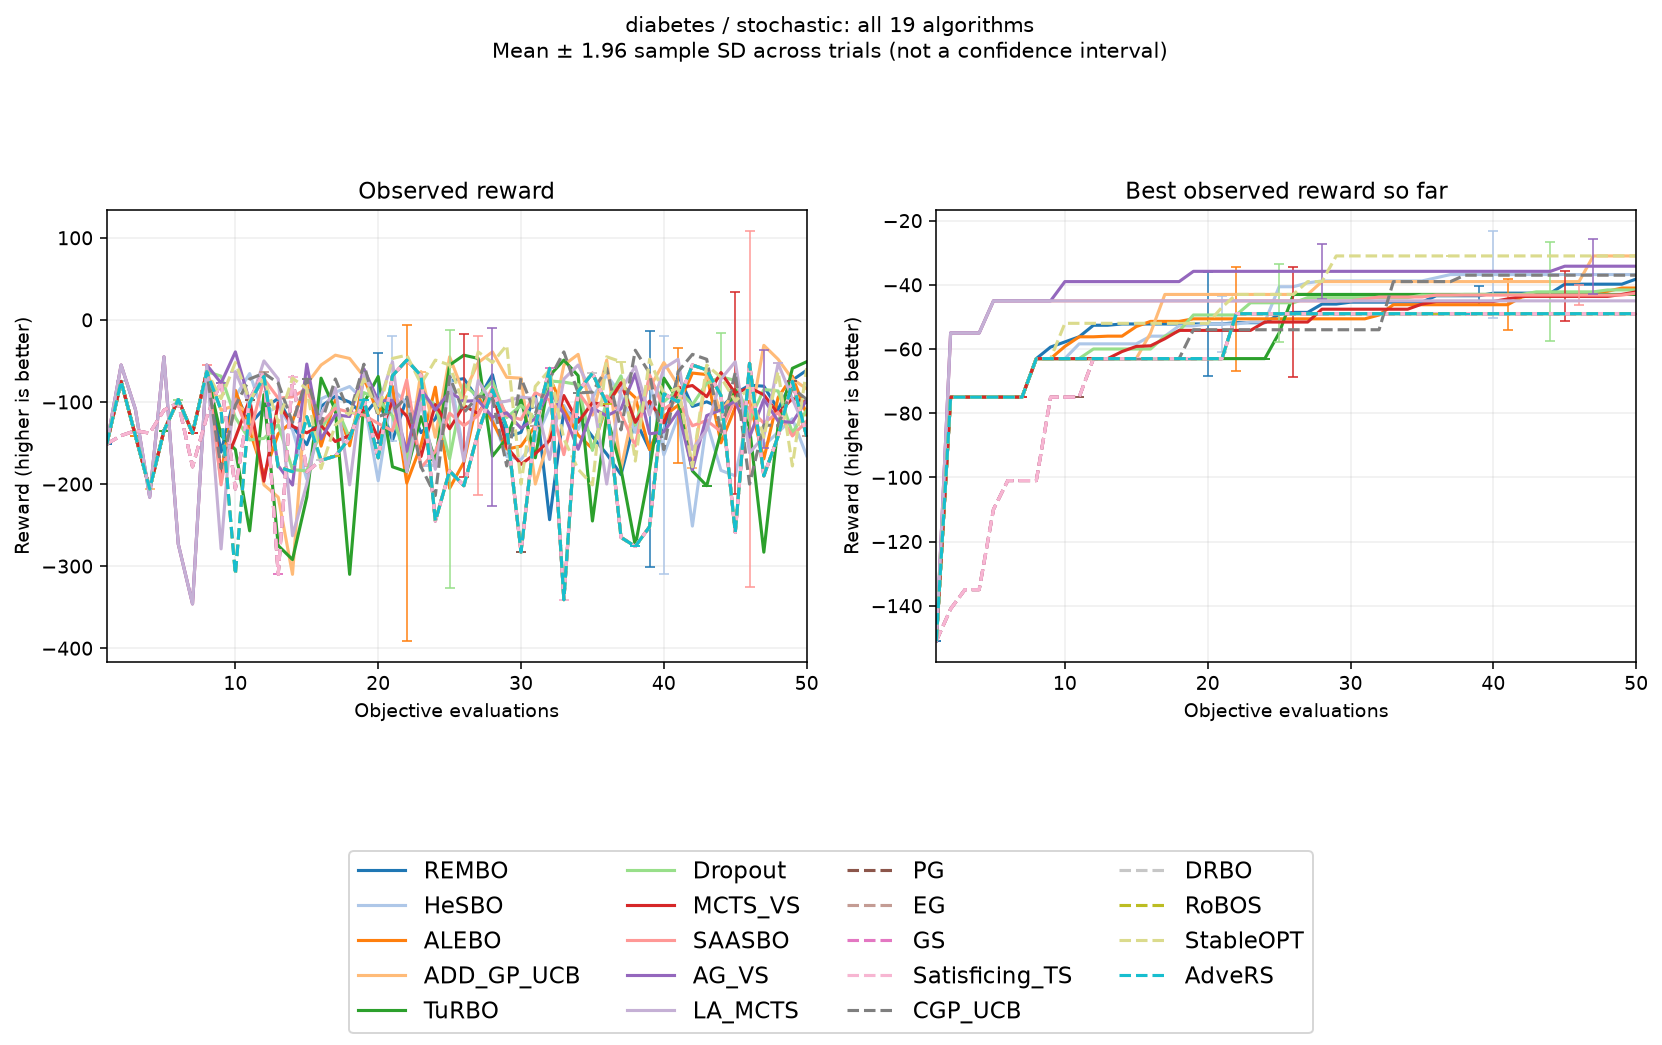

In [ ]:
import basat

seed = basat.set_seed(210, threads=1)
data_path = basat.find_path("data/stochastic/diabetes_bandit.csv")
loaded = basat.load_dataset(data_path, environment="stochastic")
print(loaded.preview(rows=3))
bounds = loaded.bounds
run_directory = basat.new_run_directory("results/last_guide/real_stochastic")

# Fresh, fully explicit configurations for stochastic observations.
# These bounded computation settings are editable examples.
# No setting overrides are hidden behind a profile.
dimension = bounds.dimension
reduced_dimension = min(2, dimension)
constructor_options = {
    'maximize': True,
    'dtype': 'float64',
    'device': 'cpu',
    'plot': False,
    'verbose': False,
    'verbose_setting': False,
    'verbose_iter_by_iter': False,
}

# Isotropic kernels model every input; no active coordinates are given.
action_kernel = basat.KernelConfig(
    name='matern52',
    ard_num_dims=None,
    active_dims=None,
    use_outputscale=True,
    lengthscale_prior=None,
    outputscale_prior=None,
    kwargs={},
)
context_kernel = basat.KernelConfig(
    name='rbf',
    ard_num_dims=None,
    active_dims=None,
    use_outputscale=True,
    lengthscale_prior=None,
    outputscale_prior=None,
    kwargs={},
)
ei = basat.AcquisitionConfig(
    name='EI',
    beta=3.0,
    xi=0.0,
    mc_samples=64,
    seed=seed,
)
ucb = basat.AcquisitionConfig(
    name='UCB',
    beta=3.0,
    xi=0.0,
    mc_samples=64,
    seed=seed,
)
contextual_solver = basat.AcquisitionOptimizerSpec(
    raw_samples=32,
    restarts=2,
    maxiter=50,
    fit_maxiter=50,
    solver_tolerance=1e-06,
)
distributional_solver = basat.ActionOptimizerSpec(
    raw_samples=24,
    restarts=2,
    maxiter=50,
    fit_maxiter=50,
)
robust_solver = basat.MultiStartSolver(
    method='multistart',
)

rembo_config = basat.REMBOConfig(
    embedding_dimension=reduced_dimension,
    finite_candidate_mode='project',
    Y_lower=None,
    Y_upper=None,
    kernel_type='low_dimensional',
    custom_kernel=None,
    acquisition='EI',
    initial_points=8,
    initial_points_sampling_method='sobol',
    batch_size=1,
    q_batch=None,
    lengthscale_lower=0.01,
    lengthscale_upper=50.0,
    initial_lengthscale=None,
    t_sigma=0.002,
    refit_interval=20,
    exploitation_count_limit=5,
    upper_bound_multiplier=0.9,
    seed=seed + 0,
)

hesbo_config = basat.HeSBOConfig(
    embedding_dimension=reduced_dimension,
    finite_candidate_mode='project',
    acquisition=ei,
    initial_points=8,
    initial_points_sampling_method='sobol',
    hash_family='paper',
    batch_size=1,
    q_batch=None,
    seed=seed + 1,
)

alebo_config = basat.ALEBOConfig(
    embedding_dimension=reduced_dimension,
    finite_candidate_mode='project',
    initial_points=8,
    initial_points_sampling_method='sobol',
    acquisition=ei,
    metric_inference='laplace',
    metric_posterior_samples=8,
    feasibility_tolerance=1e-09,
    acquisition_solver='slsqp',
    raw_feasible_samples=64,
    num_restarts=2,
    batch_size=1,
    q_batch=None,
    seed=seed + 2,
)

add_gp_ucb_config = basat.AddGPUCBConfig(
    groups=tuple((i,) for i in range(dimension)),
    maximum_group_size=1,
    learn_decomposition=False,
    decomposition_candidates=None,
    refresh_cycle=25,
    beta=3.0,
    initial_points=8,
    initial_points_sampling_method='sobol',
    component_optimizer=None,
    batch_size=1,
    q_batch=None,
    seed=seed + 3,
)

turbo_config = basat.TuRBOConfig(
    batch_size=1,
    q_batch=None,
    initial_points=8,
    initial_points_sampling_method='sobol',
    length_init=0.8,
    length_min=0.0078125,
    length_max=1.6,
    success_tolerance=3,
    failure_tolerance=None,
    candidate_count=128,
    perturbation_cap=20.0,
    acquisition=ei,
    success_relative_tolerance=0.001,
    noisy_center='posterior_mean',
    max_cholesky_size=2000,
    gp_training_steps=50,
    seed=seed + 4,
)

dropout_config = basat.DropoutConfig(
    active_dimension=reduced_dimension,
    fill_strategy='mix',
    random_fill_probability=0.1,
    beta=3.0,
    acquisition_optimizer=None,
    initial_points=8,
    initial_points_sampling_method='sobol',
    batch_size=1,
    q_batch=None,
    seed=seed + 5,
)

mcts_vs_config = basat.MCTSVSConfig(
    Nv=2,
    Ns=2,
    archive_size=20,
    initial_points=8,
    initial_points_sampling_method='sobol',
    bad_count_limit=5,
    split_threshold=3,
    exploration_constant=0.1,
    inner_optimizer='bo',
    candidate_pool_size=64,
    kernel_lengthscale=0.2,
    acquisition_beta=3.0,
    gp_maxiter=50,
    batch_size=1,
    q_batch=None,
    seed=seed + 6,
)

saasbo_config = basat.SAASBOConfig(
    shrinkage_scale=0.1,
    warmup_steps=64,
    posterior_samples=64,
    thinning=4,
    num_chains=1,
    initial_points=8,
    initial_points_sampling_method='sobol',
    acquisition='EI',
    max_tree_depth=4,
    target_accept_prob=0.8,
    num_restarts=2,
    raw_samples=32,
    mc_samples=32,
    ucb_beta=3.0,
    max_r_hat=1.1,
    min_effective_sample_size=10.0,
    allow_divergences=False,
    batch_size=1,
    q_batch=None,
    seed=seed + 7,
)

ag_vs_config = basat.AG_VSConfig(
    effective_dimension=reduced_dimension,
    sequence_length=2,
    split_groups=2,
    initial_points=8,
    initial_points_sampling_method='sobol',
    acquisition=ucb,
    stopping_threshold=None,
    stopping_delta=None,
    stagnation_patience=None,
    gp_fit_method='mle',
    gp_maxiter=50,
    acquisition_restarts=2,
    acquisition_raw_samples=64,
    batch_size=1,
    q_batch=None,
    seed=seed + 8,
)

la_mcts_config = basat.LAMCTSConfig(
    initial_points=8,
    initial_points_sampling_method='sobol',
    exploration_constant=1.0,
    split_threshold=12,
    min_child_size=3,
    max_depth=20,
    classifier='svm_rbf',
    local_sampler='turbo',
    candidate_pool_size=64,
    max_resampling_attempts=4,
    kernel_lengthscale=0.2,
    acquisition_beta=3.0,
    gp_maxiter=50,
    batch_size=1,
    q_batch=None,
    seed=seed + 9,
)

pg_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=8,
    initial_points_sampling_method='sobol',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 10,
)

eg_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=8,
    initial_points_sampling_method='sobol',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 11,
)

gs_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=8,
    initial_points_sampling_method='sobol',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 12,
)

satisficing_ts_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=8,
    initial_points_sampling_method='sobol',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 13,
)

cgp_ucb_config = basat.CGPUCBConfig(
    action_bounds=bounds,
    action_set=None,
    action_kernel=action_kernel,
    context_kernel=context_kernel,
    kernel_combination='product',
    beta=3.0,
    delta=0.1,
    finite_domain_cardinality=None,
    acquisition_optimizer=contextual_solver,
    initial_points=8,
    batch_size=1,
    q_batch=None,
    seed=seed + 14,
)

drbo_config = basat.DRBOConfig(
    context_kernel=context_kernel,
    action_kernel=action_kernel,
    beta=3.0,
    ambiguity_metric='mmd',
    inner_solver='slsqp',
    action_optimizer=distributional_solver,
    distribution_grid=None,
    enumeration_resolution=20,
    initial_points=8,
    feasibility_tolerance=1e-08,
    optimizer_tolerance=1e-06,
    batch_size=1,
    q_batch=None,
    seed=seed + 15,
)

robos_config = basat.RoBOSConfig(
    aspiration=-0.1,
    context_kernel=context_kernel,
    action_kernel=action_kernel,
    joint_kernel_combination='product',
    joint_kernel=None,
    beta=3.0,
    simplex_solver='slsqp',
    distribution_floor=0.0,
    distribution_grid=None,
    enumeration_resolution=20,
    action_raw_samples=24,
    action_restarts=2,
    action_maxiter=50,
    initial_points=8,
    fit_maxiter=50,
    feasibility_tolerance=1e-08,
    optimizer_tolerance=1e-06,
    batch_size=1,
    q_batch=None,
    seed=seed + 16,
)

stableopt_config = basat.StableOPTConfig(
    perturbation_radius=0.08,
    distance=basat.L2Distance(),
    beta=3.0,
    inner_solver=robust_solver,
    outer_solver=robust_solver,
    inner_raw_samples=16,
    outer_raw_samples=32,
    inner_restarts=2,
    outer_restarts=2,
    solver_tolerance=1e-06,
    initial_points=8,
    fit_maxiter=50,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 17,
)

advers_config = basat.AdveRSConfig(
    variant='RS1',
    aspiration=-0.1,
    p=1.0,
    beta=3.0,
    perturbation_domain=basat.FullDomainPerturbations(norm='l2', distance_floor=1e-8),
    candidate_solver=robust_solver,
    inner_solver=robust_solver,
    decision_model='ucb',
    outer_raw_samples=32,
    inner_raw_samples=16,
    radius_bisection_steps=8,
    solver_tolerance=1e-06,
    initial_points=8,
    fit_maxiter=50,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 18,
)

# SAASBO uses actual NUTS. Short chains can report poor ESS/divergences.
# Warnings retain finite draws; they do not certify convergence.
# For inference increase warmup/draws and use at least two chains.
algorithms = {
    'REMBO': basat.REMBO(
        bounds=bounds, config=rembo_config,
        **constructor_options,
    ),
    'HeSBO': basat.HeSBO(
        bounds=bounds, config=hesbo_config,
        **constructor_options,
    ),
    'ALEBO': basat.ALEBO(
        bounds=bounds, config=alebo_config,
        **constructor_options,
    ),
    'ADD_GP_UCB': basat.ADD_GP_UCB(
        bounds=bounds, config=add_gp_ucb_config,
        **constructor_options,
    ),
    'TuRBO': basat.TuRBO(
        bounds=bounds, config=turbo_config,
        **constructor_options,
    ),
    'Dropout': basat.Dropout(
        bounds=bounds, config=dropout_config,
        **constructor_options,
    ),
    'MCTS_VS': basat.MCTS_VS(
        bounds=bounds, config=mcts_vs_config,
        **constructor_options,
    ),
    'SAASBO': basat.SAASBO(
        bounds=bounds, config=saasbo_config,
        **constructor_options,
        diagnostic_policy='warn',
        jit_compile=True,
        mcmc_num_threads=1,
    ),
    'AG_VS': basat.AG_VS(
        bounds=bounds, config=ag_vs_config,
        **constructor_options,
    ),
    'LA_MCTS': basat.LA_MCTS(
        bounds=bounds, config=la_mcts_config,
        **constructor_options,
    ),
    'PG': basat.PG(
        bounds=bounds, config=pg_config,
        **constructor_options,
    ),
    'EG': basat.EG(
        bounds=bounds, config=eg_config,
        **constructor_options,
    ),
    'GS': basat.GS(
        bounds=bounds, config=gs_config,
        **constructor_options,
    ),
    'Satisficing_TS': basat.Satisficing_TS(
        bounds=bounds, config=satisficing_ts_config,
        **constructor_options,
    ),
    'CGP_UCB': basat.CGP_UCB(
        bounds=bounds, config=cgp_ucb_config,
        **constructor_options,
    ),
    'DRBO': basat.DRBO(
        bounds=bounds, config=drbo_config,
        **constructor_options,
    ),
    'RoBOS': basat.RoBOS(
        bounds=bounds, config=robos_config,
        **constructor_options,
    ),
    'StableOPT': basat.StableOPT(
        bounds=bounds, config=stableopt_config,
        **constructor_options,
    ),
    'AdveRS': basat.AdveRS(
        bounds=bounds, config=advers_config,
        **constructor_options,
    ),
}
print('Configured algorithms:', len(algorithms), list(algorithms))


environment = basat.StochasticEnvironment(
    bounds=bounds, dataset=loaded.dataset, function=None,
    previous_data=None, dtype="float64", device="cpu",
    noise_std=0.0, noise_fn=None, add_noise_to_data=False,
    allow_repeated_actions=False, data_row_selection="first", seed=seed,
)

assert set(algorithms) == set(basat.algorithm_names())
print("Algorithms submitted:", len(algorithms))
print("Names:", list(algorithms))
experiment = basat.Experiment(
    environment=environment, algorithm=algorithms,
    output_directory=run_directory, resume=False, save_every=10,
    stopping_rule=None,
)
result = experiment.run(
    trials=5, max_evaluations=50, plot=False, show=False, progress=True,
)
print(experiment.summary())
print(experiment.diagnostics())
figure = basat.plot(
    experiment, kind="comparison", title="diabetes / stochastic: all 19 algorithms",
    titles=("Observed reward", "Best observed reward so far"),
    xlabel="Objective evaluations", ylabel="Reward (higher is better)",
    figsize=(12.0, 7.5), xlim=(1, 50), grid=True,
    legend=True, legend_columns=4, legend_fontsize=12.0,
    save_path=basat.join_path(run_directory, "all_algorithms.png"),
    dpi=180, show=True,
)
print("Saved results:", run_directory)

### Contextual: wine / all 19 algorithms

Run this entire block independently. Its CSV path, full algorithm configurations, and environment are declared again here.

Saved-result refresh (no optimization was executed).
Source: results/last_guide/real_contextual/run_r5auk5rn/results.json
Trials: 5/5; limits: {'max_evaluations': 50, 'max_rounds': None}
Algorithm | evaluations per trial | final mean best reward | failures
REMBO | [50, 50, 50, 50, 50] | 1640 | 0
HeSBO | [50, 50, 50, 50, 50] | 1626.8 | 0
ALEBO | [50, 50, 50, 50, 50] | 1680 | 0
ADD_GP_UCB | [50, 50, 50, 50, 50] | 1680 | 0
TuRBO | [50, 50, 50, 50, 50] | 1619.4 | 0
Dropout | [50, 50, 50, 50, 50] | 1626.8 | 0
MCTS_VS | [50, 50, 50, 50, 50] | 1573.6 | 0
SAASBO | [50, 50, 50, 50, 50] | 1653.4 | 0
AG_VS | [50, 50, 50, 50, 50] | 1680 | 0
LA_MCTS | [50, 50, 50, 50, 50] | 1626.8 | 0
PG | [50, 50, 50, 50, 50] | 1626.8 | 0
EG | [50, 50, 50, 50, 50] | 1626.8 | 0
GS | [50, 50, 50, 50, 50] | 1626.8 | 0
Satisficing_TS | [50, 50, 50, 50, 50] | 1419 | 0
CGP_UCB | [50, 50, 50, 50, 50] | 1480 | 0
DRBO | [50, 50, 50, 50, 50] | 1574 | 0
RoBOS | [50, 50, 50, 50, 50] | 1574 | 0
StableOPT | [50, 50, 50, 50, 50]

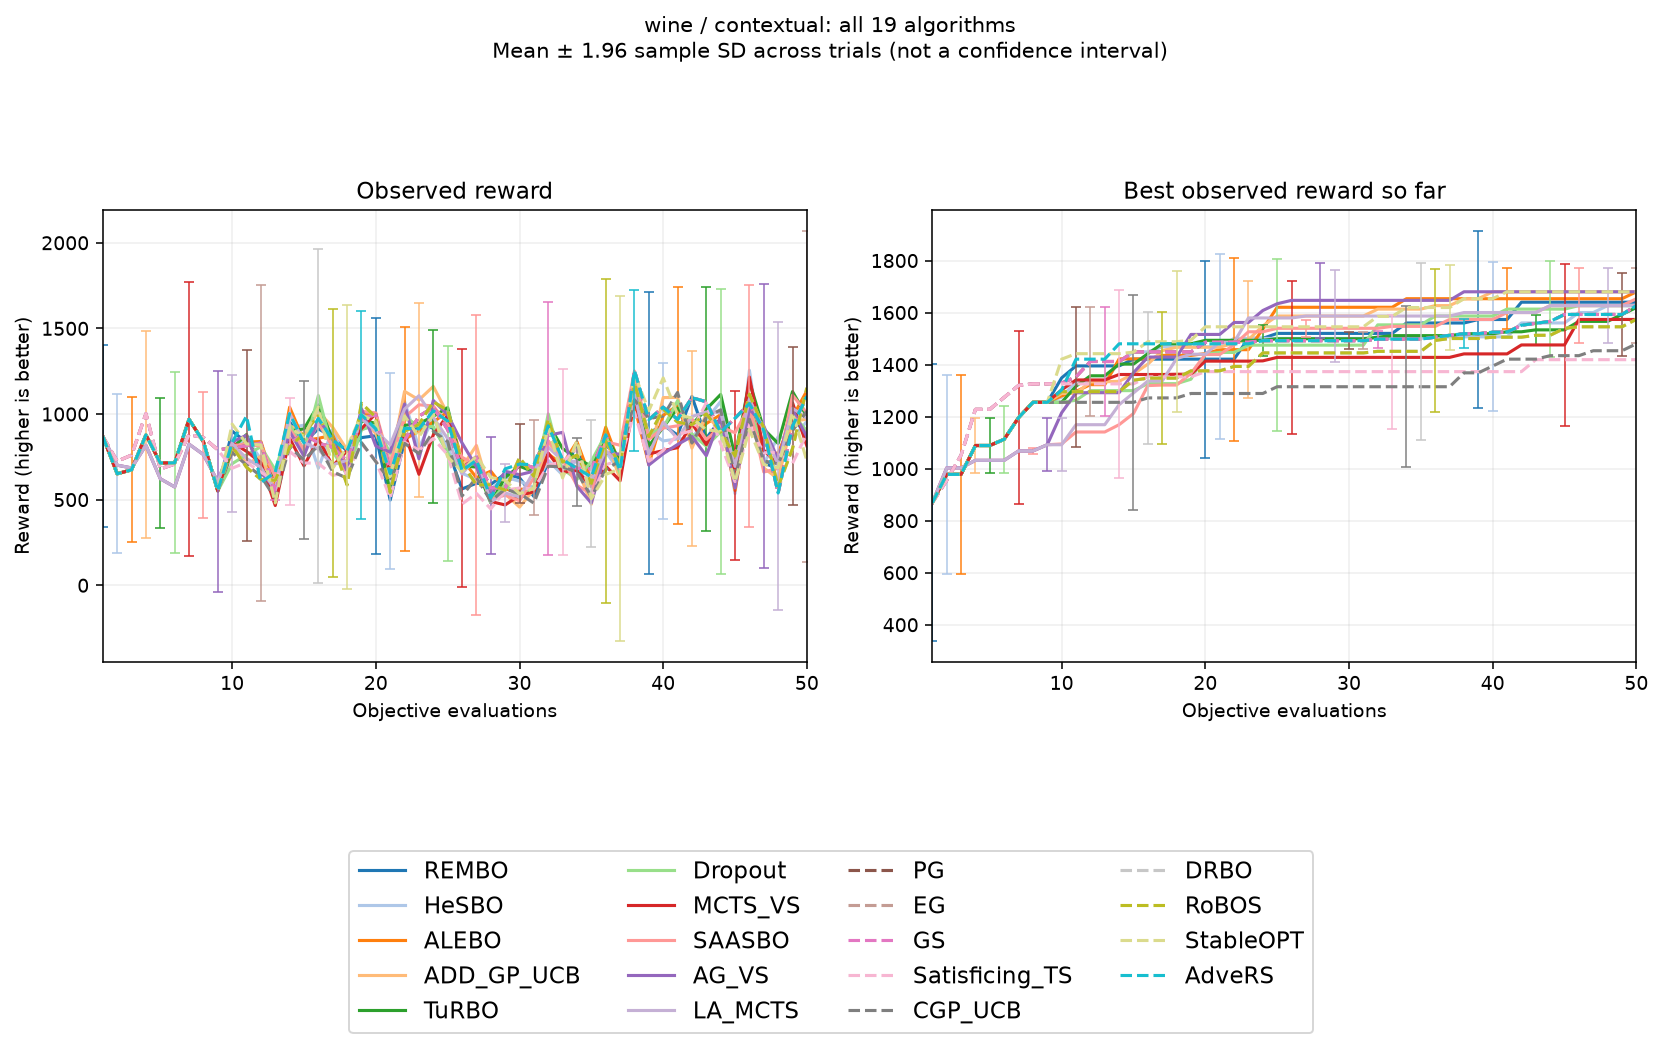

In [ ]:
import basat

seed = basat.set_seed(211, threads=1)
data_path = basat.find_path("data/contextual/wine_bandit.csv")
loaded = basat.load_dataset(data_path, environment="contextual")
print(loaded.preview(rows=3))
bounds = loaded.bounds
run_directory = basat.new_run_directory("results/last_guide/real_contextual")

# Fresh, fully explicit configurations for contextual observations.
# These bounded computation settings are editable examples.
# No setting overrides are hidden behind a profile.
dimension = bounds.dimension
reduced_dimension = min(2, dimension)
constructor_options = {
    'maximize': True,
    'dtype': 'float64',
    'device': 'cpu',
    'plot': False,
    'verbose': False,
    'verbose_setting': False,
    'verbose_iter_by_iter': False,
}

# Isotropic kernels model every input; no active coordinates are given.
action_kernel = basat.KernelConfig(
    name='rbf',
    ard_num_dims=None,
    active_dims=None,
    use_outputscale=True,
    lengthscale_prior=None,
    outputscale_prior=None,
    kwargs={},
)
context_kernel = basat.KernelConfig(
    name='rbf',
    ard_num_dims=None,
    active_dims=None,
    use_outputscale=True,
    lengthscale_prior=None,
    outputscale_prior=None,
    kwargs={},
)
ei = basat.AcquisitionConfig(
    name='EI',
    beta=2.5,
    xi=0.0,
    mc_samples=64,
    seed=seed,
)
ucb = basat.AcquisitionConfig(
    name='UCB',
    beta=2.5,
    xi=0.0,
    mc_samples=64,
    seed=seed,
)
contextual_solver = basat.AcquisitionOptimizerSpec(
    raw_samples=32,
    restarts=2,
    maxiter=50,
    fit_maxiter=50,
    solver_tolerance=1e-06,
)
distributional_solver = basat.ActionOptimizerSpec(
    raw_samples=24,
    restarts=2,
    maxiter=50,
    fit_maxiter=50,
)
robust_solver = basat.MultiStartSolver(
    method='multistart',
)

rembo_config = basat.REMBOConfig(
    embedding_dimension=reduced_dimension,
    finite_candidate_mode='project',
    Y_lower=None,
    Y_upper=None,
    kernel_type='low_dimensional',
    custom_kernel=None,
    acquisition='EI',
    initial_points=9,
    initial_points_sampling_method='uniform',
    batch_size=1,
    q_batch=None,
    lengthscale_lower=0.01,
    lengthscale_upper=50.0,
    initial_lengthscale=None,
    t_sigma=0.002,
    refit_interval=20,
    exploitation_count_limit=5,
    upper_bound_multiplier=0.9,
    seed=seed + 0,
)

hesbo_config = basat.HeSBOConfig(
    embedding_dimension=reduced_dimension,
    finite_candidate_mode='project',
    acquisition=ei,
    initial_points=9,
    initial_points_sampling_method='uniform',
    hash_family='paper',
    batch_size=1,
    q_batch=None,
    seed=seed + 1,
)

alebo_config = basat.ALEBOConfig(
    embedding_dimension=reduced_dimension,
    finite_candidate_mode='project',
    initial_points=9,
    initial_points_sampling_method='uniform',
    acquisition=ei,
    metric_inference='laplace',
    metric_posterior_samples=8,
    feasibility_tolerance=1e-09,
    acquisition_solver='slsqp',
    raw_feasible_samples=64,
    num_restarts=2,
    batch_size=1,
    q_batch=None,
    seed=seed + 2,
)

add_gp_ucb_config = basat.AddGPUCBConfig(
    groups=tuple((i,) for i in range(dimension)),
    maximum_group_size=1,
    learn_decomposition=False,
    decomposition_candidates=None,
    refresh_cycle=25,
    beta=2.5,
    initial_points=9,
    initial_points_sampling_method='uniform',
    component_optimizer=None,
    batch_size=1,
    q_batch=None,
    seed=seed + 3,
)

turbo_config = basat.TuRBOConfig(
    batch_size=1,
    q_batch=None,
    initial_points=9,
    initial_points_sampling_method='uniform',
    length_init=0.8,
    length_min=0.0078125,
    length_max=1.6,
    success_tolerance=3,
    failure_tolerance=None,
    candidate_count=128,
    perturbation_cap=20.0,
    acquisition=ei,
    success_relative_tolerance=0.001,
    noisy_center='posterior_mean',
    max_cholesky_size=2000,
    gp_training_steps=50,
    seed=seed + 4,
)

dropout_config = basat.DropoutConfig(
    active_dimension=reduced_dimension,
    fill_strategy='mix',
    random_fill_probability=0.1,
    beta=2.5,
    acquisition_optimizer=None,
    initial_points=9,
    initial_points_sampling_method='uniform',
    batch_size=1,
    q_batch=None,
    seed=seed + 5,
)

mcts_vs_config = basat.MCTSVSConfig(
    Nv=2,
    Ns=2,
    archive_size=20,
    initial_points=9,
    initial_points_sampling_method='uniform',
    bad_count_limit=5,
    split_threshold=3,
    exploration_constant=0.1,
    inner_optimizer='bo',
    candidate_pool_size=64,
    kernel_lengthscale=0.2,
    acquisition_beta=2.5,
    gp_maxiter=50,
    batch_size=1,
    q_batch=None,
    seed=seed + 6,
)

saasbo_config = basat.SAASBOConfig(
    shrinkage_scale=0.1,
    warmup_steps=64,
    posterior_samples=64,
    thinning=4,
    num_chains=1,
    initial_points=9,
    initial_points_sampling_method='uniform',
    acquisition='EI',
    max_tree_depth=4,
    target_accept_prob=0.8,
    num_restarts=2,
    raw_samples=32,
    mc_samples=32,
    ucb_beta=2.5,
    max_r_hat=1.1,
    min_effective_sample_size=10.0,
    allow_divergences=False,
    batch_size=1,
    q_batch=None,
    seed=seed + 7,
)

ag_vs_config = basat.AG_VSConfig(
    effective_dimension=reduced_dimension,
    sequence_length=2,
    split_groups=2,
    initial_points=9,
    initial_points_sampling_method='uniform',
    acquisition=ucb,
    stopping_threshold=None,
    stopping_delta=None,
    stagnation_patience=None,
    gp_fit_method='mle',
    gp_maxiter=50,
    acquisition_restarts=2,
    acquisition_raw_samples=64,
    batch_size=1,
    q_batch=None,
    seed=seed + 8,
)

la_mcts_config = basat.LAMCTSConfig(
    initial_points=9,
    initial_points_sampling_method='uniform',
    exploration_constant=1.0,
    split_threshold=12,
    min_child_size=3,
    max_depth=20,
    classifier='svm_rbf',
    local_sampler='turbo',
    candidate_pool_size=64,
    max_resampling_attempts=4,
    kernel_lengthscale=0.2,
    acquisition_beta=2.5,
    gp_maxiter=50,
    batch_size=1,
    q_batch=None,
    seed=seed + 9,
)

pg_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=9,
    initial_points_sampling_method='uniform',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 10,
)

eg_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=9,
    initial_points_sampling_method='uniform',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 11,
)

gs_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=9,
    initial_points_sampling_method='uniform',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 12,
)

satisficing_ts_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=9,
    initial_points_sampling_method='uniform',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 13,
)

cgp_ucb_config = basat.CGPUCBConfig(
    action_bounds=bounds,
    action_set=None,
    action_kernel=action_kernel,
    context_kernel=context_kernel,
    kernel_combination='product',
    beta=2.5,
    delta=0.1,
    finite_domain_cardinality=None,
    acquisition_optimizer=contextual_solver,
    initial_points=9,
    batch_size=1,
    q_batch=None,
    seed=seed + 14,
)

drbo_config = basat.DRBOConfig(
    context_kernel=context_kernel,
    action_kernel=action_kernel,
    beta=2.5,
    ambiguity_metric='mmd',
    inner_solver='slsqp',
    action_optimizer=distributional_solver,
    distribution_grid=None,
    enumeration_resolution=20,
    initial_points=9,
    feasibility_tolerance=1e-08,
    optimizer_tolerance=1e-06,
    batch_size=1,
    q_batch=None,
    seed=seed + 15,
)

robos_config = basat.RoBOSConfig(
    aspiration=-0.1,
    context_kernel=context_kernel,
    action_kernel=action_kernel,
    joint_kernel_combination='product',
    joint_kernel=None,
    beta=2.5,
    simplex_solver='slsqp',
    distribution_floor=0.0,
    distribution_grid=None,
    enumeration_resolution=20,
    action_raw_samples=24,
    action_restarts=2,
    action_maxiter=50,
    initial_points=9,
    fit_maxiter=50,
    feasibility_tolerance=1e-08,
    optimizer_tolerance=1e-06,
    batch_size=1,
    q_batch=None,
    seed=seed + 16,
)

stableopt_config = basat.StableOPTConfig(
    perturbation_radius=0.08,
    distance=basat.L2Distance(),
    beta=2.5,
    inner_solver=robust_solver,
    outer_solver=robust_solver,
    inner_raw_samples=16,
    outer_raw_samples=32,
    inner_restarts=2,
    outer_restarts=2,
    solver_tolerance=1e-06,
    initial_points=9,
    fit_maxiter=50,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 17,
)

advers_config = basat.AdveRSConfig(
    variant='RS1',
    aspiration=-0.1,
    p=1.0,
    beta=2.5,
    perturbation_domain=basat.FullDomainPerturbations(norm='l2', distance_floor=1e-8),
    candidate_solver=robust_solver,
    inner_solver=robust_solver,
    decision_model='ucb',
    outer_raw_samples=32,
    inner_raw_samples=16,
    radius_bisection_steps=8,
    solver_tolerance=1e-06,
    initial_points=9,
    fit_maxiter=50,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 18,
)

# SAASBO uses actual NUTS. Short chains can report poor ESS/divergences.
# Warnings retain finite draws; they do not certify convergence.
# For inference increase warmup/draws and use at least two chains.
algorithms = {
    'REMBO': basat.REMBO(
        bounds=bounds, config=rembo_config,
        **constructor_options,
    ),
    'HeSBO': basat.HeSBO(
        bounds=bounds, config=hesbo_config,
        **constructor_options,
    ),
    'ALEBO': basat.ALEBO(
        bounds=bounds, config=alebo_config,
        **constructor_options,
    ),
    'ADD_GP_UCB': basat.ADD_GP_UCB(
        bounds=bounds, config=add_gp_ucb_config,
        **constructor_options,
    ),
    'TuRBO': basat.TuRBO(
        bounds=bounds, config=turbo_config,
        **constructor_options,
    ),
    'Dropout': basat.Dropout(
        bounds=bounds, config=dropout_config,
        **constructor_options,
    ),
    'MCTS_VS': basat.MCTS_VS(
        bounds=bounds, config=mcts_vs_config,
        **constructor_options,
    ),
    'SAASBO': basat.SAASBO(
        bounds=bounds, config=saasbo_config,
        **constructor_options,
        diagnostic_policy='warn',
        jit_compile=True,
        mcmc_num_threads=1,
    ),
    'AG_VS': basat.AG_VS(
        bounds=bounds, config=ag_vs_config,
        **constructor_options,
    ),
    'LA_MCTS': basat.LA_MCTS(
        bounds=bounds, config=la_mcts_config,
        **constructor_options,
    ),
    'PG': basat.PG(
        bounds=bounds, config=pg_config,
        **constructor_options,
    ),
    'EG': basat.EG(
        bounds=bounds, config=eg_config,
        **constructor_options,
    ),
    'GS': basat.GS(
        bounds=bounds, config=gs_config,
        **constructor_options,
    ),
    'Satisficing_TS': basat.Satisficing_TS(
        bounds=bounds, config=satisficing_ts_config,
        **constructor_options,
    ),
    'CGP_UCB': basat.CGP_UCB(
        bounds=bounds, config=cgp_ucb_config,
        **constructor_options,
    ),
    'DRBO': basat.DRBO(
        bounds=bounds, config=drbo_config,
        **constructor_options,
    ),
    'RoBOS': basat.RoBOS(
        bounds=bounds, config=robos_config,
        **constructor_options,
    ),
    'StableOPT': basat.StableOPT(
        bounds=bounds, config=stableopt_config,
        **constructor_options,
    ),
    'AdveRS': basat.AdveRS(
        bounds=bounds, config=advers_config,
        **constructor_options,
    ),
}
print('Configured algorithms:', len(algorithms), list(algorithms))


environment = basat.ContextualEnvironment(
    bounds=bounds, dataset=loaded.dataset, function=None,
    context_provider=None,
    previous_data=None, dtype="float64", device="cpu",
    noise_std=0.0, noise_fn=None, add_noise_to_data=False,
    allow_repeated_actions=False, data_row_selection="first", seed=seed,
)

assert set(algorithms) == set(basat.algorithm_names())
print("Algorithms submitted:", len(algorithms))
print("Names:", list(algorithms))
experiment = basat.Experiment(
    environment=environment, algorithm=algorithms,
    output_directory=run_directory, resume=False, save_every=10,
    stopping_rule=None,
)
result = experiment.run(
    trials=5, max_evaluations=50, plot=False, show=False, progress=True,
)
print(experiment.summary())
print(experiment.diagnostics())
figure = basat.plot(
    experiment, kind="comparison", title="wine / contextual: all 19 algorithms",
    titles=("Observed reward", "Best observed reward so far"),
    xlabel="Objective evaluations", ylabel="Reward (higher is better)",
    figsize=(12.0, 7.5), xlim=(1, 50), grid=True,
    legend=True, legend_columns=4, legend_fontsize=12.0,
    save_path=basat.join_path(run_directory, "all_algorithms.png"),
    dpi=180, show=True,
)
print("Saved results:", run_directory)

### Distributional: wind_power / all 19 algorithms

Run this entire block independently. Its CSV path, full algorithm configurations, and environment are declared again here.

### Distributional wind-power commitment: dataset and replay

This replaces the breast-cancer example with hourly wind-generation data from
[Open Power System Data, version 2019-06-05](https://data.open-power-system-data.org/time_series/2019-06-05/),
the data package cited in [DRBO, Section 4](https://proceedings.mlr.press/v108/kirschner20a/kirschner20a.pdf).
The retained source contains 98 consecutive German hourly observations from January 2013: generation, capacity, and capacity factor.

The action is promised energy as a fraction of capacity; context is realized wind generation.
The paper's revenue is `0.1*max(c-x, 0) + min(x,c) - 5*max(x-c, 0)`.
Here, a complete CSV table evaluates that formula on 101 action values and 11 context values.
These revenues are calculated from an economic model; they are not recorded electricity payments.

The guide replays 50 consecutive hours after an initial 48-hour history, rounding recorded
capacity factors to the nearest 0.1. Each round's public reference uses only its preceding 48
observations. The environment's private sampling distribution puts probability one on that
hour's recorded, quantized realization; future context is not passed to the algorithm.
The fixed ambiguity margin 0.1 is illustrative, not calibrated to guarantee coverage.
Repeated commitments are allowed. All 19 methods receive the same chronological trace,
with 5 independent algorithm seeds and at most 50 evaluations each.

This small replay is an adaptation of the paper's application, not a reproduction of its
annual simulator experiment or robust-regret figures. The plotted observed reward and
best-observed reward do not measure robust regret; a lucky high-wind hour can improve the
latter. Because the physical action is one-dimensional, embedding dimension is also one;
this example does not demonstrate an advantage from high-dimensional embedding.

RoBOS uses a Matern-3/2 context kernel to avoid the initially configured RBF kernel's near-singular Gram matrix on this support. Completed trials of the other 18 methods were resumed unchanged; RoBOS was rerun.


action_0,context_0,reference_probability,sampling_probability,margin,reward
0.0,0.0,0.0,0.0,0.1,0.0
0.0,0.1,0.0,0.0,0.1,0.010000000000000002
0.0,0.2,0.0,0.0,0.1,0.020000000000000004
Configured algorithms: 19 ['REMBO', 'HeSBO', 'ALEBO', 'ADD_GP_UCB', 'TuRBO', 'Dropout', 'MCTS_VS', 'SAASBO', 'AG_VS', 'LA_MCTS', 'PG', 'EG', 'GS', 'Satisficing_TS', 'CGP_UCB', 'DRBO', 'RoBOS', 'StableOPT', 'AdveRS']
Algorithms submitted: 19
Names: ['REMBO', 'HeSBO', 'ALEBO', 'ADD_GP_UCB', 'TuRBO', 'Dropout', 'MCTS_VS', 'SAASBO', 'AG_VS', 'LA_MCTS', 'PG', 'EG', 'GS', 'Satisficing_TS', 'CGP_UCB', 'DRBO', 'RoBOS', 'StableOPT', 'AdveRS']
Trial 1/5 (seed offset +0)
[REMBO] starting


/Users/denizc/Desktop/BOlibrary/basat/experiment.py:750: REMBOWarning: REMBO is outside its native environment type ['stochastic'] in the 'distributional' environment. No required inputs are missing; no internal defaults were needed. Additional environment information is ignored.
  with (
/Users/denizc/Desktop/BOlibrary/basat/experiment.py:750: REMBOWarning: REMBO compresses available finite action rows into embedding coordinates and scores those rows directly. It returns the actual recorded action; rewards are not interpolated. Context, distribution and perturbation information are not used by this stochastic policy. This finite-data extension does not inherit the original embedding guarantees. Set finite_candidate_mode='exact' to require the original embedding geometry.
  with (
/Users/denizc/Desktop/BOlibrary/basat/experiment.py:750: HeSBOWarning: HeSBO is outside its native environment type ['stochastic'] in the 'distributional' environment. No required inputs are missing; no inter

[REMBO] evaluations=50, best=0.44999999999999996
[HeSBO] starting
[HeSBO] evaluations=50, best=0.6
[ALEBO] starting
[ALEBO] evaluations=50, best=0.519
[ADD_GP_UCB] starting
[ADD_GP_UCB] evaluations=50, best=0.06
[TuRBO] starting
[TuRBO] evaluations=50, best=0.5640000000000001
[Dropout] starting
[Dropout] evaluations=50, best=0.473
[MCTS_VS] starting
[MCTS_VS] evaluations=50, best=0.591
[SAASBO] starting
[SAASBO] evaluations=50, best=0.573
[AG_VS] starting
[AG_VS] evaluations=50, best=0.519
[LA_MCTS] starting
[LA_MCTS] evaluations=50, best=0.582
[PG] starting
[PG] evaluations=50, best=0.14100000000000001
[EG] starting
[EG] evaluations=50, best=0.14100000000000001
[GS] starting
[GS] evaluations=50, best=0.14100000000000001
[Satisficing_TS] starting
[Satisficing_TS] evaluations=50, best=0.51
[CGP_UCB] starting
[CGP_UCB] evaluations=50, best=0.384
[DRBO] starting
[DRBO] evaluations=50, best=0.06
[RoBOS] starting
[RoBOS] evaluations=50, best=0.06
[StableOPT] starting
[StableOPT] evaluations

/Users/denizc/Desktop/BOlibrary/basat/trials.py:279: REMBOWarning: REMBO is outside its native environment type ['stochastic'] in the 'distributional' environment. No required inputs are missing; no internal defaults were needed. Additional environment information is ignored.
  with experiment._capture_warnings("trial runs"):
/Users/denizc/Desktop/BOlibrary/basat/trials.py:279: REMBOWarning: REMBO compresses available finite action rows into embedding coordinates and scores those rows directly. It returns the actual recorded action; rewards are not interpolated. Context, distribution and perturbation information are not used by this stochastic policy. This finite-data extension does not inherit the original embedding guarantees. Set finite_candidate_mode='exact' to require the original embedding geometry.
  with experiment._capture_warnings("trial runs"):
/Users/denizc/Desktop/BOlibrary/basat/trials.py:279: HeSBOWarning: HeSBO is outside its native environment type ['stochastic'] in th

[REMBO] evaluations=50, best=0.555
[HeSBO] starting
[HeSBO] evaluations=50, best=0.6
[ALEBO] starting
[ALEBO] evaluations=50, best=0.519
[ADD_GP_UCB] starting
[ADD_GP_UCB] evaluations=50, best=0.06
[TuRBO] starting
[TuRBO] evaluations=50, best=0.5640000000000001
[Dropout] starting
[Dropout] evaluations=50, best=0.473
[MCTS_VS] starting
[MCTS_VS] evaluations=50, best=0.591
[SAASBO] starting
[SAASBO] evaluations=50, best=0.573
[AG_VS] starting
[AG_VS] evaluations=50, best=0.519
[LA_MCTS] starting
[LA_MCTS] evaluations=50, best=0.582
[PG] starting
[PG] evaluations=50, best=0.14100000000000001
[EG] starting
[EG] evaluations=50, best=0.14100000000000001
[GS] starting
[GS] evaluations=50, best=0.14100000000000001
[Satisficing_TS] starting
[Satisficing_TS] evaluations=50, best=0.51
[CGP_UCB] starting
[CGP_UCB] evaluations=50, best=0.384
[DRBO] starting
[DRBO] evaluations=50, best=0.06
[RoBOS] starting
[RoBOS] evaluations=50, best=0.06
[StableOPT] starting
[StableOPT] evaluations=50, best=0.54

/Users/denizc/Desktop/BOlibrary/basat/trials.py:279: SAASBOWarning: NUTS reported 3 divergent transitions. Finite, loadable posterior draws were retained under diagnostic_policy='warn'; source guarantees no longer apply.
  with experiment._capture_warnings("trial runs"):


[REMBO] evaluations=50, best=0.455
[HeSBO] starting
[HeSBO] evaluations=50, best=0.6
[ALEBO] starting
[ALEBO] evaluations=50, best=0.519
[ADD_GP_UCB] starting
[ADD_GP_UCB] evaluations=50, best=0.06
[TuRBO] starting
[TuRBO] evaluations=50, best=0.5640000000000001
[Dropout] starting
[Dropout] evaluations=50, best=0.473
[MCTS_VS] starting
[MCTS_VS] evaluations=50, best=0.591
[SAASBO] starting
[SAASBO] evaluations=50, best=0.573
[AG_VS] starting
[AG_VS] evaluations=50, best=0.519
[LA_MCTS] starting
[LA_MCTS] evaluations=50, best=0.582
[PG] starting
[PG] evaluations=50, best=0.14100000000000001
[EG] starting
[EG] evaluations=50, best=0.14100000000000001
[GS] starting
[GS] evaluations=50, best=0.14100000000000001
[Satisficing_TS] starting
[Satisficing_TS] evaluations=50, best=0.51
[CGP_UCB] starting
[CGP_UCB] evaluations=50, best=0.384
[DRBO] starting
[DRBO] evaluations=50, best=0.06
[RoBOS] starting
[RoBOS] evaluations=50, best=0.06
[StableOPT] starting
[StableOPT] evaluations=50, best=0.54

/Users/denizc/Desktop/BOlibrary/basat/trials.py:279: SAASBOWarning: NUTS reported 2 divergent transitions. Finite, loadable posterior draws were retained under diagnostic_policy='warn'; source guarantees no longer apply.
  with experiment._capture_warnings("trial runs"):


Basat: 5 trials
REMBO: evaluations per trial=[50, 50, 50, 50, 50]; failures=0; mean final incumbent=0.48519999999999996
HeSBO: evaluations per trial=[50, 50, 50, 50, 50]; failures=0; mean final incumbent=0.6
ALEBO: evaluations per trial=[50, 50, 50, 50, 50]; failures=0; mean final incumbent=0.519
ADD_GP_UCB: evaluations per trial=[50, 50, 50, 50, 50]; failures=0; mean final incumbent=0.06
TuRBO: evaluations per trial=[50, 50, 50, 50, 50]; failures=0; mean final incumbent=0.5640000000000001
Dropout: evaluations per trial=[50, 50, 50, 50, 50]; failures=0; mean final incumbent=0.473
MCTS_VS: evaluations per trial=[50, 50, 50, 50, 50]; failures=0; mean final incumbent=0.591
SAASBO: evaluations per trial=[50, 50, 50, 50, 50]; failures=0; mean final incumbent=0.573
AG_VS: evaluations per trial=[50, 50, 50, 50, 50]; failures=0; mean final incumbent=0.519
LA_MCTS: evaluations per trial=[50, 50, 50, 50, 50]; failures=0; mean final incumbent=0.582
PG: evaluations per trial=[50, 50, 50, 50, 50]; 

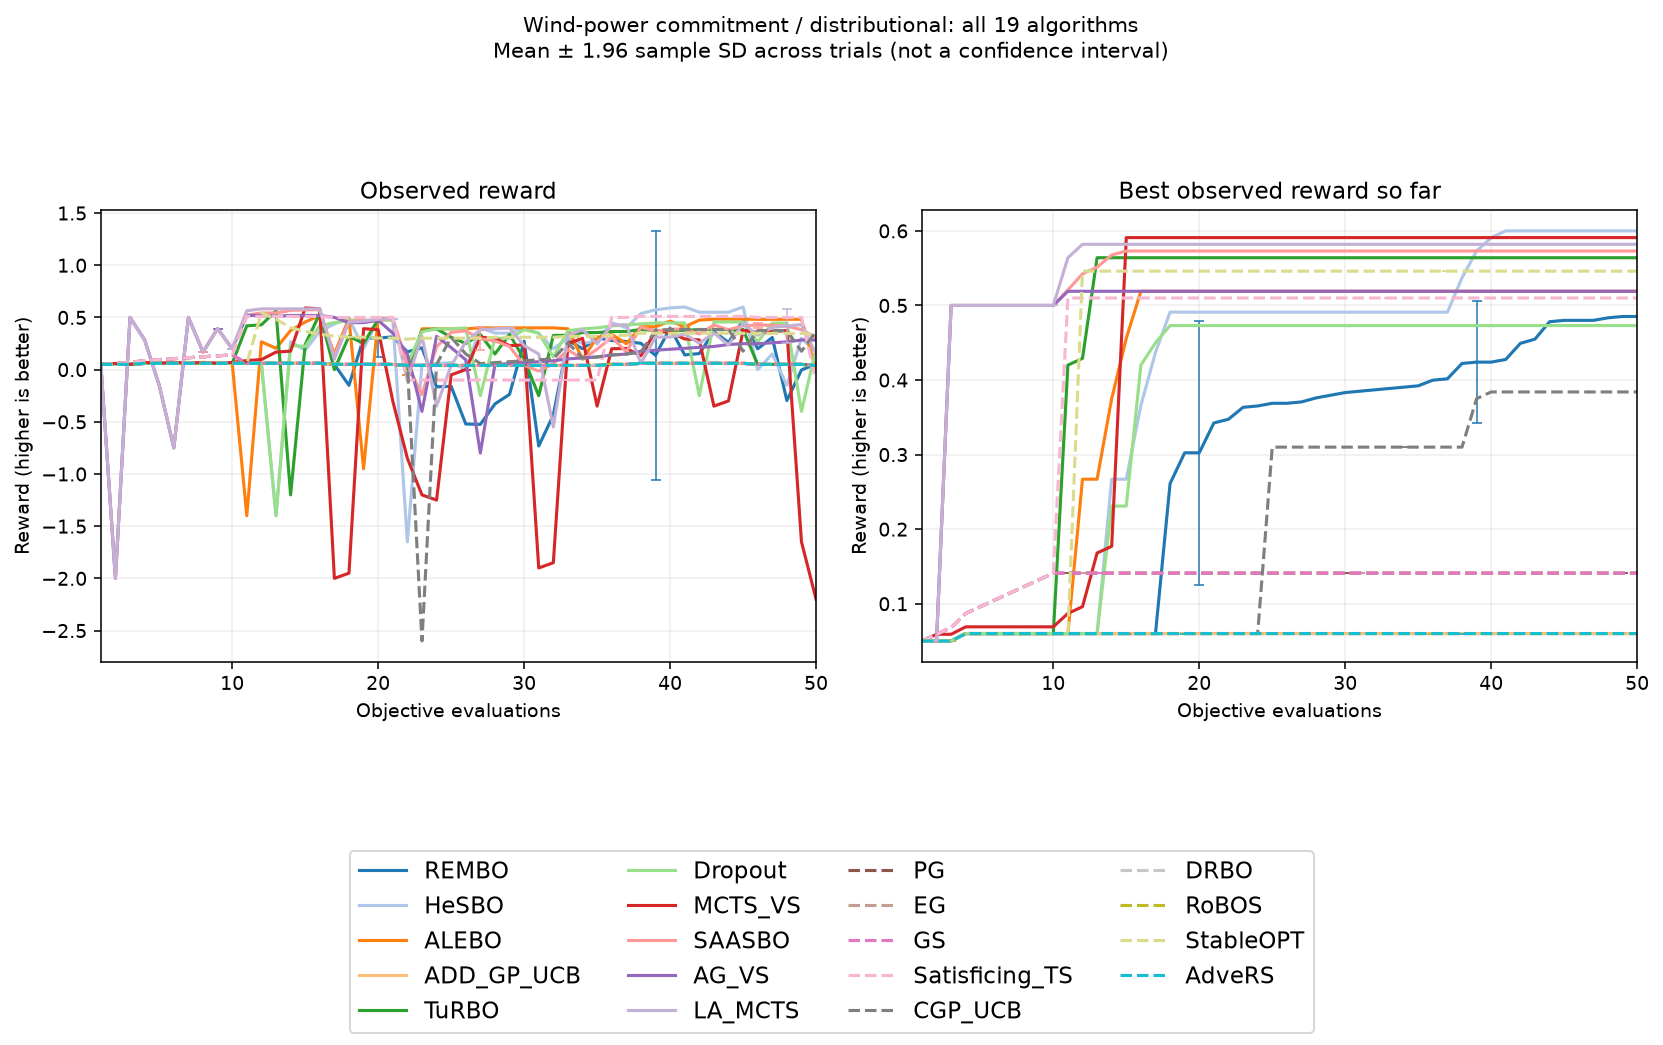

Saved results: results/last_guide/real_distributional_wind/run_matern_context


In [1]:
import basat

seed = basat.set_seed(212, threads=1)
data_path = basat.find_path("data/distributional/wind_power_bandit.csv")
loaded = basat.load_dataset(data_path, environment="distributional")
print(loaded.preview(rows=3))
bounds = loaded.bounds
# This named directory resumes saved trials. Choose another name for a fresh run.
run_directory = basat.join_path("results/last_guide/real_distributional_wind", "run_matern_context")

# Fresh, fully explicit configurations for distributional observations.
# These bounded computation settings are editable examples.
# No setting overrides are hidden behind a profile.
dimension = bounds.dimension
reduced_dimension = min(2, dimension)
constructor_options = {
    'maximize': True,
    'dtype': 'float64',
    'device': 'cpu',
    'plot': False,
    'verbose': False,
    'verbose_setting': False,
    'verbose_iter_by_iter': False,
}

# Isotropic kernels model every input; no active coordinates are given.
action_kernel = basat.KernelConfig(
    name='matern32',
    ard_num_dims=None,
    active_dims=None,
    use_outputscale=True,
    lengthscale_prior=None,
    outputscale_prior=None,
    kwargs={},
)
context_kernel = basat.KernelConfig(
    name='rbf',
    ard_num_dims=None,
    active_dims=None,
    use_outputscale=True,
    lengthscale_prior=None,
    outputscale_prior=None,
    kwargs={},
)
ei = basat.AcquisitionConfig(
    name='EI',
    beta=3.5,
    xi=0.0,
    mc_samples=64,
    seed=seed,
)
ucb = basat.AcquisitionConfig(
    name='UCB',
    beta=3.5,
    xi=0.0,
    mc_samples=64,
    seed=seed,
)
contextual_solver = basat.AcquisitionOptimizerSpec(
    raw_samples=32,
    restarts=2,
    maxiter=50,
    fit_maxiter=50,
    solver_tolerance=1e-06,
)
distributional_solver = basat.ActionOptimizerSpec(
    raw_samples=24,
    restarts=2,
    maxiter=50,
    fit_maxiter=50,
)
robust_solver = basat.MultiStartSolver(
    method='multistart',
)

rembo_config = basat.REMBOConfig(
    embedding_dimension=reduced_dimension,
    finite_candidate_mode='project',
    Y_lower=None,
    Y_upper=None,
    kernel_type='low_dimensional',
    custom_kernel=None,
    acquisition='EI',
    initial_points=10,
    initial_points_sampling_method='sobol',
    batch_size=1,
    q_batch=None,
    lengthscale_lower=0.01,
    lengthscale_upper=50.0,
    initial_lengthscale=None,
    t_sigma=0.002,
    refit_interval=20,
    exploitation_count_limit=5,
    upper_bound_multiplier=0.9,
    seed=seed + 0,
)

hesbo_config = basat.HeSBOConfig(
    embedding_dimension=reduced_dimension,
    finite_candidate_mode='project',
    acquisition=ei,
    initial_points=10,
    initial_points_sampling_method='sobol',
    hash_family='paper',
    batch_size=1,
    q_batch=None,
    seed=seed + 1,
)

alebo_config = basat.ALEBOConfig(
    embedding_dimension=reduced_dimension,
    finite_candidate_mode='project',
    initial_points=10,
    initial_points_sampling_method='sobol',
    acquisition=ei,
    metric_inference='laplace',
    metric_posterior_samples=8,
    feasibility_tolerance=1e-09,
    acquisition_solver='slsqp',
    raw_feasible_samples=64,
    num_restarts=2,
    batch_size=1,
    q_batch=None,
    seed=seed + 2,
)

add_gp_ucb_config = basat.AddGPUCBConfig(
    groups=tuple((i,) for i in range(dimension)),
    maximum_group_size=1,
    learn_decomposition=False,
    decomposition_candidates=None,
    refresh_cycle=25,
    beta=3.5,
    initial_points=10,
    initial_points_sampling_method='sobol',
    component_optimizer=None,
    batch_size=1,
    q_batch=None,
    seed=seed + 3,
)

turbo_config = basat.TuRBOConfig(
    batch_size=1,
    q_batch=None,
    initial_points=10,
    initial_points_sampling_method='sobol',
    length_init=0.8,
    length_min=0.0078125,
    length_max=1.6,
    success_tolerance=3,
    failure_tolerance=None,
    candidate_count=128,
    perturbation_cap=20.0,
    acquisition=ei,
    success_relative_tolerance=0.001,
    noisy_center='posterior_mean',
    max_cholesky_size=2000,
    gp_training_steps=50,
    seed=seed + 4,
)

dropout_config = basat.DropoutConfig(
    active_dimension=reduced_dimension,
    fill_strategy='mix',
    random_fill_probability=0.1,
    beta=3.5,
    acquisition_optimizer=None,
    initial_points=10,
    initial_points_sampling_method='sobol',
    batch_size=1,
    q_batch=None,
    seed=seed + 5,
)

mcts_vs_config = basat.MCTSVSConfig(
    Nv=2,
    Ns=2,
    archive_size=20,
    initial_points=10,
    initial_points_sampling_method='sobol',
    bad_count_limit=5,
    split_threshold=3,
    exploration_constant=0.1,
    inner_optimizer='bo',
    candidate_pool_size=64,
    kernel_lengthscale=0.2,
    acquisition_beta=3.5,
    gp_maxiter=50,
    batch_size=1,
    q_batch=None,
    seed=seed + 6,
)

saasbo_config = basat.SAASBOConfig(
    shrinkage_scale=0.1,
    warmup_steps=64,
    posterior_samples=64,
    thinning=4,
    num_chains=1,
    initial_points=10,
    initial_points_sampling_method='sobol',
    acquisition='EI',
    max_tree_depth=4,
    target_accept_prob=0.8,
    num_restarts=2,
    raw_samples=32,
    mc_samples=32,
    ucb_beta=3.5,
    max_r_hat=1.1,
    min_effective_sample_size=10.0,
    allow_divergences=False,
    batch_size=1,
    q_batch=None,
    seed=seed + 7,
)

ag_vs_config = basat.AG_VSConfig(
    effective_dimension=reduced_dimension,
    sequence_length=2,
    split_groups=2,
    initial_points=10,
    initial_points_sampling_method='sobol',
    acquisition=ucb,
    stopping_threshold=None,
    stopping_delta=None,
    stagnation_patience=None,
    gp_fit_method='mle',
    gp_maxiter=50,
    acquisition_restarts=2,
    acquisition_raw_samples=64,
    batch_size=1,
    q_batch=None,
    seed=seed + 8,
)

la_mcts_config = basat.LAMCTSConfig(
    initial_points=10,
    initial_points_sampling_method='sobol',
    exploration_constant=1.0,
    split_threshold=12,
    min_child_size=3,
    max_depth=20,
    classifier='svm_rbf',
    local_sampler='turbo',
    candidate_pool_size=64,
    max_resampling_attempts=4,
    kernel_lengthscale=0.2,
    acquisition_beta=3.5,
    gp_maxiter=50,
    batch_size=1,
    q_batch=None,
    seed=seed + 9,
)

pg_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=10,
    initial_points_sampling_method='sobol',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 10,
)

eg_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=10,
    initial_points_sampling_method='sobol',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 11,
)

gs_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=10,
    initial_points_sampling_method='sobol',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 12,
)

satisficing_ts_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=10,
    initial_points_sampling_method='sobol',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 13,
)

cgp_ucb_config = basat.CGPUCBConfig(
    action_bounds=bounds,
    action_set=None,
    action_kernel=action_kernel,
    context_kernel=context_kernel,
    kernel_combination='product',
    beta=3.5,
    delta=0.1,
    finite_domain_cardinality=None,
    acquisition_optimizer=contextual_solver,
    initial_points=10,
    batch_size=1,
    q_batch=None,
    seed=seed + 14,
)

drbo_config = basat.DRBOConfig(
    context_kernel=context_kernel,
    action_kernel=action_kernel,
    beta=3.5,
    ambiguity_metric='mmd',
    inner_solver='slsqp',
    action_optimizer=distributional_solver,
    distribution_grid=None,
    enumeration_resolution=20,
    initial_points=10,
    feasibility_tolerance=1e-08,
    optimizer_tolerance=1e-06,
    batch_size=1,
    q_batch=None,
    seed=seed + 15,
)

robos_config = basat.RoBOSConfig(
    aspiration=-0.1,
    # Matern is numerically well-conditioned on this 11-point context grid.
    context_kernel=basat.KernelConfig(name='matern32'),
    action_kernel=action_kernel,
    joint_kernel_combination='product',
    joint_kernel=None,
    beta=3.5,
    simplex_solver='slsqp',
    distribution_floor=0.0,
    distribution_grid=None,
    enumeration_resolution=20,
    action_raw_samples=24,
    action_restarts=2,
    action_maxiter=50,
    initial_points=10,
    fit_maxiter=50,
    feasibility_tolerance=1e-08,
    optimizer_tolerance=1e-06,
    batch_size=1,
    q_batch=None,
    seed=seed + 16,
)

stableopt_config = basat.StableOPTConfig(
    perturbation_radius=0.08,
    distance=basat.L2Distance(),
    beta=3.5,
    inner_solver=robust_solver,
    outer_solver=robust_solver,
    inner_raw_samples=16,
    outer_raw_samples=32,
    inner_restarts=2,
    outer_restarts=2,
    solver_tolerance=1e-06,
    initial_points=10,
    fit_maxiter=50,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 17,
)

advers_config = basat.AdveRSConfig(
    variant='RS1',
    aspiration=-0.1,
    p=1.0,
    beta=3.5,
    perturbation_domain=basat.FullDomainPerturbations(norm='l2', distance_floor=1e-8),
    candidate_solver=robust_solver,
    inner_solver=robust_solver,
    decision_model='ucb',
    outer_raw_samples=32,
    inner_raw_samples=16,
    radius_bisection_steps=8,
    solver_tolerance=1e-06,
    initial_points=10,
    fit_maxiter=50,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 18,
)

# SAASBO uses actual NUTS. Short chains can report poor ESS/divergences.
# Warnings retain finite draws; they do not certify convergence.
# For inference increase warmup/draws and use at least two chains.
algorithms = {
    'REMBO': basat.REMBO(
        bounds=bounds, config=rembo_config,
        **constructor_options,
    ),
    'HeSBO': basat.HeSBO(
        bounds=bounds, config=hesbo_config,
        **constructor_options,
    ),
    'ALEBO': basat.ALEBO(
        bounds=bounds, config=alebo_config,
        **constructor_options,
    ),
    'ADD_GP_UCB': basat.ADD_GP_UCB(
        bounds=bounds, config=add_gp_ucb_config,
        **constructor_options,
    ),
    'TuRBO': basat.TuRBO(
        bounds=bounds, config=turbo_config,
        **constructor_options,
    ),
    'Dropout': basat.Dropout(
        bounds=bounds, config=dropout_config,
        **constructor_options,
    ),
    'MCTS_VS': basat.MCTS_VS(
        bounds=bounds, config=mcts_vs_config,
        **constructor_options,
    ),
    'SAASBO': basat.SAASBO(
        bounds=bounds, config=saasbo_config,
        **constructor_options,
        diagnostic_policy='warn',
        jit_compile=True,
        mcmc_num_threads=1,
    ),
    'AG_VS': basat.AG_VS(
        bounds=bounds, config=ag_vs_config,
        **constructor_options,
    ),
    'LA_MCTS': basat.LA_MCTS(
        bounds=bounds, config=la_mcts_config,
        **constructor_options,
    ),
    'PG': basat.PG(
        bounds=bounds, config=pg_config,
        **constructor_options,
    ),
    'EG': basat.EG(
        bounds=bounds, config=eg_config,
        **constructor_options,
    ),
    'GS': basat.GS(
        bounds=bounds, config=gs_config,
        **constructor_options,
    ),
    'Satisficing_TS': basat.Satisficing_TS(
        bounds=bounds, config=satisficing_ts_config,
        **constructor_options,
    ),
    'CGP_UCB': basat.CGP_UCB(
        bounds=bounds, config=cgp_ucb_config,
        **constructor_options,
    ),
    'DRBO': basat.DRBO(
        bounds=bounds, config=drbo_config,
        **constructor_options,
    ),
    'RoBOS': basat.RoBOS(
        bounds=bounds, config=robos_config,
        **constructor_options,
    ),
    'StableOPT': basat.StableOPT(
        bounds=bounds, config=stableopt_config,
        **constructor_options,
    ),
    'AdveRS': basat.AdveRS(
        bounds=bounds, config=advers_config,
        **constructor_options,
    ),
}
print('Configured algorithms:', len(algorithms), list(algorithms))


# Real hourly German wind generation, from the data package cited by DRBO.
# This CSV subset has no quoted fields; column 4 is recorded capacity factor.
with open(basat.find_path("data/distributional/opsd_wind_2013.csv")) as stream:
    source_lines = stream.read().splitlines()
wind_profiles = [float(line.split(",")[3]) for line in source_lines[1:99]]
# Fixed 11-point support: quantize observed capacity factors to nearest 0.1.
wind_indices = tuple(min(10, max(0, int(value * 10 + 0.5))) for value in wind_profiles)
assert len(wind_indices) == 98  # 48 history hours + 50 evaluation hours


def reference_at_round(round_index):
    # Only past observations contribute to the public 48-hour reference.
    history = wind_indices[round_index:round_index + 48]
    return [history.count(j) / len(history) for j in range(11)]


def realized_wind_at_round(round_index):
    # The environment keeps this next observation private until evaluation.
    if not 0 <= round_index < 50:
        raise ValueError("This replay contains 50 evaluation hours.")
    actual_index = wind_indices[48 + round_index]
    return [float(j == actual_index) for j in range(11)]


# Every CSV reward is calculated from the paper's revenue formula:
# def objective(x, c):
#     return 0.1 * max(c - x, 0) + min(x, c) - 5 * max(x - c, 0)
# x and c are fractions of installed capacity. Revenue is modeled, not measured.
# The initial CSV probabilities are overridden by the providers above.
environment = basat.DistributionalEnvironment(
    bounds=bounds, dataset=loaded.dataset, function=None,
    context_support=loaded.context_support,
    reference_distribution=reference_at_round,
    sampling_distribution=realized_wind_at_round,
    margin=loaded.margin,
    previous_data=None, dtype="float64", device="cpu",
    noise_std=0.0, noise_fn=None, add_noise_to_data=False,
    allow_repeated_actions=True, data_row_selection="first", seed=seed,
)

assert set(algorithms) == set(basat.algorithm_names())
print("Algorithms submitted:", len(algorithms))
print("Names:", list(algorithms))
experiment = basat.Experiment(
    environment=environment, algorithm=algorithms,
    output_directory=run_directory, resume=True, save_every=10,
    stopping_rule=None,
)
result = experiment.run(
    trials=5, max_evaluations=50, plot=False, show=False, progress=True,
)
print(experiment.summary())
print(experiment.diagnostics())
figure = basat.plot(
    experiment, kind="comparison", title="Wind-power commitment / distributional: all 19 algorithms",
    titles=("Observed reward", "Best observed reward so far"),
    xlabel="Objective evaluations", ylabel="Reward (higher is better)",
    figsize=(12.0, 7.5), xlim=(1, 50), grid=True,
    legend=True, legend_columns=4, legend_fontsize=12.0,
    save_path=basat.join_path(run_directory, "all_algorithms.png"),
    dpi=180, show=True,
)
print("Saved results:", run_directory)

### Adversarial: iris / all 19 algorithms

Run this entire block independently. Its CSV path, full algorithm configurations, and environment are declared again here.

Saved-result refresh (no optimization was executed).
Source: results/last_guide/real_adversarial/run_mimnzoy_/results.json
Trials: 5/5; limits: {'max_evaluations': 50, 'max_rounds': None}
Algorithm | evaluations per trial | final mean best reward | failures
REMBO | [50, 50, 50, 50, 50] | 7.74 | 0
HeSBO | [50, 50, 50, 50, 50] | 7.7 | 0
ALEBO | [50, 50, 50, 50, 50] | 7.74 | 0
ADD_GP_UCB | [50, 50, 50, 50, 50] | 7.7 | 0
TuRBO | [50, 50, 50, 50, 50] | 7.7 | 0
Dropout | [50, 50, 50, 50, 50] | 7.7 | 0
MCTS_VS | [50, 50, 50, 50, 50] | 7.7 | 0
SAASBO | [50, 50, 50, 50, 50] | 7.74 | 0
AG_VS | [50, 50, 50, 50, 50] | 7.7 | 0
LA_MCTS | [50, 50, 50, 50, 50] | 7.9 | 0
PG | [50, 50, 50, 50, 50] | 7.7 | 0
EG | [50, 50, 50, 50, 50] | 7.7 | 0
GS | [50, 50, 50, 50, 50] | 7.7 | 0
Satisficing_TS | [50, 50, 50, 50, 50] | 7 | 0
CGP_UCB | [50, 50, 50, 50, 50] | 7.7 | 0
DRBO | [50, 50, 50, 50, 50] | 7.7 | 0
RoBOS | [50, 50, 50, 50, 50] | 7.7 | 0
StableOPT | [50, 50, 50, 50, 50] | 7.9 | 0
AdveRS | [50, 50, 50, 

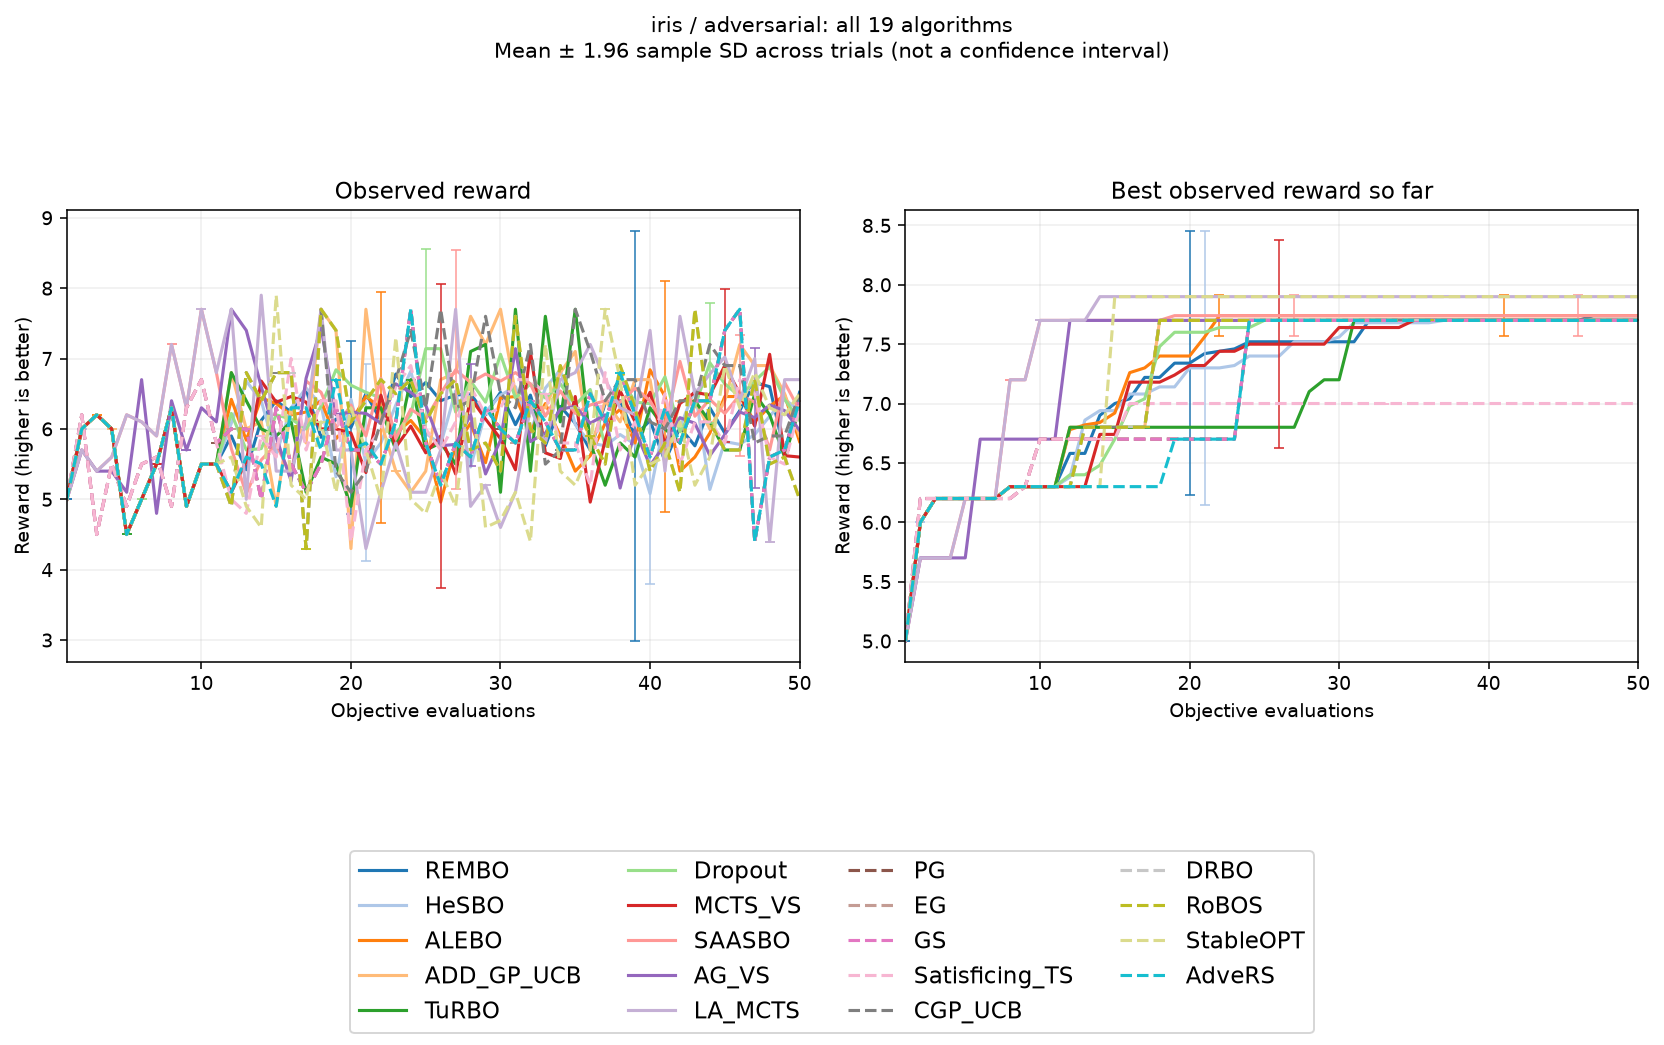

In [ ]:
import basat

seed = basat.set_seed(213, threads=1)
data_path = basat.find_path("data/adversarial/iris_bandit.csv")
loaded = basat.load_dataset(data_path, environment="adversarial")
print(loaded.preview(rows=3))
bounds = loaded.bounds
run_directory = basat.new_run_directory("results/last_guide/real_adversarial")

# Fresh, fully explicit configurations for adversarial observations.
# These bounded computation settings are editable examples.
# No setting overrides are hidden behind a profile.
dimension = bounds.dimension
reduced_dimension = min(2, dimension)
constructor_options = {
    'maximize': True,
    'dtype': 'float64',
    'device': 'cpu',
    'plot': False,
    'verbose': False,
    'verbose_setting': False,
    'verbose_iter_by_iter': False,
}

# Isotropic kernels model every input; no active coordinates are given.
action_kernel = basat.KernelConfig(
    name='matern52',
    ard_num_dims=None,
    active_dims=None,
    use_outputscale=True,
    lengthscale_prior=None,
    outputscale_prior=None,
    kwargs={},
)
context_kernel = basat.KernelConfig(
    name='rbf',
    ard_num_dims=None,
    active_dims=None,
    use_outputscale=True,
    lengthscale_prior=None,
    outputscale_prior=None,
    kwargs={},
)
ei = basat.AcquisitionConfig(
    name='EI',
    beta=4.0,
    xi=0.0,
    mc_samples=64,
    seed=seed,
)
ucb = basat.AcquisitionConfig(
    name='UCB',
    beta=4.0,
    xi=0.0,
    mc_samples=64,
    seed=seed,
)
contextual_solver = basat.AcquisitionOptimizerSpec(
    raw_samples=32,
    restarts=2,
    maxiter=50,
    fit_maxiter=50,
    solver_tolerance=1e-06,
)
distributional_solver = basat.ActionOptimizerSpec(
    raw_samples=24,
    restarts=2,
    maxiter=50,
    fit_maxiter=50,
)
robust_solver = basat.MultiStartSolver(
    method='multistart',
)

rembo_config = basat.REMBOConfig(
    embedding_dimension=reduced_dimension,
    finite_candidate_mode='project',
    Y_lower=None,
    Y_upper=None,
    kernel_type='low_dimensional',
    custom_kernel=None,
    acquisition='EI',
    initial_points=11,
    initial_points_sampling_method='uniform',
    batch_size=1,
    q_batch=None,
    lengthscale_lower=0.01,
    lengthscale_upper=50.0,
    initial_lengthscale=None,
    t_sigma=0.002,
    refit_interval=20,
    exploitation_count_limit=5,
    upper_bound_multiplier=0.9,
    seed=seed + 0,
)

hesbo_config = basat.HeSBOConfig(
    embedding_dimension=reduced_dimension,
    finite_candidate_mode='project',
    acquisition=ei,
    initial_points=11,
    initial_points_sampling_method='uniform',
    hash_family='paper',
    batch_size=1,
    q_batch=None,
    seed=seed + 1,
)

alebo_config = basat.ALEBOConfig(
    embedding_dimension=reduced_dimension,
    finite_candidate_mode='project',
    initial_points=11,
    initial_points_sampling_method='uniform',
    acquisition=ei,
    metric_inference='laplace',
    metric_posterior_samples=8,
    feasibility_tolerance=1e-09,
    acquisition_solver='slsqp',
    raw_feasible_samples=64,
    num_restarts=2,
    batch_size=1,
    q_batch=None,
    seed=seed + 2,
)

add_gp_ucb_config = basat.AddGPUCBConfig(
    groups=tuple((i,) for i in range(dimension)),
    maximum_group_size=1,
    learn_decomposition=False,
    decomposition_candidates=None,
    refresh_cycle=25,
    beta=4.0,
    initial_points=11,
    initial_points_sampling_method='uniform',
    component_optimizer=None,
    batch_size=1,
    q_batch=None,
    seed=seed + 3,
)

turbo_config = basat.TuRBOConfig(
    batch_size=1,
    q_batch=None,
    initial_points=11,
    initial_points_sampling_method='uniform',
    length_init=0.8,
    length_min=0.0078125,
    length_max=1.6,
    success_tolerance=3,
    failure_tolerance=None,
    candidate_count=128,
    perturbation_cap=20.0,
    acquisition=ei,
    success_relative_tolerance=0.001,
    noisy_center='posterior_mean',
    max_cholesky_size=2000,
    gp_training_steps=50,
    seed=seed + 4,
)

dropout_config = basat.DropoutConfig(
    active_dimension=reduced_dimension,
    fill_strategy='mix',
    random_fill_probability=0.1,
    beta=4.0,
    acquisition_optimizer=None,
    initial_points=11,
    initial_points_sampling_method='uniform',
    batch_size=1,
    q_batch=None,
    seed=seed + 5,
)

mcts_vs_config = basat.MCTSVSConfig(
    Nv=2,
    Ns=2,
    archive_size=20,
    initial_points=11,
    initial_points_sampling_method='uniform',
    bad_count_limit=5,
    split_threshold=3,
    exploration_constant=0.1,
    inner_optimizer='bo',
    candidate_pool_size=64,
    kernel_lengthscale=0.2,
    acquisition_beta=4.0,
    gp_maxiter=50,
    batch_size=1,
    q_batch=None,
    seed=seed + 6,
)

saasbo_config = basat.SAASBOConfig(
    shrinkage_scale=0.1,
    warmup_steps=64,
    posterior_samples=64,
    thinning=4,
    num_chains=1,
    initial_points=11,
    initial_points_sampling_method='uniform',
    acquisition='EI',
    max_tree_depth=4,
    target_accept_prob=0.8,
    num_restarts=2,
    raw_samples=32,
    mc_samples=32,
    ucb_beta=4.0,
    max_r_hat=1.1,
    min_effective_sample_size=10.0,
    allow_divergences=False,
    batch_size=1,
    q_batch=None,
    seed=seed + 7,
)

ag_vs_config = basat.AG_VSConfig(
    effective_dimension=reduced_dimension,
    sequence_length=2,
    split_groups=2,
    initial_points=11,
    initial_points_sampling_method='uniform',
    acquisition=ucb,
    stopping_threshold=None,
    stopping_delta=None,
    stagnation_patience=None,
    gp_fit_method='mle',
    gp_maxiter=50,
    acquisition_restarts=2,
    acquisition_raw_samples=64,
    batch_size=1,
    q_batch=None,
    seed=seed + 8,
)

la_mcts_config = basat.LAMCTSConfig(
    initial_points=11,
    initial_points_sampling_method='uniform',
    exploration_constant=1.0,
    split_threshold=12,
    min_child_size=3,
    max_depth=20,
    classifier='svm_rbf',
    local_sampler='turbo',
    candidate_pool_size=64,
    max_resampling_attempts=4,
    kernel_lengthscale=0.2,
    acquisition_beta=4.0,
    gp_maxiter=50,
    batch_size=1,
    q_batch=None,
    seed=seed + 9,
)

pg_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=11,
    initial_points_sampling_method='uniform',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 10,
)

eg_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=11,
    initial_points_sampling_method='uniform',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 11,
)

gs_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=11,
    initial_points_sampling_method='uniform',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 12,
)

satisficing_ts_config = basat.GoodActionConfig(
    threshold=-0.1,
    candidate_domain=None,
    initial_points=11,
    initial_points_sampling_method='uniform',
    hyperparameter_refit_cycle=3,
    acquisition_restarts=2,
    reference_point=None,
    lookahead_samples=8,
    maximum_value_samples=8,
    candidate_samples=32,
    fit_maxiter=50,
    posterior_std_floor=1e-12,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 13,
)

cgp_ucb_config = basat.CGPUCBConfig(
    action_bounds=bounds,
    action_set=None,
    action_kernel=action_kernel,
    context_kernel=context_kernel,
    kernel_combination='product',
    beta=4.0,
    delta=0.1,
    finite_domain_cardinality=None,
    acquisition_optimizer=contextual_solver,
    initial_points=11,
    batch_size=1,
    q_batch=None,
    seed=seed + 14,
)

drbo_config = basat.DRBOConfig(
    context_kernel=context_kernel,
    action_kernel=action_kernel,
    beta=4.0,
    ambiguity_metric='mmd',
    inner_solver='slsqp',
    action_optimizer=distributional_solver,
    distribution_grid=None,
    enumeration_resolution=20,
    initial_points=11,
    feasibility_tolerance=1e-08,
    optimizer_tolerance=1e-06,
    batch_size=1,
    q_batch=None,
    seed=seed + 15,
)

robos_config = basat.RoBOSConfig(
    aspiration=-0.1,
    context_kernel=context_kernel,
    action_kernel=action_kernel,
    joint_kernel_combination='product',
    joint_kernel=None,
    beta=4.0,
    simplex_solver='slsqp',
    distribution_floor=0.0,
    distribution_grid=None,
    enumeration_resolution=20,
    action_raw_samples=24,
    action_restarts=2,
    action_maxiter=50,
    initial_points=11,
    fit_maxiter=50,
    feasibility_tolerance=1e-08,
    optimizer_tolerance=1e-06,
    batch_size=1,
    q_batch=None,
    seed=seed + 16,
)

stableopt_config = basat.StableOPTConfig(
    perturbation_radius=2.0,
    distance=basat.L2Distance(),
    beta=4.0,
    inner_solver=robust_solver,
    outer_solver=robust_solver,
    inner_raw_samples=16,
    outer_raw_samples=32,
    inner_restarts=2,
    outer_restarts=2,
    solver_tolerance=1e-06,
    initial_points=11,
    fit_maxiter=50,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 17,
)

advers_config = basat.AdveRSConfig(
    variant='RS1',
    aspiration=-0.1,
    p=1.0,
    beta=4.0,
    perturbation_domain=basat.FullDomainPerturbations(norm='l2', distance_floor=1e-8),
    candidate_solver=robust_solver,
    inner_solver=robust_solver,
    decision_model='ucb',
    outer_raw_samples=32,
    inner_raw_samples=16,
    radius_bisection_steps=8,
    solver_tolerance=1e-06,
    initial_points=11,
    fit_maxiter=50,
    kernel=action_kernel,
    batch_size=1,
    q_batch=None,
    seed=seed + 18,
)

# SAASBO uses actual NUTS. Short chains can report poor ESS/divergences.
# Warnings retain finite draws; they do not certify convergence.
# For inference increase warmup/draws and use at least two chains.
algorithms = {
    'REMBO': basat.REMBO(
        bounds=bounds, config=rembo_config,
        **constructor_options,
    ),
    'HeSBO': basat.HeSBO(
        bounds=bounds, config=hesbo_config,
        **constructor_options,
    ),
    'ALEBO': basat.ALEBO(
        bounds=bounds, config=alebo_config,
        **constructor_options,
    ),
    'ADD_GP_UCB': basat.ADD_GP_UCB(
        bounds=bounds, config=add_gp_ucb_config,
        **constructor_options,
    ),
    'TuRBO': basat.TuRBO(
        bounds=bounds, config=turbo_config,
        **constructor_options,
    ),
    'Dropout': basat.Dropout(
        bounds=bounds, config=dropout_config,
        **constructor_options,
    ),
    'MCTS_VS': basat.MCTS_VS(
        bounds=bounds, config=mcts_vs_config,
        **constructor_options,
    ),
    'SAASBO': basat.SAASBO(
        bounds=bounds, config=saasbo_config,
        **constructor_options,
        diagnostic_policy='warn',
        jit_compile=True,
        mcmc_num_threads=1,
    ),
    'AG_VS': basat.AG_VS(
        bounds=bounds, config=ag_vs_config,
        **constructor_options,
    ),
    'LA_MCTS': basat.LA_MCTS(
        bounds=bounds, config=la_mcts_config,
        **constructor_options,
    ),
    'PG': basat.PG(
        bounds=bounds, config=pg_config,
        **constructor_options,
    ),
    'EG': basat.EG(
        bounds=bounds, config=eg_config,
        **constructor_options,
    ),
    'GS': basat.GS(
        bounds=bounds, config=gs_config,
        **constructor_options,
    ),
    'Satisficing_TS': basat.Satisficing_TS(
        bounds=bounds, config=satisficing_ts_config,
        **constructor_options,
    ),
    'CGP_UCB': basat.CGP_UCB(
        bounds=bounds, config=cgp_ucb_config,
        **constructor_options,
    ),
    'DRBO': basat.DRBO(
        bounds=bounds, config=drbo_config,
        **constructor_options,
    ),
    'RoBOS': basat.RoBOS(
        bounds=bounds, config=robos_config,
        **constructor_options,
    ),
    'StableOPT': basat.StableOPT(
        bounds=bounds, config=stableopt_config,
        **constructor_options,
    ),
    'AdveRS': basat.AdveRS(
        bounds=bounds, config=advers_config,
        **constructor_options,
    ),
}
print('Configured algorithms:', len(algorithms), list(algorithms))


environment = basat.AdversarialEnvironment(
    bounds=bounds, dataset=loaded.dataset, function=None,
    attack=loaded.attack,
    previous_data=None, dtype="float64", device="cpu",
    noise_std=0.0, noise_fn=None, add_noise_to_data=False,
    allow_repeated_actions=False, data_row_selection="first", seed=seed,
)

assert set(algorithms) == set(basat.algorithm_names())
print("Algorithms submitted:", len(algorithms))
print("Names:", list(algorithms))
experiment = basat.Experiment(
    environment=environment, algorithm=algorithms,
    output_directory=run_directory, resume=False, save_every=10,
    stopping_rule=None,
)
result = experiment.run(
    trials=5, max_evaluations=50, plot=False, show=False, progress=True,
)
print(experiment.summary())
print(experiment.diagnostics())
figure = basat.plot(
    experiment, kind="comparison", title="iris / adversarial: all 19 algorithms",
    titles=("Observed reward", "Best observed reward so far"),
    xlabel="Objective evaluations", ylabel="Reward (higher is better)",
    figsize=(12.0, 7.5), xlim=(1, 50), grid=True,
    legend=True, legend_columns=4, legend_fontsize=12.0,
    save_path=basat.join_path(run_directory, "all_algorithms.png"),
    dpi=180, show=True,
)
print("Saved results:", run_directory)

# 3. Early Stopping

The eight preceding main comparisons used only a 50-evaluation cap. Here we
explicitly enable other stopping mechanisms. `make_stopping()` returns fresh
rule instances because patience tracks history. A multi-algorithm Experiment
clones the supplied rule for each child; progress in one method cannot stop
another. Each example below is independent.

| Rule | Meaning |
|---|---|
| MaximumEvaluationsStoppingRule | Stop after the allowed number of evaluated actions, counting initialization |
| MaximumRoundsStoppingRule | Limit ask/tell rounds; a batch can contain several evaluations |
| MaximumTimeStoppingRule | Check elapsed time between complete rounds; does not interrupt an optimizer |
| TargetValueStoppingRule | Stop when the best observed reward reaches a target |
| NoImprovementStoppingRule | Stop after patience rounds without improvement exceeding min_delta, after min_rounds |
| any_of / all_of | Compose conditions; any condition versus every condition |

`run(max_evaluations=50)` remains a separate hard safety cap. If a full batch
would exceed the remaining budget, the runner stops before that batch rather
than changing its acquisition semantics. For batch size 3, a cap of 50 can
therefore end at 48 evaluations. Rule checks occur at completed-round boundaries.
No-improvement and target rules concern observed rewards; noise can trigger
them without finding the latent optimum. Method-specific posterior stopping
is separate: AG_VS accepts `stopping_threshold` and `stopping_delta` together;
leaving both as None disables it. Its `stagnation_patience` causes internal
reinitialization, not experiment termination.

Saved-result refresh (no optimization was executed).
Source: results/last_guide/early_patience/run_49k90o_1/results.json
Trials: 5/5; limits: {'max_evaluations': 50, 'max_rounds': None}
Algorithm | evaluations per trial | final mean best reward | failures
TuRBO / patience | [27, 25, 33, 37, 33] | -0.00012339228 | 0
AG_VS / patience | [39, 24, 32, 32, 20] | -0.00057300596 | 0
Total recorded evaluations: 302; failed trials: 0

Recorded stopping reasons by trial:
TuRBO / patience: ['any_of:no_improvement', 'any_of:no_improvement', 'any_of:no_improvement', 'any_of:no_improvement', 'any_of:no_improvement']
AG_VS / patience: ['any_of:no_improvement', 'any_of:no_improvement', 'any_of:no_improvement', 'any_of:no_improvement', 'any_of:no_improvement']

Recorded warnings (deduplicated per algorithm):
AG_VS / patience: BasatNumericalWarning: Basat numerical event during GP hyperparameter fitting (training-covariance Cholesky): Negative variance values detected. This is likely due to numerical ins

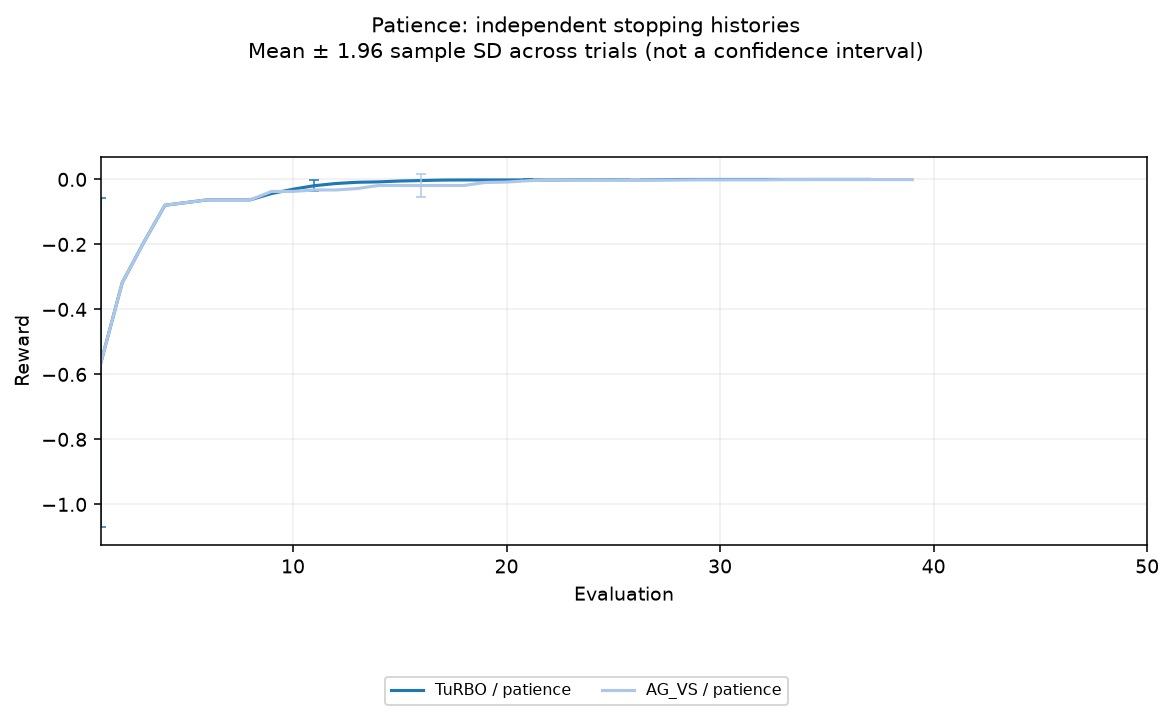

In [ ]:
import basat

seed = basat.set_seed(310, threads=1)
run_directory = basat.new_run_directory("results/last_guide/early_patience")
bounds = basat.Bounds(lower=[0.0] * 3, upper=[1.0] * 3)

def objective(values):
    return -sum((x - 0.25) ** 2 for x in values)

def make_stopping():
    return basat.any_of(
        basat.MaximumEvaluationsStoppingRule(50),
        basat.NoImprovementStoppingRule(
            10, min_rounds=20, min_delta=0.001,
        ),
    )

algorithms = {
    "TuRBO / patience": basat.TuRBO(
        bounds=bounds, config=basat.TuRBOConfig(
            initial_points=8, candidate_count=128, seed=seed,
        ), dtype="float64",
    ),
    "AG_VS / patience": basat.AG_VS(
        bounds=bounds, config=basat.AG_VSConfig(
            effective_dimension=2, initial_points=8, sequence_length=2,
            acquisition_restarts=2, acquisition_raw_samples=32, seed=seed,
            stopping_threshold=None, stopping_delta=None,
        ), dtype="float64",
    ),
}
experiment = basat.Experiment(
    environment=basat.StochasticEnvironment(
        bounds=bounds, function=objective, dtype="float64", seed=seed,
    ), algorithm=algorithms, stopping_rule=make_stopping(),
    output_directory=run_directory,
)
result = experiment.run(trials=5, max_evaluations=50, plot=False, progress=True)
print(experiment.summary())
figure = basat.plot(
    experiment, kind="incumbent", title="Patience: independent stopping histories",
    xlim=(1, 50), save_path=basat.join_path(run_directory, "patience.png"),
)

Saved-result refresh (no optimization was executed).
Source: results/last_guide/early_composition/run_ls4_mgd8/result.json
Trials: 5/5; limits: {'max_evaluations': 50, 'max_rounds': None}
Algorithm | evaluations per trial | final mean best reward | failures
TuRBO | [12, 12, 12, 12, 12] | -0.022895036 | 0
Total recorded evaluations: 60; failed trials: 0

Recorded stopping reasons by trial:
TuRBO: ['any_of:all_of:maximum_rounds,target_value', 'any_of:all_of:maximum_rounds,target_value', 'any_of:all_of:maximum_rounds,target_value', 'any_of:all_of:maximum_rounds,target_value', 'any_of:all_of:maximum_rounds,target_value']

Saved results: results/last_guide/early_composition/run_ls4_mgd8


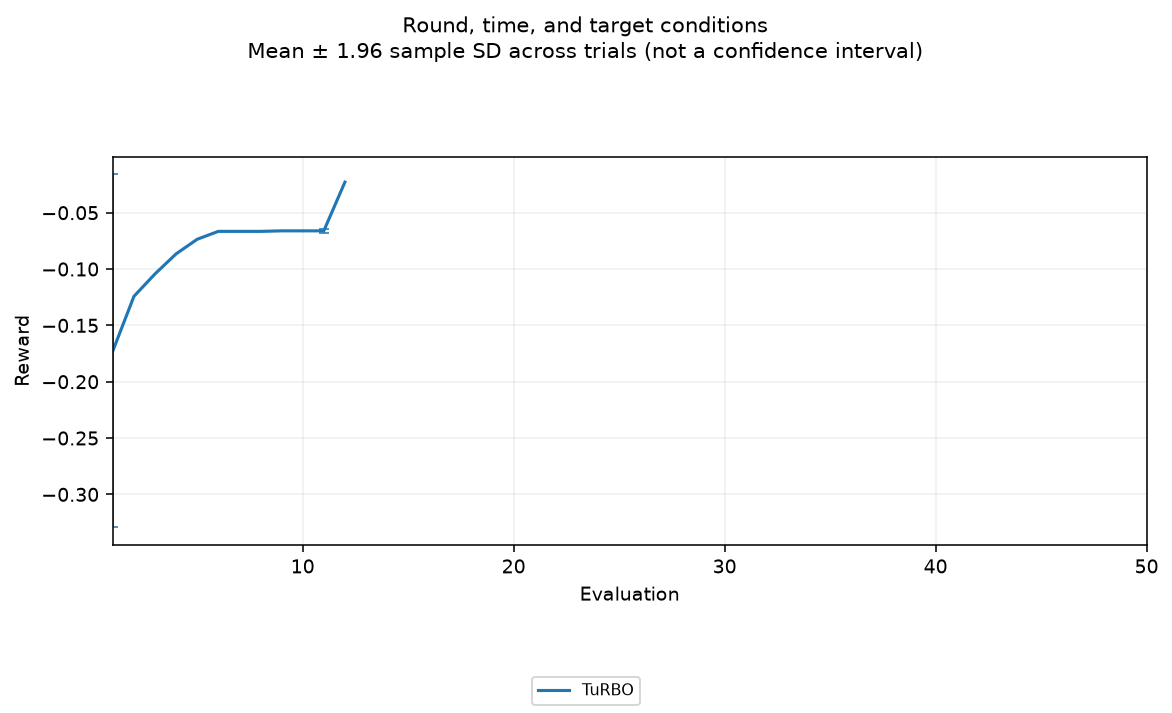

In [ ]:
import basat

seed = basat.set_seed(311, threads=1)
run_directory = basat.new_run_directory("results/last_guide/early_composition")
bounds = basat.Bounds(lower=[0.0] * 3, upper=[1.0] * 3)

def objective(values):
    return -sum((x - 0.5) ** 2 for x in values)

def make_stopping():
    return basat.any_of(
        basat.MaximumEvaluationsStoppingRule(50),
        basat.MaximumRoundsStoppingRule(35),
        basat.MaximumTimeStoppingRule(20.0),
        basat.all_of(
            basat.MaximumRoundsStoppingRule(12),
            basat.TargetValueStoppingRule(-0.05, maximize=True),
        ),
    )

algorithm = basat.TuRBO(
    bounds=bounds,
    config=basat.TuRBOConfig(
        initial_points=8, candidate_count=128,
        acquisition=basat.AcquisitionConfig(name="EI", xi=0.0, seed=seed),
        seed=seed,
    ), dtype="float64",
)
experiment = basat.Experiment(
    environment=basat.StochasticEnvironment(
        bounds=bounds, function=objective, dtype="float64", seed=seed,
    ), algorithm=algorithm, stopping_rule=make_stopping(),
    output_directory=run_directory,
)
result = experiment.run(trials=5, max_evaluations=50, plot=False)
print(experiment.summary())
print("Triggered conditions by trial:", [
    trial.stopping_decision for trial in experiment.trial_experiments
])
figure = basat.plot(
    experiment, kind="incumbent", title="Round, time, and target conditions",
    xlim=(1, 50), save_path=basat.join_path(run_directory, "conditions.png"),
)

## Accuracy and interpretation of the measured results

Every large experiment reports warnings, failed contracts, actual evaluation
counts, and captured output. A common best-observed-reward trace is useful for
inspecting execution; it is not the same as every method's mathematical
objective. Contextual rewards depend on context. DRBO optimizes a worst-case
distributional value; StableOPT uses robust confidence bounds. A high noisy
observation alone does not establish robustness or global convergence.

Internal zero-context, point-mass-distribution and zero-perturbation defaults
are interoperability extensions. The original papers do not claim that these
choices recover native contextual, distributional or adversarial performance
in every environment. The environment still owns action evaluation and reward
feedback. Warnings identify the assumptions changed for execution; a curve
obtained under an adaptation must be interpreted under that adaptation.

The numerical audit found and fixed a DRBO local-search defect: an accepted
solver endpoint could be worse than the already-scored start, and flat
surfaces could make Powell drift toward a boundary. After successful solver
certification, the implementation now re-certifies and retains the start
unless refinement improves it beyond tolerance. All-failed solver cases still
raise. Focused tests cover worse endpoints, plateaus, and certification.

ALEBO's constrained acquisition optimizer could reject every local endpoint
despite having usable feasible candidates. A reproduced failure after 43
evaluations had SLSQP reporting success with constraint residuals of
3.24e-9 and 2.18e-7, above the configured 1e-9 feasibility tolerance. It now
screens the feasible candidate pool, refines its best starts with analytic
gradients when available, and independently verifies each endpoint. It
retains the best finite feasible candidate when refinement cannot improve
it; refinement diagnostics remain visible as warnings. Feasible screening
and constrained gradient refinement follow the
[official Ax ALEBO acquisition optimizer](https://github.com/facebook/Ax/blob/0.1.17/ax/models/torch/alebo.py#L470-L526)
and the [paper's constrained search domain](https://proceedings.neurips.cc/paper_files/paper/2020/file/10fb6cfa4c990d2bad5ddef4f70e8ba2-Paper.pdf).
The correction preserves the polytope and metric-inference model; it does
not relax feasibility or establish global acquisition optimality. Targeted
tests cover infeasible and worse local endpoints. The failing checkpoint
subsequently continued to 50 evaluations, and a fresh five-trial check
completed all five 50-evaluation runs with feasible actions.

This ALEBO correction concerns acquisition search only. The existing option
named `metric_inference="laplace"` records fixed-scale Gaussian perturbations
of fitted lower-factor parameters; it does not derive a Laplace covariance
from the posterior Hessian. Acquisition decisions still use the fitted GP,
rather than averaging over those recorded metric samples. The displayed
results therefore do not establish equivalence to the paper's integrated
metric inference. That separate modeling limitation remains explicit.

Checkpoint checks compare resumed actions and rewards with uninterrupted
runs, including independent trial random states and an interruption after
an environment measurement was committed but before algorithm feedback.
Restoring the GoodAction family's GP warm start and fitting cadence prevents
continuation from silently following a different numerical path. Immutable
setting mismatches and corrupt checkpoints are rejected before replacing
saved aggregate results. These checks concern Basat's state; external
simulators and side-effecting objectives need their own durable state.

A separate bounded resume audit covered all 19 methods in their native
environments with two seeds each. It checkpointed after each method's
initial design (8-11 evaluations) and continued through two model-based
choices: resumed actions and rewards
matched uninterrupted runs exactly in this audit. Its records are retained
in `results/resume_catalog/validation.json`. This small continuation check
complements the five-trial guide experiments; it is not a claim of exact
reproducibility across every device, dependency version or external system.

The frozen implementation passed 694 automated tests, Ruff checks and Mypy
checks. The built wheel was checked against all 72 library source files and
contains no datasets. This evidence establishes the checked behavior and
packaging scope, rather than an exhaustive proof of every possible setting.

The audit checked DRBO's max-min expected UCB, StableOPT's UCB/LCB ordering,
and CGP_UCB's joint action-context predictions against their primary sources:
[DRBO](https://proceedings.mlr.press/v108/kirschner20a/kirschner20a.pdf),
[StableOPT](https://arxiv.org/html/1810.10775v2), and
[CGP_UCB](https://proceedings.neurips.cc/paper/2011/file/f3f1b7fc5a8779a9e618e1f23a7b7860-Paper.pdf).
[SAASBO](https://proceedings.mlr.press/v161/eriksson21a.html) uses genuine NUTS
inference here, but the short displayed chains do not establish convergence.

A warning such as “NUTS reported 4 divergent transitions” concerns four
numerical integration trajectories in that GP fit, not four failed objective
evaluations. A later warning reporting one divergence belongs to a later fit.
Finite posterior draws can still be biased. `diagnostic_policy="warn"` retains
usable draws and continues with source guarantees invalidated;
`diagnostic_policy="raise", allow_divergences=False` rejects the fit instead.
The line in `experiment.py` identifies where the warning is surfaced.

The main SAASBO configurations expose `target_accept_prob=0.8`. To investigate
divergences, edit it to `0.95` and increase `warmup_steps` (for example 512).
Larger `posterior_samples` and multiple `num_chains` can improve assessment
of ESS and R-hat, but extra samples alone do not cure divergences. These
changes cost time and do not guarantee reliable inference. Do not suppress
warnings to claim convergence. See the
[Stan NUTS diagnostic guidance](https://mc-stan.org/docs/2_39/cmdstan-guide/diagnose_utility.html).

For `AcquisitionConfig`, CGP_UCB and DRBO, UCB is mean + sqrt(beta) *
standard deviation; a paper using
coefficient b * standard deviation needs beta=b*b for a numeric match.
MCTS_VS uses its separate `acquisition_beta` as a direct multiplier.

AG_VS refers to a local manuscript whose complete source was unavailable for
this audit. Its tests exercise the implemented equations and invariants; an
independent paper-faithfulness certification cannot be claimed. These finite
runs and targeted checks do not prove every configuration of all 19 algorithms.
Numerical negative-variance warnings can arise from cancellation or ill-conditioned
covariance matrices. Finite precision, variance floors, jitter and explicit
fit-failure diagnostics remain visible; a warning is not hidden by the guide.

# 4. Different Settings Examples

These shorter examples show selected changes without repeating all optional
fields. Omitted values use the public configuration class defaults. Each block
still defines its own input, algorithms, environment, and output directory.
Each run goes through `Experiment.run` and stays within 50 evaluations.

## Defaults and a list of algorithms

This example passes a Python list of algorithm instances. `TuRBOConfig`
uses its defaults except for the displayed seed: initialization and candidate
count are resolved from dimension, and its default acquisition is Thompson
sampling. The printed config shows None for dimension-resolved defaults.
Required AG_VS effective dimension remains an explicit scientific choice.
Passing just `algorithms[0]` instead of the list uses the same runner for one
algorithm. There is no second comparison interface and no profile variable.

Saved-result refresh (no optimization was executed).
Source: results/last_guide/defaults/run_lnhzix6f/results.json
Trials: 5/5; limits: {'max_evaluations': 50, 'max_rounds': None}
Algorithm | evaluations per trial | final mean best reward | failures
TuRBO | [50, 50, 50, 50, 50] | -4.0088652e-05 | 0
AG_VS | [50, 50, 50, 50, 50] | -0.0013197799 | 0
Total recorded evaluations: 500; failed trials: 0

Recorded stopping reasons by trial:
TuRBO: ['maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations']
AG_VS: ['maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations']

Recorded warnings (deduplicated per algorithm):
TuRBO: BasatJitterWarning: Basat added diagonal jitter=1.0e-06 during GP posterior sampling because the covariance matrix was not positive definite.
AG_VS: BasatNumericalWarning: Basat numerical event during GP hyperparameter fitting (training-covariance Cholesky): Neg

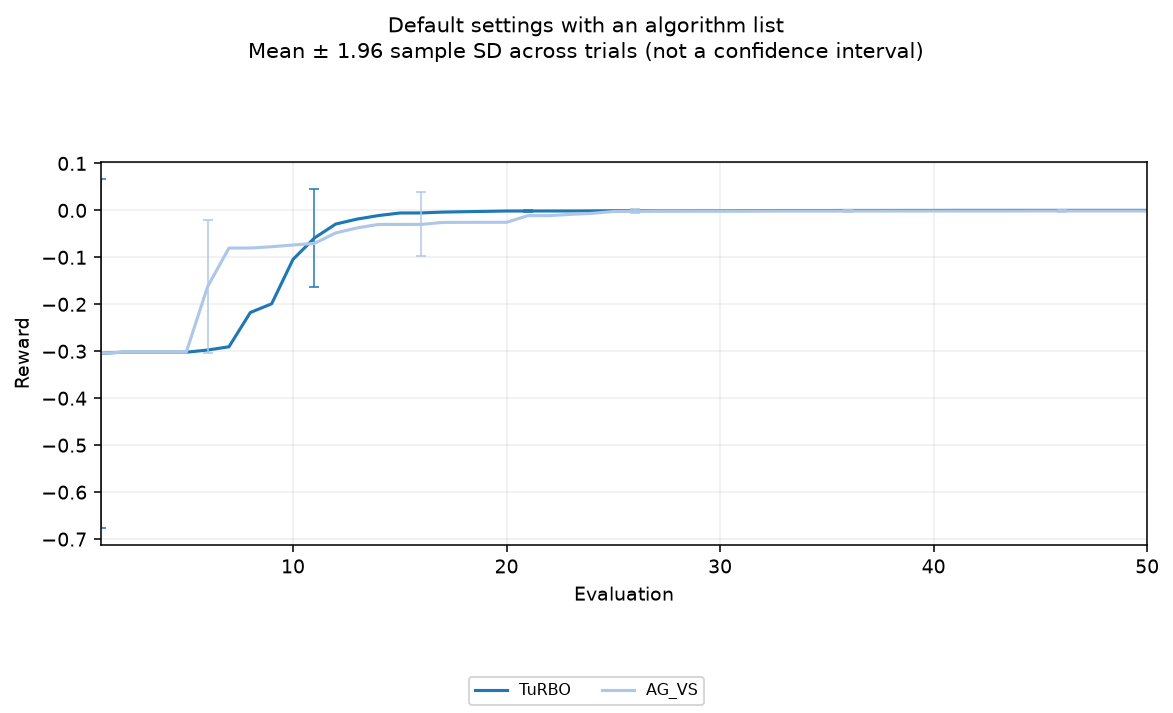

In [ ]:
import basat

seed = basat.set_seed(410, threads=1)
run_directory = basat.new_run_directory("results/last_guide/defaults")
bounds = basat.Bounds(lower=[0.0] * 3, upper=[1.0] * 3)

def objective(values):
    return -sum((x - 0.3) ** 2 for x in values)

algorithms = [
    basat.TuRBO(
        bounds=bounds, config=basat.TuRBOConfig(seed=seed), dtype="float64",
    ),
    basat.AG_VS(
        bounds=bounds,
        config=basat.AG_VSConfig(effective_dimension=2, seed=seed),
        dtype="float64",
    ),
]
print("TuRBO defaults:", algorithms[0].config)
experiment = basat.Experiment(
    environment=basat.StochasticEnvironment(
        bounds=bounds, function=objective, dtype="float64", seed=seed,
    ), algorithm=algorithms, output_directory=run_directory,
)
result = experiment.run(trials=5, max_evaluations=50, plot=False, progress=True)
print(experiment.summary())
figure = basat.plot(
    experiment, kind="incumbent", title="Default settings with an algorithm list",
    xlim=(1, 50), save_path=basat.join_path(run_directory, "defaults.png"),
)

## Acquisition settings: UCB beta and EI offset

The three named configurations below all use TuRBO, with explicit EI/UCB
extensions. UCB beta=9 has uncertainty multiplier 3; beta=3 has multiplier
sqrt(3). `xi=0.01` changes EI's improvement threshold. These are comparisons
of acquisition settings within the displayed trust-region implementation,
not three separate algorithm families.

Saved-result refresh (no optimization was executed).
Source: results/last_guide/acquisitions/run_2zxmczxf/results.json
Trials: 5/5; limits: {'max_evaluations': 50, 'max_rounds': None}
Algorithm | evaluations per trial | final mean best reward | failures
UCB beta=3 | [50, 50, 50, 50, 50] | -1.738164e-05 | 0
UCB beta=9 | [50, 50, 50, 50, 50] | -3.4245462e-05 | 0
EI xi=0.01 | [50, 50, 50, 50, 50] | -3.6684806e-05 | 0
Total recorded evaluations: 750; failed trials: 0

Recorded stopping reasons by trial:
UCB beta=3: ['maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations']
UCB beta=9: ['maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations']
EI xi=0.01: ['maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations']

Saved results: results/last_guide/acquisitions/run_2zxmczxf


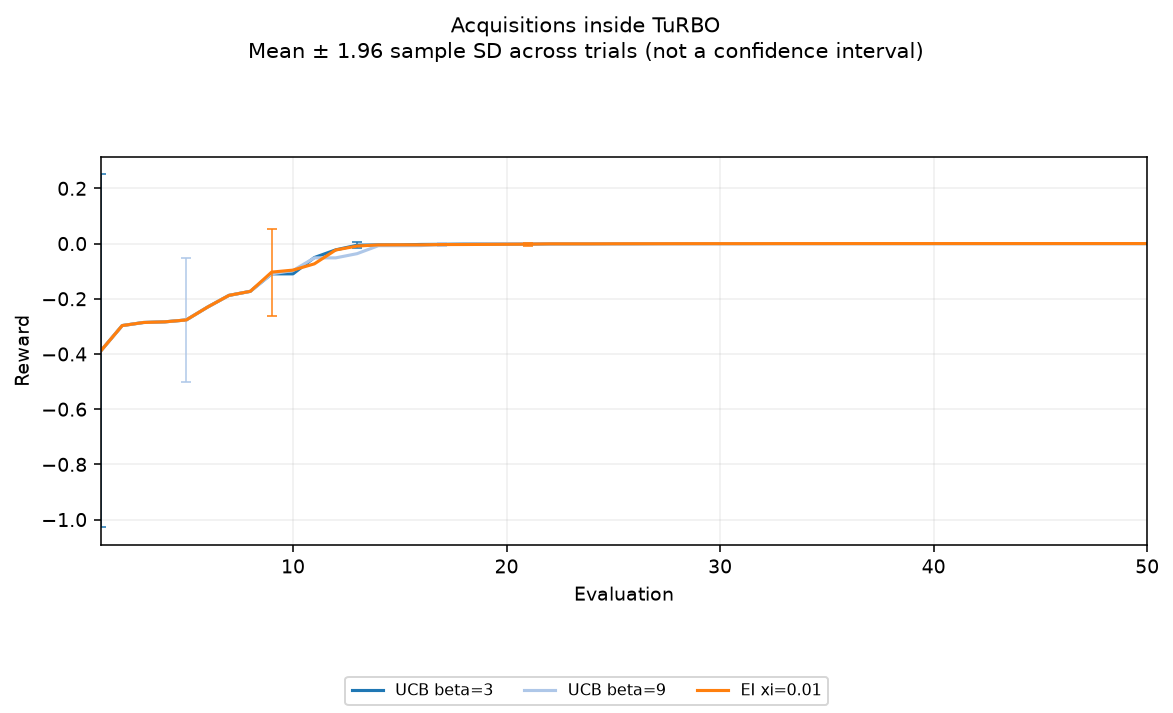

In [ ]:
import basat

seed = basat.set_seed(411, threads=1)
run_directory = basat.new_run_directory("results/last_guide/acquisitions")
bounds = basat.Bounds(lower=[0.0] * 3, upper=[1.0] * 3)

def objective(values):
    return -sum((x - 0.4) ** 2 for x in values)

algorithms = {
    "UCB beta=3": basat.TuRBO(
        bounds=bounds, config=basat.TuRBOConfig(
            acquisition=basat.AcquisitionConfig(name="UCB", beta=3.0, seed=seed),
            initial_points=8, candidate_count=128, seed=seed,
        ), dtype="float64",
    ),
    "UCB beta=9": basat.TuRBO(
        bounds=bounds, config=basat.TuRBOConfig(
            acquisition=basat.AcquisitionConfig(name="UCB", beta=9.0, seed=seed),
            initial_points=8, candidate_count=128, seed=seed,
        ), dtype="float64",
    ),
    "EI xi=0.01": basat.TuRBO(
        bounds=bounds, config=basat.TuRBOConfig(
            acquisition=basat.AcquisitionConfig(name="EI", xi=0.01, seed=seed),
            initial_points=8, candidate_count=128, seed=seed,
        ), dtype="float64",
    ),
}
experiment = basat.Experiment(
    environment=basat.StochasticEnvironment(
        bounds=bounds, function=objective, dtype="float64", seed=seed,
    ), algorithm=algorithms, output_directory=run_directory,
)
result = experiment.run(trials=5, max_evaluations=50, plot=False, progress=True)
print(experiment.summary())
figure = basat.plot(
    experiment, kind="incumbent", title="Acquisitions inside TuRBO",
    xlim=(1, 50), save_path=basat.join_path(run_directory, "acquisitions.png"),
)

## GP kernels inside a contextual real-data experiment

Here the kernel changes the surrogate used to choose measured Wine rows.
We compare three CGP_UCB configurations on the same dataset and seed, with
the same fixed beta and optimizer budgets. The context kernel operates on
one-hot cultivar, while the action kernel operates on the three scaled
descriptors. These are optimization runs, not drawings of kernel functions.

Saved-result refresh (no optimization was executed).
Source: results/last_guide/real_kernels/run_azy89pl6/results.json
Trials: 5/5; limits: {'max_evaluations': 50, 'max_rounds': None}
Algorithm | evaluations per trial | final mean best reward | failures
CGP_UCB / RBF | [50, 50, 50, 50, 50] | 1586.8 | 0
CGP_UCB / Matern32 | [50, 50, 50, 50, 50] | 1586.8 | 0
CGP_UCB / Matern52 | [50, 50, 50, 50, 50] | 1560 | 0
Total recorded evaluations: 750; failed trials: 0

Recorded stopping reasons by trial:
CGP_UCB / RBF: ['maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations']
CGP_UCB / Matern32: ['maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations']
CGP_UCB / Matern52: ['maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations']

Recorded warnings (deduplicated per algorithm):
CGP_UCB / RBF: BasatNumericalWarning: Basat numer

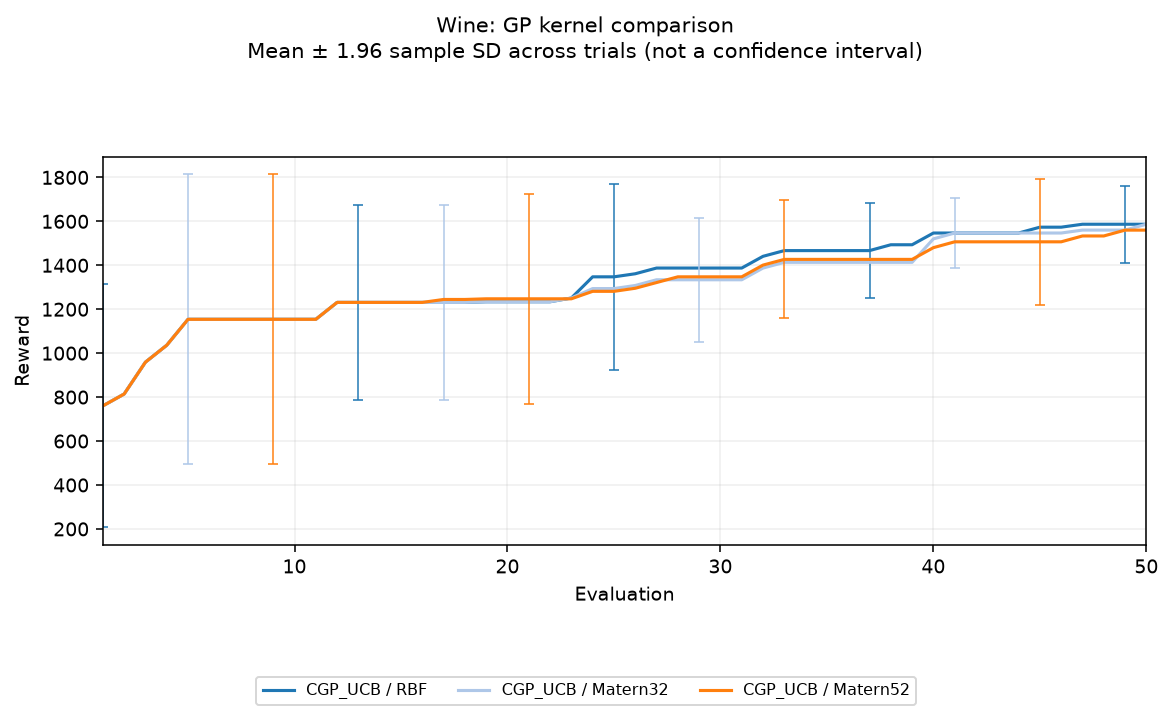

In [ ]:
import basat

seed = basat.set_seed(412, threads=1)
run_directory = basat.new_run_directory("results/last_guide/real_kernels")
loaded = basat.load_dataset(
    basat.find_path("data/contextual/wine_bandit.csv"), environment="contextual",
)
bounds = loaded.bounds
optimizer = basat.AcquisitionOptimizerSpec(
    raw_samples=32, restarts=2, maxiter=50, fit_maxiter=50,
)
algorithms = {
    "CGP_UCB / RBF": basat.CGP_UCB(
        bounds=bounds, config=basat.CGPUCBConfig(
            action_bounds=bounds, action_kernel=basat.KernelConfig(name="rbf"),
            context_kernel=basat.KernelConfig(name="rbf"), beta=3.0,
            initial_points=8, acquisition_optimizer=optimizer, seed=seed,
        ), dtype="float64",
    ),
    "CGP_UCB / Matern32": basat.CGP_UCB(
        bounds=bounds, config=basat.CGPUCBConfig(
            action_bounds=bounds, action_kernel=basat.KernelConfig(name="matern32"),
            context_kernel=basat.KernelConfig(name="rbf"), beta=3.0,
            initial_points=8, acquisition_optimizer=optimizer, seed=seed,
        ), dtype="float64",
    ),
    "CGP_UCB / Matern52": basat.CGP_UCB(
        bounds=bounds, config=basat.CGPUCBConfig(
            action_bounds=bounds, action_kernel=basat.KernelConfig(name="matern52"),
            context_kernel=basat.KernelConfig(name="rbf"), beta=3.0,
            initial_points=8, acquisition_optimizer=optimizer, seed=seed,
        ), dtype="float64",
    ),
}
experiment = basat.Experiment(
    environment=basat.ContextualEnvironment(
        bounds=bounds, dataset=loaded.dataset, dtype="float64", seed=seed,
    ), algorithm=algorithms, output_directory=run_directory,
)
result = experiment.run(trials=5, max_evaluations=50, plot=False, progress=True)
print(experiment.summary())
print(experiment.diagnostics())
figure = basat.plot(
    experiment, kind="incumbent", title="Wine: GP kernel comparison",
    xlim=(1, 50), save_path=basat.join_path(run_directory, "kernels.png"),
)

## Sampling and batches

Sampling overrides are attached to the experiment by algorithm label.
The two TuRBO instances below compare Sobol and uniform sampling. Both
request batches of 2, so 25 completed rounds consume 50 evaluations.
`batch_size=2` uses the method's independent batch behavior. For a supported
joint Monte Carlo acquisition, use `batch_size=None, q_batch=2` instead;
the third configuration demonstrates joint EI. The budget applies to actions,
not rounds. Change a sampler only if that method supports the phase.

Saved-result refresh (no optimization was executed).
Source: results/last_guide/sampling_batches/run_3q5zetrd/results.json
Trials: 5/5; limits: {'max_evaluations': 50, 'max_rounds': None}
Algorithm | evaluations per trial | final mean best reward | failures
Sobol / batch2 | [50, 50, 50, 50, 50] | -5.3890733e-05 | 0
Uniform / batch2 | [50, 50, 50, 50, 50] | -0.019207686 | 0
Joint EI / q2 | [50, 50, 50, 50, 50] | -4.6761665e-06 | 0
Total recorded evaluations: 750; failed trials: 0

Recorded stopping reasons by trial:
Sobol / batch2: ['maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations']
Uniform / batch2: ['maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations']
Joint EI / q2: ['maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations']

Recorded warnings (deduplicated per algorithm):
Sobol / batch2: BasatJitterWarnin

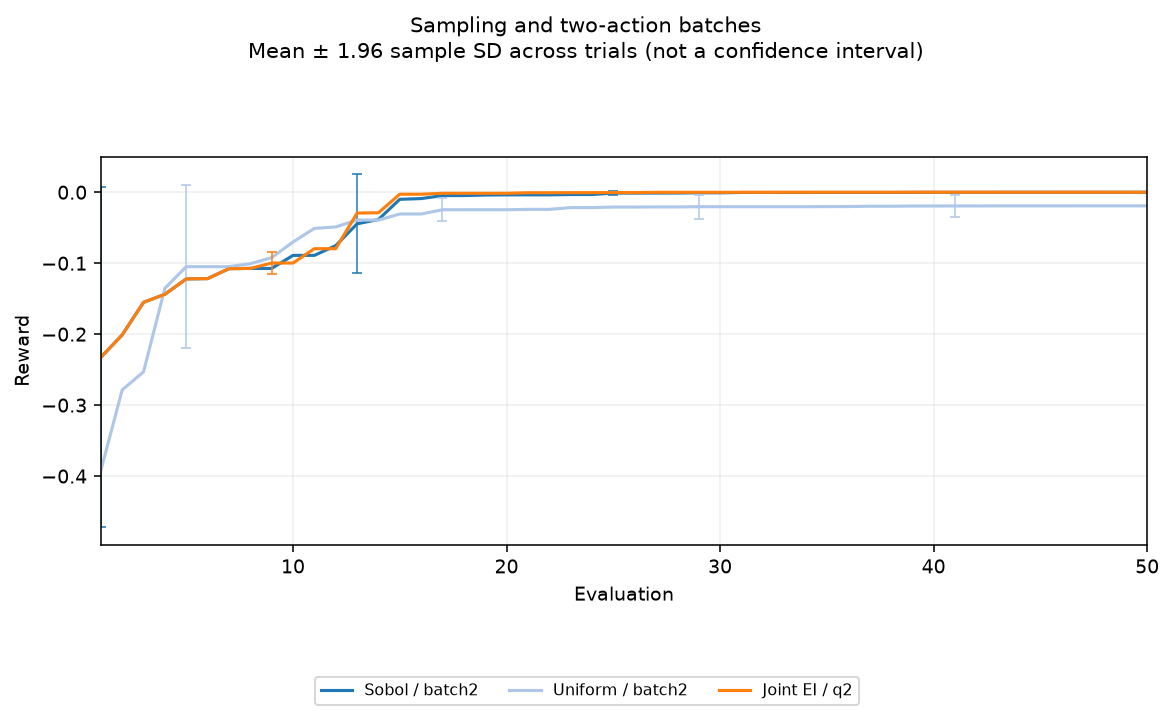

In [ ]:
import basat

seed = basat.set_seed(413, threads=1)
run_directory = basat.new_run_directory("results/last_guide/sampling_batches")
bounds = basat.Bounds(lower=[0.0] * 3, upper=[1.0] * 3)

def objective(values):
    return -sum((x - 0.6) ** 2 for x in values)

algorithms = {
    "Sobol / batch2": basat.TuRBO(
        bounds=bounds, config=basat.TuRBOConfig(
            initial_points=8, candidate_count=128, batch_size=2, seed=seed,
        ), dtype="float64",
    ),
    "Uniform / batch2": basat.TuRBO(
        bounds=bounds, config=basat.TuRBOConfig(
            initial_points=8, candidate_count=128, batch_size=2, seed=seed,
        ), dtype="float64",
    ),
    "Joint EI / q2": basat.TuRBO(
        bounds=bounds, config=basat.TuRBOConfig(
            initial_points=8, candidate_count=128, batch_size=None, q_batch=2,
            acquisition=basat.AcquisitionConfig(
                name="EI", mc_samples=64, seed=seed,
            ), seed=seed,
        ), dtype="float64",
    ),
}
experiment = basat.Experiment(
    environment=basat.StochasticEnvironment(
        bounds=bounds, function=objective, dtype="float64", seed=seed,
    ), algorithm=algorithms, output_directory=run_directory,
    initial_points_sampling_method={
        "Sobol / batch2": "sobol", "Uniform / batch2": "uniform",
        "Joint EI / q2": "sobol",
    },
    acquisition_sampling_method={
        "Sobol / batch2": "sobol", "Uniform / batch2": "uniform",
        "Joint EI / q2": "sobol",
    },
)
result = experiment.run(trials=5, max_evaluations=50, plot=False, progress=True)
print(experiment.summary())
figure = basat.plot(
    experiment, kind="incumbent", title="Sampling and two-action batches",
    xlim=(1, 50), save_path=basat.join_path(run_directory, "batches.png"),
)

## Save, resume, and explicit display

A single run writes into its chosen directory. A collection adds readable
`algorithms/NN-label/` subdirectories and a combined `results.json`. Each
method's settings, observations, diagnostics, and checkpoints remain separate.
The runner saves final records even if a periodic `save_every` checkpoint is
not due. Repeated experiments add `trials/trial-001/` through
`trials/trial-005/`; each trial contains its own method directories.
Resuming uses total ceilings: resuming 10 evaluations with a cap of 50 adds
at most 40 per trial. A fresh object must match the saved configuration.

`plot=False` disables the automatic progress plot. `plot=True, show=False`
creates it without displaying it. `show=True` displays it on a capable backend.
None of these settings change rewards or warning output. `basat.plot` controls
title, axes, limits, legends, file saving, and display; assign its result to
avoid notebook final-expression display when show=False. `basat.show` can
display the retained plot explicitly.

Saved-result refresh (no optimization was executed).
Source: results/last_guide/resume/run_4gsf9_g4/result.json
Trials: 5/5; limits: {'max_evaluations': 50, 'max_rounds': None}
Algorithm | evaluations per trial | final mean best reward | failures
TuRBO | [50, 50, 50, 50, 50] | -1.8840406e-05 | 0
Total recorded evaluations: 250; failed trials: 0

Recorded stopping reasons by trial:
TuRBO: ['maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations', 'maximum_evaluations']
This is the final saved state after continuation. The earlier 10-evaluation stage was not rerun.

Recorded warnings (deduplicated per algorithm):
TuRBO: BasatJitterWarning: Basat added diagonal jitter=1.0e-06 during GP posterior sampling because the covariance matrix was not positive definite.

Saved results: results/last_guide/resume/run_4gsf9_g4


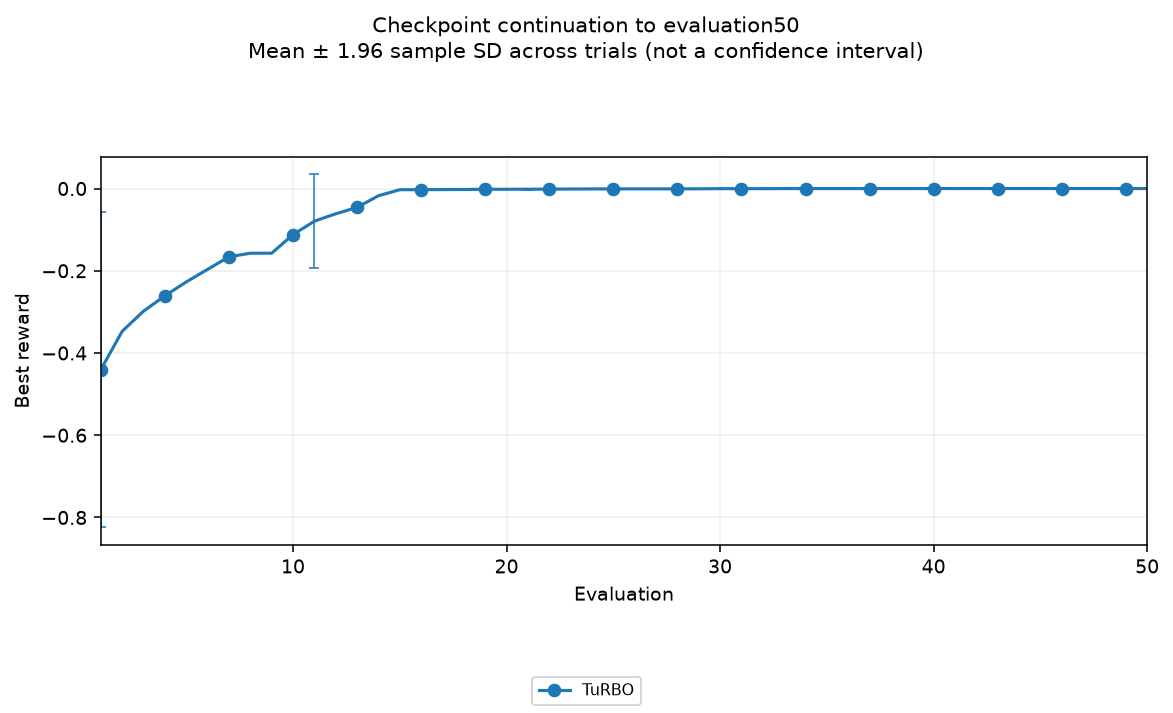

In [ ]:
import basat

seed = basat.set_seed(414, threads=1)
run_directory = basat.new_run_directory("results/last_guide/resume")
bounds = basat.Bounds(lower=[0.0] * 3, upper=[1.0] * 3)

def objective(values):
    return -sum((x - 0.45) ** 2 for x in values)

def make_experiment(resume):
    return basat.Experiment(
        environment=basat.StochasticEnvironment(
            bounds=bounds, function=objective, dtype="float64", seed=seed,
        ),
        algorithm=basat.TuRBO(
            bounds=bounds, config=basat.TuRBOConfig(
                initial_points=8, candidate_count=128, seed=seed,
            ), dtype="float64",
        ), output_directory=run_directory, resume=resume, save_every=5,
    )

first = make_experiment(False)
first_result = first.run(trials=5, max_evaluations=10, plot=True)
resumed = make_experiment(True)
resumed_result = resumed.run(trials=5, max_evaluations=50, plot=True, show=False)
print("Before:", first_result.evaluations, "After:", resumed_result.evaluations)
print(resumed.summary())
figure = basat.plot(
    resumed, kind="incumbent", title="Checkpoint continuation to evaluation50",
    xlabel="Evaluation", ylabel="Best reward", xlim=(1, 50),
    grid=True, legend=True, legend_columns=1, marker="o",
    save_path=basat.join_path(run_directory, "resumed.png"), show=False,
)
print("show=False retained the plot. Display it explicitly next:")
basat.show(figure)

# 5. Reproducibility

## 5.1 Hartmann6_300: Song et al. (2022)

**Current measured results: corrected Basat TuRBO; other curves archived.** Only standalone TuRBO was rerun for five seeds with the historical predictive-sampling policy. Modern BoTorch import defaults had forced dense Cholesky instead of the released Lanczos sampling path. The main figure replaces only that TuRBO curve; all eight other curves remain archived measurements. This is not a claim that every displayed TuRBO-based method has been rerun under the corrected policy. Changed TuRBO-based methods require fresh numerical-v3 checkpoints, including nested TuRBO variants; do not resume their old numerical-policy histories. The nine-method cell below is an **unexecuted current-library rerun** in a fresh directory, not the producer of the mixed-provenance displayed figure. A shorter independent TuRBO-only cell follows the measured report. This notebook refresh reuses the completed measurements and does not start another campaign.

This section replaces the previous six-suite reproduction section. Sections
1-4 and historical trajectories are preserved. Previously saved trajectories remain in their original directories.
The runnable cells below never resume the superseded paper_v2 campaign.

**Protocol.** Positive Hartmann6 on the first six coordinates of `[0,1]^300`,
294 irrelevant coordinates, no noise, five trials with seeds **2021-2025**,
and per-method budgets **including initialization**: **200** for SAASBO and
ALEBO, **600** for the five other Song baselines. The two added AG-VS variants
also receive **600**; that is an added comparison budget, not a Song paper setting.
There are nine curves (45 runs), including the two requested AG-VS variants.
There is no dataset download: the objective is defined in the cell.

**Source.** Song et al., *Monte Carlo Tree Search based Variable Selection for
High Dimensional Bayesian Optimization*, Figure 2 and Appendix C;
[MCTS-VS commit 29d32b6](https://github.com/lamda-bbo/MCTS-VS/tree/29d32b6977d37f5e257d359373497e375befa96b).
Underlying Ax 0.2.2 / BoTorch 0.5.1 model behavior is inspected, not delegated to
external optimization wrappers. Basat implements the algorithms. NumPy, SciPy,
PyTorch, GPyTorch, scikit-learn and NumPyro/JAX supply internal numerical tools.

**Before running:** install the local Basat package with its `numpyro` extra
(`pip install -e '.[numpyro]'` from the package project), and restart the kernel
after code/dependency updates. The cell itself imports only `basat`; it does
not require earlier cells. `OUTPUT_DIRECTORY` is relative to the **notebook
kernel's working directory**, not to the installed Basat package or the
notebook file. The recorded frozen workers ran from the project root. The example cells use new output directories; they do not resume the displayed
archived cohorts. Opening a notebook under `docs` does not by itself select
the project root as the working directory. Configure the working directory before
running the cell; it contains no hardcoded directory change. New-project
outputs can be relocated with `OUTPUT_DIRECTORY`. Full SAASBO fits are expensive;
warmup, posterior samples and evaluation budgets are never reduced silently.

**Budget and resumption.** `budget_policy="finish_iteration"` completes an
already-started source batch/outer program. SAASBO's nominal budget of 200
therefore finishes at **202 actual calls** (10 + 64 x 3); ALEBO finishes at 200.
Other algorithms may similarly exceed their nominal 600 when completing a
source program. All calls are saved; comparisons use each method's first 200
or 600 observations, as specified above. A completed run is a no-op on resume. Checkpoints
have separate method/seed directories, and changed settings/code/runtime are
rejected rather than merged. Never launch two writers for one method/seed.

**Published-budget logging check.** Four bounded controls execute the released
tracker and check its 50-evaluation export interval: a 202-call SAASBO run last
exports the first 200 observations, while source-program overshoot after 600
does not enter the final 600-point export. Deliberately better overshoot values
were excluded in these tests. These are logger/counting controls, not additional
optimization results; see
[the test report](../output/reproducibility/source_tracker_budget_prefix_tests.xml).

**Plotting.** The paper-style plot uses mean per-run incumbent reward, the
source's 512-point symmetric EMA (`decay_steps=1`), and population SD divided by
sqrt(number of trials), with error bars every 64 display points. Unsmoothed
observations remain in the numeric archives. There is **one paper-budget
comparison figure**: ALEBO and SAASBO stop at 200, the five other Song baselines
at 600, and the added AG-VS curves at 600. No SAASBO/ALEBO 600-evaluation extension
is run or plotted in this section. Superseded v1 artifacts remain preserved
outside this new paper-budget campaign.

**Validated TuRBO interpretation.** The GP, candidate cloud and trust region
all use **D=300**, while only the objective uses the first six coordinates.
Restoring historical rank-100 Lanczos sampling reproduces all five original
incumbent trajectories within 1.76e-9, without seed or hyperparameter search.
The old mismatch was a demonstrated sampling-policy change, not an unexplained
randomness effect. This validation is specific to standalone TuRBO; the eight
other methods retain their own qualifications and require separate validation.

**Inference-quality reporting.** The saved comparison report summarizes every
completed SAASBO seed's full `fit_diagnostics.json` history, including per-fit
training counts, divergences, all recorded events, minimum ESS and maximum
reported R-hat. It is refreshed when the comparison reporter runs; a live fit
may not yet be in that saved snapshot. This campaign uses one MCMC chain:
reported split R-hat is not an independent multi-chain convergence assessment,
and the algorithm only applies its R-hat warning policy with multiple chains.
Thus an empty event list does not prove adequate mixing. Missing, invalid or
non-finite diagnostics are explicit; methods without durable fit histories are
marked `not_available`, with worker-log references, not assumed warning-free.
All measured runs, including warned fits, remain in the plotted statistics.

| Method | Important source or requested settings | Color |
|---|---|---|
| MCTS-VS-BO | Cp 0.1; Nv 2; Ns 3; best-20 fill; N_bad 5; N_split 3; source EI | crimson |
| MCTS-VS-TuRBO | Same tree; 50-call inner TuRBO programs | royal blue |
| TuRBO | D=300; 20 LHS points; batch 10; 50 Adam steps; 5,000 candidates; predictive TS; historical Lanczos policy v3 | light blue |
| LA-MCTS-TuRBO | 20 initial points; Cp 0.1; RBF SVM; 50-call inner programs | cyan |
| SAASBO | 10 initial points; queued triples; RBF SAAS; 512 warmup/256 samples/thinning 16 | orange |
| ALEBO | Embedding dimension 6; 10 initial points; source covariance/acquisition | brown |
| HeSBO | Embedding dimension 6; two initial points; source covariance/acquisition | olive |
| AG-VS-BO | 12 initial points; effective dimension 6; t_seq 2; batch 3; EI; N_bad 28 | purple |
| AG-VS-TuRBO | Same AG-VS visits; separate TuRBO proposal model; predictive TS | dark green |

AG-VS retains its scoring GP, anchors and split/merge equations. TuRBO state is
maintained per stable leaf; two batches cost six evaluations per visit, not a
nested 50-evaluation program. Split/merge/reinitialization create appropriate
fresh proposal states. `q_batch=None`; ordinary batches are not qEI batches.

**AG manuscript qualification.** These are configured Basat AG comparisons,
not reproductions of the revised AG-VS manuscript. The approved
`effective_dimension=6, split_groups=2` setting retains both children at each
binary merge. The seed-2021 pilots cycle between 300-coordinate retained nodes,
two 150-coordinate children, and their 300-coordinate union; these merges do
not eliminate coordinates. The revised manuscript dated 16 September 2026
instead specifies `n_split = d_eff + 1`: seven children with six retained here.
It also uses direct observed-response scoring, whereas the preserved Basat
implementation uses current-posterior scoring. The exact older manuscript
version governing that pre-existing implementation is not recoverable from
its stored metadata. We preserve the approved settings rather than alter this
experiment after seeing its results. Stored-state consistency checks do not
establish manuscript equivalence, and neither AG variant appears in Song's
figure. File hashes, source passages and the measured pilot checks are in
[the pilot audit](../output/reproducibility/hartmann_paper_v2_pilot_review.md).

### Optional: rerun all nine methods with the current library

Run the next cell to execute all nine algorithms for each of the five seeds.
Each run uses only its own observations and checkpoint. Every resolved config
field is saved to `settings.json` along with source/runtime provenance.


In [ ]:
# Current-library rerun, not the producer of every displayed archived curve.
# Fresh numerical-v3 directory; never resume the old paper_v2 campaign here.
# This cell is independent: no earlier guide cell is required.
import basat

OUTPUT_DIRECTORY = './results/reproducibility/hartmann6_300_song2022_sampling_v3'
SEEDS = (2021, 2022, 2023, 2024, 2025)
NAMES = (
    "MCTS-VS-BO", "MCTS-VS-TuRBO", "TuRBO", "LA-MCTS-TuRBO",
    "SAASBO", "ALEBO", "HeSBO", "AG-VS-BO", "AG-VS-TuRBO",
)
BUDGETS = {
    "MCTS-VS-BO": 600, "MCTS-VS-TuRBO": 600, "TuRBO": 600,
    "LA-MCTS-TuRBO": 600, "SAASBO": 200, "ALEBO": 200, "HeSBO": 600,
    "AG-VS-BO": 600, "AG-VS-TuRBO": 600,
}
COLORS = {
    "MCTS-VS-BO": "#DC143C", "MCTS-VS-TuRBO": "#4169E1",
    "TuRBO": "#ABC5E7", "LA-MCTS-TuRBO": "#00BEBE", "SAASBO": "#FF9933",
    "ALEBO": "#8D5447", "HeSBO": "#7C8806",
    "AG-VS-BO": "#8A2BE2", "AG-VS-TuRBO": "#228B22",
}
BOUNDS = basat.Bounds(lower=basat.array([0.] * 300), upper=basat.array([1.] * 300))


def hartmann6_300(x):
    """Positive Hartmann6 on x[0:6]; the other 294 coordinates are irrelevant."""
    alpha = x.new_tensor([1., 1.2, 3., 3.2])
    A = x.new_tensor([
        [10., 3., 17., 3.5, 1.7, 8.], [0.05, 10., 17., 0.1, 8., 14.],
        [3., 3.5, 1.7, 10., 17., 8.], [17., 8., 0.05, 10., 0.1, 14.],
    ])
    P = 1e-4 * x.new_tensor([
        [1312., 1696., 5569., 124., 8283., 5886.],
        [2329., 4135., 8307., 3736., 1004., 9991.],
        [2348., 1451., 3522., 2883., 3047., 6650.],
        [4047., 8828., 8732., 5743., 1091., 381.],
    ])
    return (alpha * (-(A * (x[:6] - P).square()).sum(-1)).exp()).sum()


optimum = basat.array([0.20169, 0.150011, 0.476874, 0.275332, 0.311652, 0.6573] + [0.] * 294)
assert abs(float(hartmann6_300(optimum)) - 3.322368011391339) < 1e-7
inactive_check = optimum.clone()
inactive_check[6:] = 1.
assert float(hartmann6_300(inactive_check)) == float(hartmann6_300(optimum))


def make_algorithm(name, seed):
    """Source settings, with only the two explicitly requested AG-VS additions."""
    common = dict(bounds=BOUNDS, maximize=True, dtype="float64", device="cpu",
                  plot=False, verbose=False, verbose_setting=False, verbose_iter_by_iter=False)
    ei = basat.AcquisitionConfig(name="EI", beta=2., xi=0., mc_samples=512, seed=seed)
    if name == "TuRBO":
        return basat.TuRBO(**common, config=basat.TuRBOConfig(
            source_protocol="mcts_vs_2022",
            initial_points=20, initial_points_sampling_method="paper", batch_size=10,
            acquisition="TS", candidate_count=5000, gp_training_steps=50,
            length_init=.8, length_min=2**-7, length_max=1.6,
            success_tolerance=3, failure_tolerance=30, perturbation_cap=20.,
            noisy_center="best_observation", seed=seed))
    if name in ("MCTS-VS-BO", "MCTS-VS-TuRBO"):
        return basat.MCTS_VS(**common, config=basat.MCTSVSConfig(
            source_protocol="mcts_vs_2022", Nv=2, Ns=3, archive_size=20,
            initial_points=12, initial_points_sampling_method="paper",
            bad_count_limit=5, split_threshold=3, exploration_constant=.1,
            inner_optimizer="bo" if name == "MCTS-VS-BO" else "turbo",
            inner_max_evaluations=50, candidate_pool_size=1024,
            kernel_lengthscale=1., gp_maxiter=50, batch_size=1, seed=seed))
    if name == "LA-MCTS-TuRBO":
        return basat.LA_MCTS(**common, config=basat.LAMCTSConfig(
            source_protocol="mcts_vs_2022",
            initial_points=20, initial_points_sampling_method="paper",
            exploration_constant=.1, split_threshold=21, min_child_size=1,
            max_depth=500, classifier="svm_rbf", classifier_gamma="auto",
            local_sampler="turbo", inner_max_evaluations=50,
            candidate_pool_size=1024, gp_maxiter=50, batch_size=1, seed=seed))
    if name == "SAASBO":
        return basat.SAASBO(**common, config=basat.SAASBOConfig(
            initial_points=10, initial_points_sampling_method="paper",
            shrinkage_scale=.1, warmup_steps=512, posterior_samples=256,
            thinning=16, num_chains=1, max_tree_depth=6, acquisition="EI",
            source_protocol="mcts_vs_2022", inference_backend="numpyro",
            batch_size=1, seed=seed), diagnostic_policy="warn",
            jit_compile=False, mcmc_num_threads=1, release_inference_cache=True)
    if name == "ALEBO":
        return basat.ALEBO(**common, config=basat.ALEBOConfig(
            embedding_dimension=6, source_protocol="ax_0_2_2", initial_points=10,
            initial_points_sampling_method="paper", acquisition=ei,
            metric_inference="laplace", metric_posterior_samples=25,
            fit_restarts=10, noise_variance=1e-7, raw_feasible_samples=1000,
            num_restarts=10, batch_size=1, seed=seed))
    if name == "HeSBO":
        return basat.HeSBO(**common, config=basat.HeSBOConfig(
            embedding_dimension=6, initial_points=2,
            initial_points_sampling_method="paper", acquisition=ei,
            batch_size=1, seed=seed, source_protocol="ax_0_2_2"))
    if name in ("AG-VS-BO", "AG-VS-TuRBO"):
        inner = None if name == "AG-VS-BO" else basat.TuRBOConfig(
            source_protocol="mcts_vs_2022",
            initial_points=3, initial_points_sampling_method="paper",
            batch_size=3, acquisition="TS", candidate_count=None,
            gp_training_steps=50, length_init=.8, length_min=2**-7,
            length_max=1.6, success_tolerance=3, failure_tolerance=None,
            perturbation_cap=20., noisy_center="best_observation", seed=seed)
        return basat.AG_VS(**common, config=basat.AG_VSConfig(
            effective_dimension=6, sequence_length=2, split_groups=2,
            initial_points=12, initial_points_sampling_method="paper", acquisition=ei,
            stopping_threshold=None, stopping_delta=None, stagnation_patience=28,
            gp_fit_method="mle", gp_maxiter=50, acquisition_restarts=10,
            acquisition_raw_samples=1024, batch_size=3, q_batch=None,
            inner_optimizer="bo" if name == "AG-VS-BO" else "turbo",
            inner_turbo_config=inner, seed=seed))
    raise ValueError(f"Unknown algorithm: {name}")


def json_config(value):
    """Save every resolved configuration field, including source defaults."""
    if callable(value):
        return {"callable": value.__module__ + "." + value.__qualname__}
    if hasattr(value, "__dataclass_fields__"):
        return {key: json_config(getattr(value, key)) for key in value.__dataclass_fields__}
    if isinstance(value, dict):
        return {key: json_config(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_config(item) for item in value]
    return basat.to_list(value)


def json_diagnostics(value):
    """Encode non-finite audit values explicitly, never as invalid JSON numbers."""
    value = basat.to_list(value)
    if isinstance(value, dict):
        return {str(key): json_diagnostics(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_diagnostics(item) for item in value]
    if value is None or isinstance(value, (str, bool, int)):
        return value
    if isinstance(value, float):
        if value != value:
            return "NaN"
        if value == float("inf"):
            return "Infinity"
        if value == float("-inf"):
            return "-Infinity"
        return value
    if hasattr(value, "tolist"):
        return json_diagnostics(value.tolist())
    return {"unsupported_diagnostic_type": type(value).__module__ + "." + type(value).__qualname__}


PROTOCOL = {
    "experiment": "Hartmann6_300", "revision": "song2022-paper-budgets-sampling-v3", "turbo_numerical_policy": 3,
    "source_commit": "29d32b6977d37f5e257d359373497e375befa96b",
    "source_url": "https://github.com/lamda-bbo/MCTS-VS",
    "objective": "positive Hartmann6 on first six coordinates; maximize",
    "dimension": 300, "effective_dimension": 6, "bounds": [0., 1.],
    "noise_std": 0., "warm_start": False, "initialization_included": True,
    "algorithms": list(NAMES), "seeds": list(SEEDS), "nominal_evaluations": BUDGETS,
    "budget_policy": "finish_iteration", "comparison_prefix": BUDGETS,
    "source_display_prefix": BUDGETS,
    "plot": {"transform": "incumbent", "resample": 512, "smoothing": "symmetric_ema",
             "decay_steps": 1., "uncertainty": "sem", "ddof": 0, "error_every": 64},
    "colors": COLORS,
    "qualification": "Paper budgets are 200 for SAASBO/ALEBO and 600 for the other Song baselines. AG-VS variants are additions with a 600-evaluation comparison budget, not Song-paper curves or claimed Song settings. Standalone TuRBO policy v3 was validated against all five historical seed logs. Other methods require their own validation after a fresh rerun. Full observations and source overshoot are retained; plotting prefixes are explicit. Dedicated NumPyro execution releases process-global JAX compilation caches after posterior invalidation to limit memory; inference settings and RNG are unchanged, but later operations may require recompilation.",
}


def validate_trajectory(store, name, seed):
    """Check actual saved measurements, never relabel an older cohort."""
    prefix = f"{name}/seed-{seed}"
    if not store.exists(prefix + "/trajectory.npz"):
        return None
    settings = store.read_json(prefix + "/settings.json")
    if settings["protocol"] != PROTOCOL or settings["seed"] != seed:
        raise ValueError(f"Protocol mismatch: {prefix}; choose a fresh output directory.")
    if settings.get("config") != json_config(make_algorithm(name, seed).config):
        raise ValueError(f"Resolved algorithm configuration mismatch: {prefix}")
    if settings.get("runtime") != basat.runtime_info(include_source_hash=True):
        raise ValueError(f"Code/runtime fingerprint mismatch: {prefix}")
    data = store.read_arrays(prefix + "/trajectory.npz")
    actions, reward = data["actions"], data["reward"]
    if reward.ndim != 1 or actions.shape != (len(reward), 300) or not bool(actions.isfinite().all()) \
            or not bool(reward.isfinite().all()) or bool((actions < 0).any()) or bool((actions > 1).any()):
        raise ValueError(f"Invalid measured trajectory: {prefix}")
    error = max((abs(float(hartmann6_300(x)) - float(y))
                 for x, y in zip(actions, reward, strict=True)), default=0.)
    if error > 1e-10:
        raise ValueError(f"Objective replay failed for {prefix}: error={error}")
    budget = BUDGETS[name]
    status = store.read_json(prefix + "/status.json")
    if status["actual_evaluations"] != len(reward):
        raise ValueError(f"Evaluation accounting mismatch: {prefix}")
    if status["status"] == "complete" and (
        status.get("nominal_evaluations") != budget or len(reward) < budget
        or status.get("source_iteration_complete") is not True
        or status.get("overshoot") != len(reward) - budget
    ):
        raise ValueError(f"Completed source-budget accounting is invalid: {prefix}")
    if status["status"] == "complete" and (
        (name == "SAASBO" and len(reward) != 202)
        or (name == "ALEBO" and len(reward) != 200)
    ):
        raise ValueError(f"The completed run exceeds or misses its paper source boundary: {prefix}")
    return {"reward": basat.to_list(reward), "status": status,
            "reward_max_error": error, "path": store.path(prefix)}


def plot_hartmann(*, show=True):
    """Plot measured complete cohorts, with no extrapolation or hidden runs."""
    store = basat.ArtifactStore(OUTPUT_DIRECTORY)
    curves, evidence = {}, {}
    for name in NAMES:
        records = []
        for seed in SEEDS:
            status_path = f"{name}/seed-{seed}/status.json"
            if not store.exists(status_path) or store.read_json(status_path).get("status") != "complete":
                continue
            row = validate_trajectory(store, name, seed)
            if row is None:
                raise ValueError(f"Completed run has no measured trajectory: {name}, seed={seed}")
            records.append((seed, row))
        if not records:
            continue
        limit = BUDGETS[name]
        if any(len(row["reward"]) < limit for _, row in records):
            raise ValueError(f"A completed {name} run has fewer than {limit} observations.")
        label = name if len(records) == 5 else f"{name} (n={len(records)}/5; partial cohort)"
        curves[label] = basat.PlotSeries.from_runs(
            [row["reward"][:limit] for _, row in records], transform="incumbent",
            maximize=True, uncertainty="sem", ddof=0, error_scale=1.,
            resample=512, smoothing="symmetric_ema", decay_steps=1.,
            error_every=64, color=COLORS[name], linewidth=2., capsize=0.)
        evidence[name] = {"seeds": [seed for seed, _ in records], "plotted_prefix": limit,
                          "actual_evaluations": [len(row["reward"]) for _, row in records]}
    if not curves:
        print("No full-budget trajectories are available yet; no synthetic curves were drawn.")
        return None
    suffix = "comparison"
    store.write_json(suffix + "_evidence.json", evidence)
    return basat.plot_panels([basat.PlotPanel(
        curves, title="Hartmann6_300", xlabel="Number of evaluations", ylabel="Value",
        xlim=(0, 600), ylim=(0., 3.5), grid=False, legend=True,
        legend_columns=2, legend_fontsize=9.)],
        figsize=(11., 7.), title="Paper budgets; AG-VS variants are 600-evaluation additions",
        show=show, save_path=store.path(suffix + ".png"), dpi=200)


def run_hartmann(*, selected_names=NAMES, selected_seeds=SEEDS, show=True,
                raise_on_failure=False):
    """Run independent Basat experiments; seed 2021 is completed before seed 2022.

    The defaults run all 45 experiments. A worker can select disjoint methods
    or seeds without changing their checkpoint paths or scientific settings.
    Never run two writers for the same method/seed directory.
    A failed retry preserves an earlier validated complete trajectory and records
    last_failure.json separately. Workers use raise_on_failure=True so an older
    completion cannot be mistaken for success of the current invocation.
    Nonempty per-fit diagnostics are exported even after an unsuccessful fit;
    NaN and infinities are explicit strings in this separate audit document.
    """
    if not selected_names or any(name not in NAMES for name in selected_names):
        raise ValueError("Select one or more of the nine configured methods.")
    if not selected_seeds or any(seed not in SEEDS for seed in selected_seeds):
        raise ValueError("Trial seeds must be selected from 2021 through 2025.")
    store = basat.ArtifactStore(OUTPUT_DIRECTORY)
    if store.exists("protocol.json") and store.read_json("protocol.json") != PROTOCOL:
        raise ValueError("Protocol changed: choose a fresh OUTPUT_DIRECTORY.")
    store.write_json("protocol.json", PROTOCOL)
    runtime = basat.runtime_info(include_source_hash=True)
    failures = []
    for seed in selected_seeds:
        for name in selected_names:
            basat.set_seed(seed, threads=1)
            budget = BUDGETS[name]
            prefix = f"{name}/seed-{seed}"
            algorithm = None
            experiment = None
            previous_complete = None
            trajectory_written = False
            settings_compatible = not store.exists(prefix + "/settings.json")
            try:
                algorithm = make_algorithm(name, seed)
                if name in ('TuRBO', 'MCTS-VS-TuRBO', 'LA-MCTS-TuRBO', 'AG-VS-TuRBO'):
                    version_key = ('source_numerics_version' if name == 'TuRBO'
                                   else 'source_turbo_numerics_version')
                    if algorithm.state_dict()['algorithm_state'].get(version_key) != 3:
                        raise RuntimeError('Install the updated Basat and restart the kernel: TuRBO policy v3 is required.')
                settings = {"protocol": PROTOCOL, "seed": seed,
                            "config": json_config(algorithm.config), "runtime": runtime}
                if store.exists(prefix + "/settings.json"):
                    settings_compatible = store.read_json(prefix + "/settings.json") == settings
                    if not settings_compatible:
                        raise ValueError(f"Changed code/runtime/configuration: {prefix}. Use a fresh directory.")
                else:
                    store.write_json(prefix + "/settings.json", settings)
                if store.exists(prefix + "/status.json"):
                    prior_status = store.read_json(prefix + "/status.json")
                    if prior_status.get("status") == "complete":
                        prior = validate_trajectory(store, name, seed)
                        if prior is None:
                            raise ValueError(f"Completed run has no measured trajectory: {prefix}")
                        previous_complete = (prior_status, store.read_arrays(prefix + "/trajectory.npz"))
                environment = basat.StochasticEnvironment(
                    bounds=BOUNDS, function=hartmann6_300, dataset=None, previous_data=None,
                    noise_std=0., noise_fn=None, add_noise_to_data=False,
                    allow_repeated_actions=True, data_row_selection="first",
                    dtype="float64", device="cpu", seed=seed)
                experiment = basat.Experiment(
                    environment=environment, algorithm=algorithm, stopping_rule=None,
                    output_directory=store.path(prefix + "/checkpoint"), resume=True,
                    save_every=10, checkpoint_policy="periodic", constant_context=None,
                    initial_sampling_method="paper", acquisition_sampling_method="paper")
                store.write_json(prefix + "/status.json", {"status": "running",
                    "actual_evaluations": algorithm.evaluations, "nominal_evaluations": budget})
                print(f"{name}, seed={seed}: {algorithm.evaluations}/{budget} evaluations restored", flush=True)
                result = experiment.run(max_rounds=None, max_evaluations=budget,
                    budget_policy="finish_iteration", plot=False, show=False, progress=False)
                if result.evaluations < budget or not algorithm.source_iteration_complete:
                    raise RuntimeError("Stopped before the requested source-iteration boundary.")
                store.write_arrays(prefix + "/trajectory.npz",
                    actions=algorithm.observed_actions, reward=algorithm.observed_values)
                trajectory_written = True
                store.write_json(prefix + "/status.json", {"status": "complete",
                    "actual_evaluations": result.evaluations, "nominal_evaluations": budget,
                    "overshoot": result.evaluations - budget, "source_iteration_complete": True,
                    "best_value": result.best_observed_value,
                    "comparison_best_value": float(algorithm.observed_values[:budget].max())})
                validate_trajectory(store, name, seed)
                print(f"{name}, seed={seed}: complete, actual={result.evaluations}, "
                      f"best(first {budget})={float(algorithm.observed_values[:budget].max()):.6f}", flush=True)
            except Exception as error:
                failure = {"algorithm": name, "seed": seed, "error": f"{type(error).__name__}: {error}"}
                failures.append(failure)
                failure_status = {"status": "failed",
                    "actual_evaluations": 0 if algorithm is None else algorithm.evaluations,
                    "nominal_evaluations": budget,
                    "retained_previous_completion": previous_complete is not None, **failure}
                store.write_json(prefix + "/last_failure.json", failure_status)
                if previous_complete is not None:
                    if trajectory_written:
                        store.write_arrays(prefix + "/trajectory.npz", **previous_complete[1])
                    store.write_json(prefix + "/status.json", previous_complete[0])
                elif settings_compatible:
                    store.write_json(prefix + "/status.json", failure_status)
                print(f"FAILED: {failure}", flush=True)
            finally:
                history = getattr(getattr(algorithm, "state", None), "fit_diagnostics_history", [])
                if settings_compatible and history:
                    path = prefix + "/fit_diagnostics.json"
                    audit = {"format": "basat-fit-diagnostics-v1", "algorithm": name,
                             "seed": seed, "fit_count": len(history),
                             "nonfinite_encoding": "NaN, Infinity and -Infinity are strings",
                             "history": json_diagnostics(history)}
                    if store.exists(path) and store.read_json(path) != audit:
                        store.write_json(prefix + "/fit_diagnostics_history/" + store.sha256(path) + ".json",
                                         store.read_json(path))
                    store.write_json(path, audit)
    if failures:
        print("Failed attempts are recorded separately; no new completion was claimed:", failures)
        if raise_on_failure:
            raise RuntimeError(f"One or more Hartmann experiments failed: {failures}")
    comparison = plot_hartmann(show=show)
    return comparison


# Run this cell once; rerunning it resumes the same method/seed checkpoints.
comparison = run_hartmann()


### Original-paper comparison

Song et al., original Figure 2. The **Hartmann6_300 panel and legend are rendered directly from the supplied PDF**. These are the published results, not Basat output. CMA-ES and VAE-BO appear only in the original image and were not run here. AG-VS is absent from the source figure. The Basat panel uses paper budgets (ALEBO/SAASBO: 200; the five other Song baselines: 600). Both AG-VS curves use an added 600-evaluation comparison budget, not a budget specified by Song et al. The figure and summary table below describe the same recorded comparison, not a live rerun.

**TuRBO sampling correction:** the TuRBO curve is the newly measured five-seed Basat cohort with historical Lanczos predictive sampling. The eight other curves are archived, not rerun or newly validated. Older dense-sampling TuRBO results are preserved separately as superseded diagnostics, not used as the corrected main TuRBO curve.

| Corrected Basat TuRBO; other curves archived | Song et al., published result |
|---|---|
| 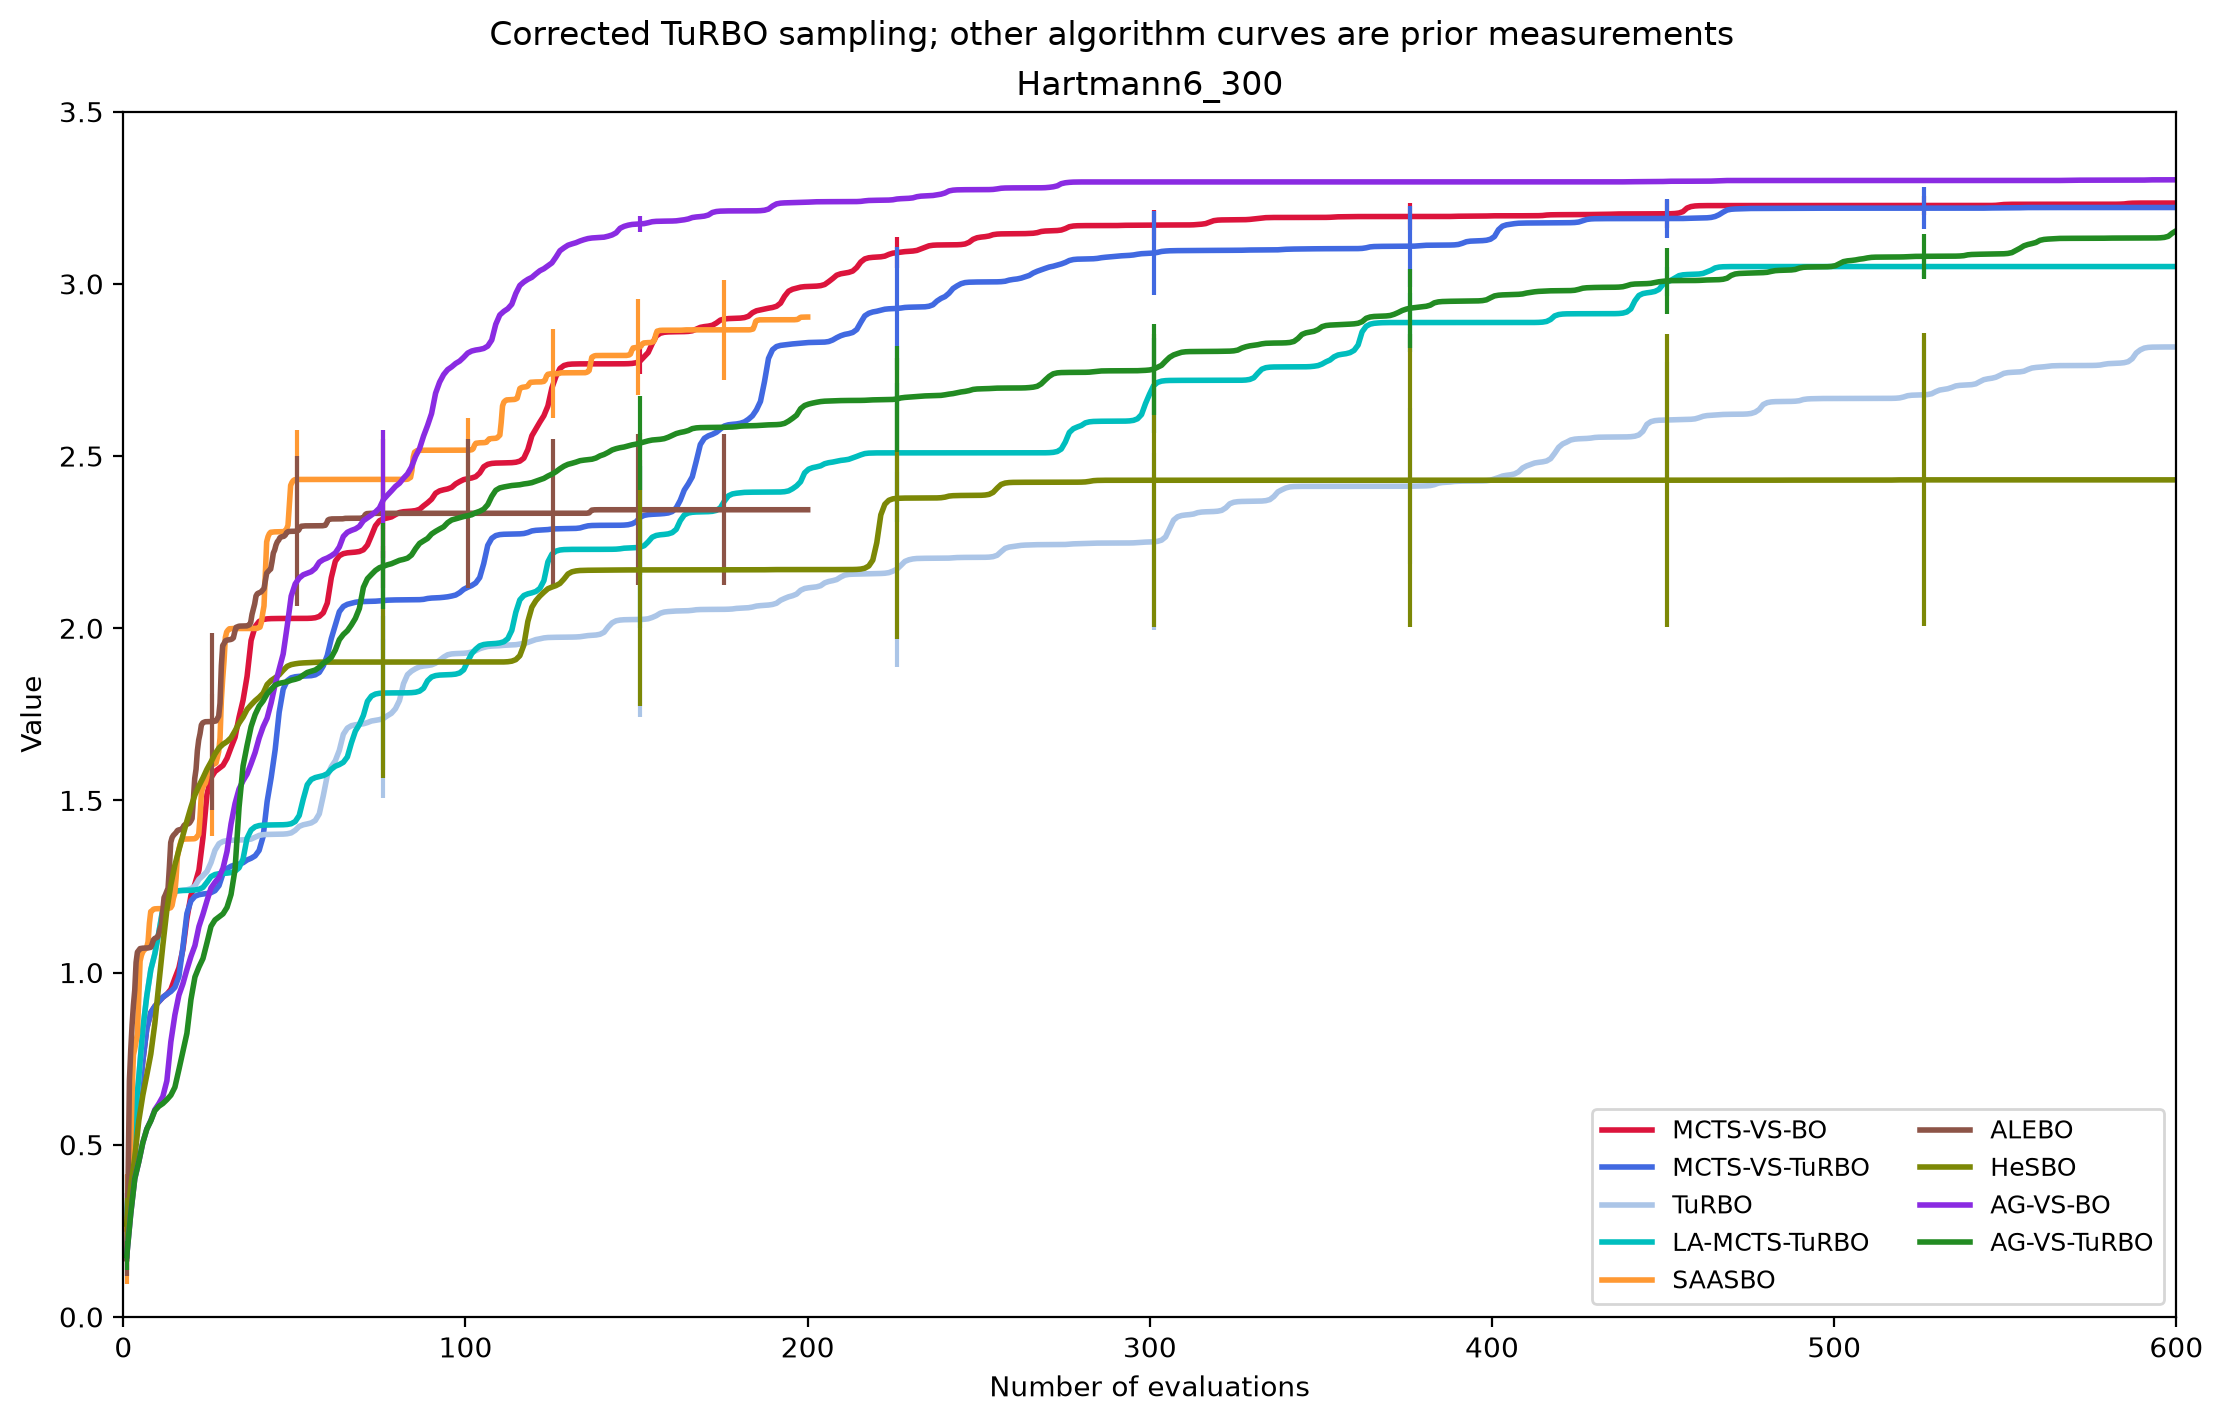 | 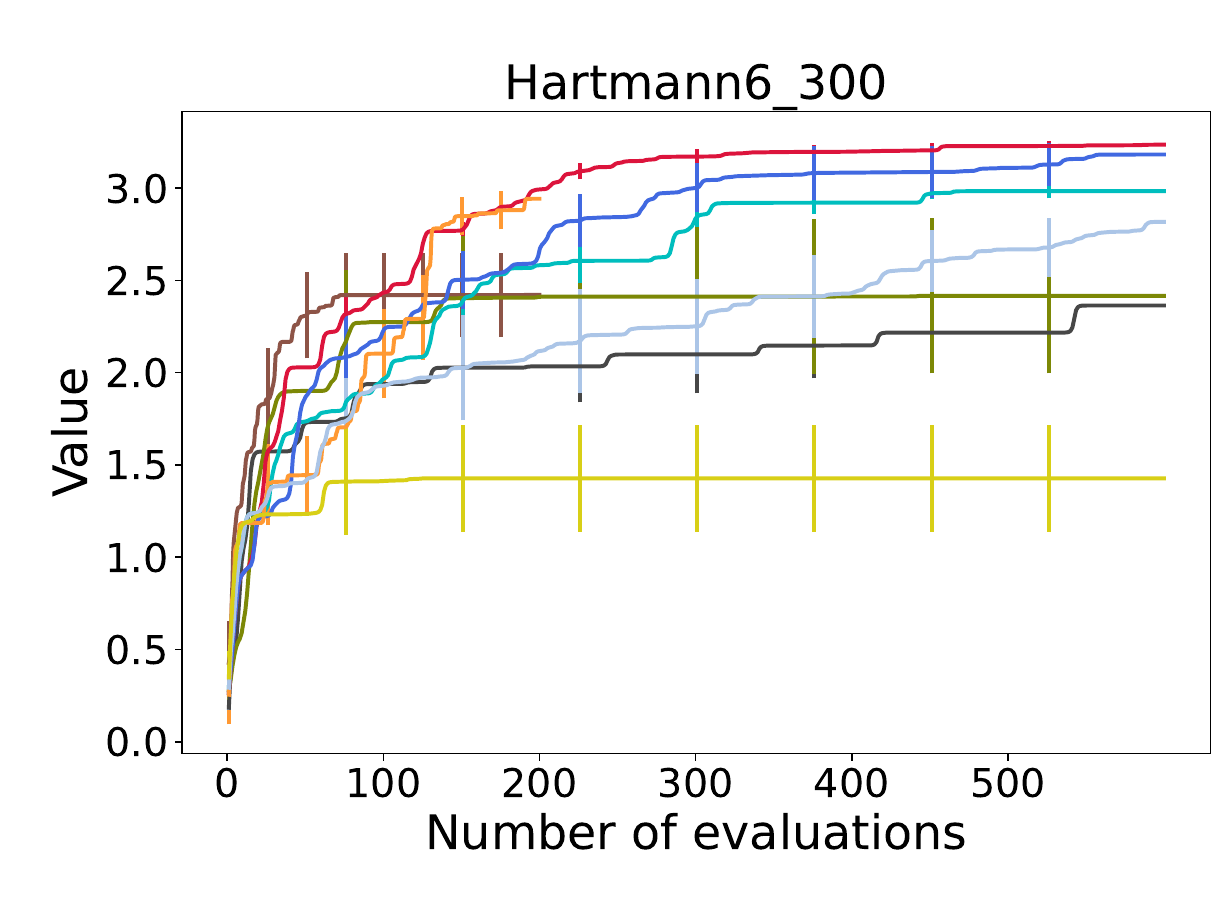 |

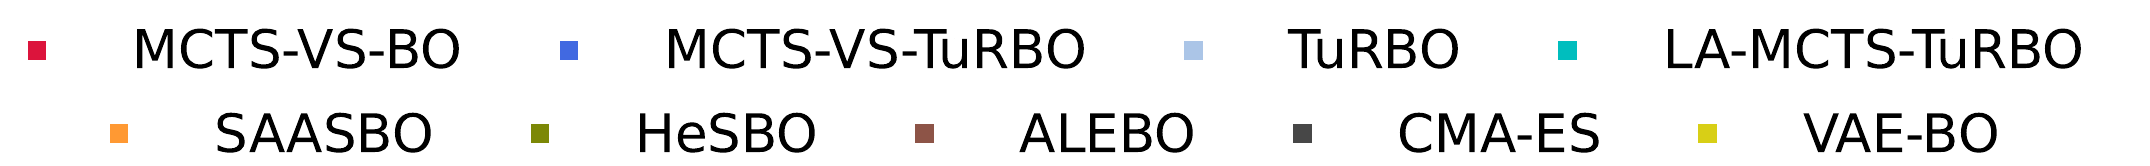

### TuRBO discrepancy resolved: historical sampling policy

The corrected Basat TuRBO was run from fresh checkpoints for all five official seeds (2021–2025), 600 evaluations each. Both the GP and candidate search use **D=300**; only the user-defined objective reads the first six coordinates. No seeds, benchmark constants, hyperparameters, evaluation budgets, or smoothing settings were tuned to fit the paper.

**Demonstrated cause:** modern BoTorch changes global GPyTorch/linear_operator defaults on import, disabling fast covariance roots. That forced dense Cholesky sampling of the 5,000-candidate posterior, despite TuRBO's Cholesky threshold of 2,000. Historical BoTorch 0.5.1 left rank-100 Lanczos sampling enabled. These produce different correlated Thompson draws and consume different random streams. The correction explicitly scopes the historical settings inside source-mode TuRBO and restores the caller's settings on exit. Native mode is unchanged.

The original code on the compatible historical numerical stack reproduced seed 2021 over all 600 evaluations within 3.38e-9. The unchanged original modules on the modern stack without the import override reproduced it within 1.32e-9. These controls establish the sampling-policy difference, not a generic rounding or random-seed explanation.

| Seed | Historical log | Corrected Basat | Maximum incumbent error over 600 evaluations |
|---|---:|---:|---:|
| 2021 | 2.605648983 | 2.605648983 | 4.84e-10 |
| 2022 | 2.757270996 | 2.757270995 | 1.4e-09 |
| 2023 | 2.883036129 | 2.883036128 | 1.09e-09 |
| 2024 | 2.520213660 | 2.520213661 | 7.08e-10 |
| 2025 | 3.317146954 | 3.317146955 | 1.75e-09 |

Final displayed means: corrected **2.816661574**, historical **2.816661574**; absolute difference **2.06e-10**. Maximum mean-curve difference: **6.33e-10**.

**Scope:** only standalone TuRBO was rerun. The other eight curves in the multi-algorithm panel are archived earlier measurements, not newly validated outputs of the corrected library. TuRBO-based inner optimizers share the fix and need fresh runs to update their curves. Old source-TuRBO checkpoints are rejected rather than silently mixed with numerical policy v3. Historical files and the earlier diagnostic figures are preserved. Restart an already-running notebook kernel before using the updated implementation.

The historical reference comes from `c9e5bb6:saved_logs/hartmann6_logs/hartmann6_300/turbo1-2021.csv` through `turbo1-2025.csv`, not digitized values. The next cell is independent and imports only `basat`; its output directory is separate from both archived cohorts. It has not been re-executed merely to embed these already-measured artifacts.


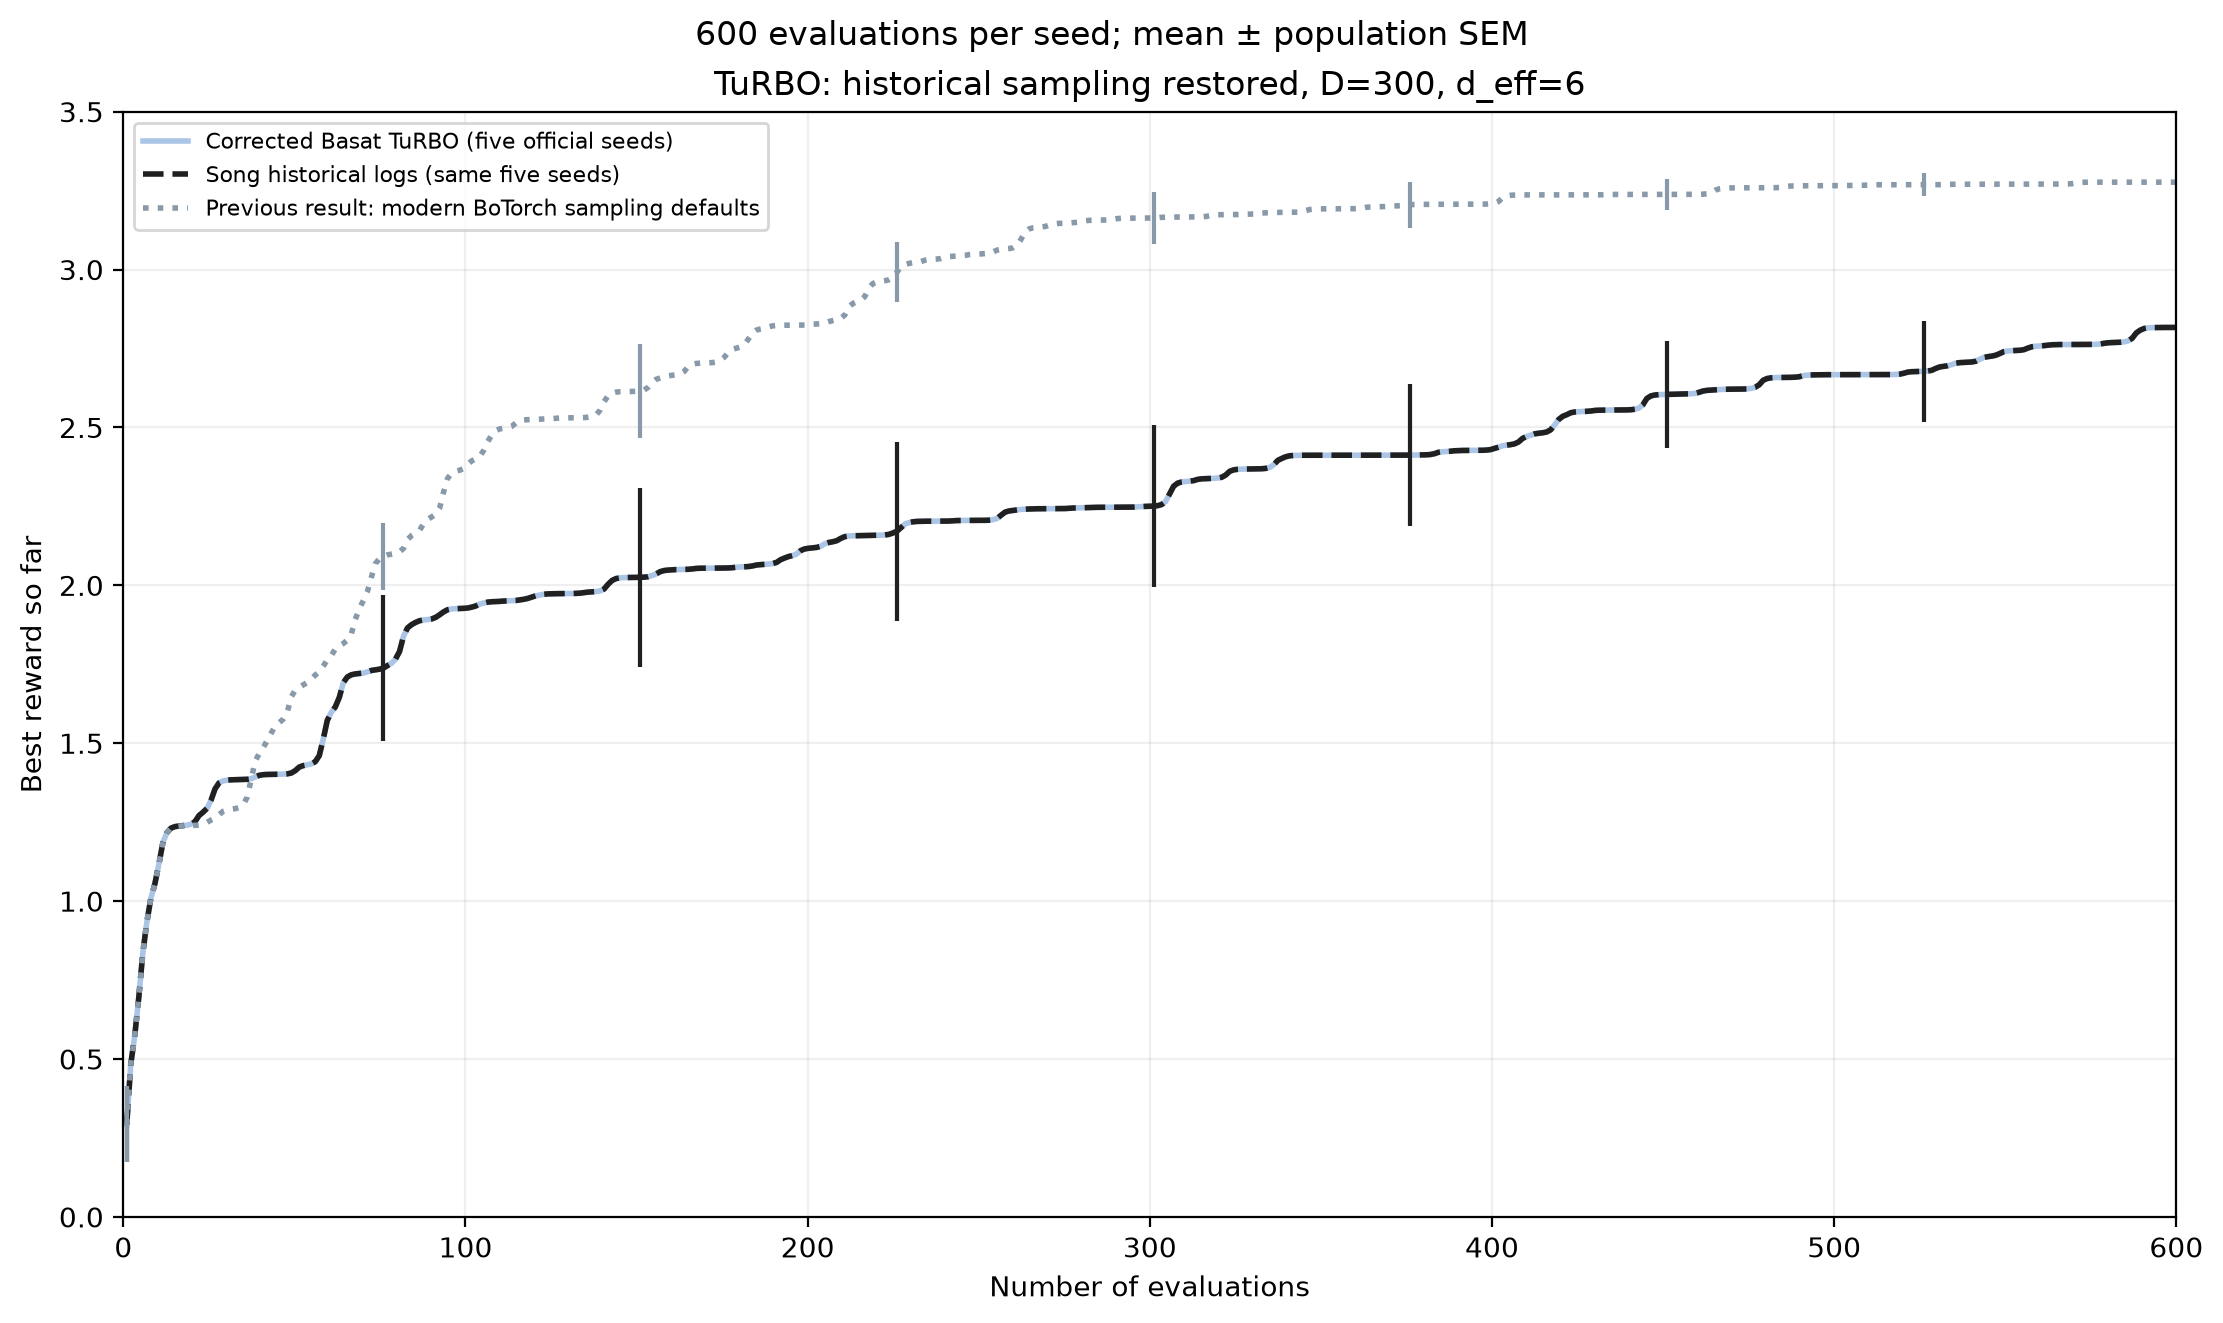

In [ ]:
import basat

# Independent cell. Outputs belong to the user's current working directory.
# This directory is deliberately different from the archived pre-fix campaign.
OUTPUT_DIRECTORY = "./results/hartmann6_300_turbo_historical_sampling_v3"
SEEDS = [2021, 2022, 2023, 2024, 2025]
BUDGET = 600


def hartmann6_300(x):
    """Positive Hartmann6; only the evaluator knows x[:6] is active."""
    alpha = x.new_tensor([1., 1.2, 3., 3.2])
    A = x.new_tensor([
        [10., 3., 17., 3.5, 1.7, 8.], [.05, 10., 17., .1, 8., 14.],
        [3., 3.5, 1.7, 10., 17., 8.], [17., 8., .05, 10., .1, 14.],
    ])
    P = 1e-4 * x.new_tensor([
        [1312., 1696., 5569., 124., 8283., 5886.],
        [2329., 4135., 8307., 3736., 1004., 9991.],
        [2348., 1451., 3522., 2883., 3047., 6650.],
        [4047., 8828., 8732., 5743., 1091., 381.],
    ])
    return (alpha * (-(A * (x[:6] - P).square()).sum(-1)).exp()).sum()


bounds = basat.Bounds(lower=[0.] * 300, upper=[1.] * 300)
store = basat.ArtifactStore(OUTPUT_DIRECTORY)
runs = []
for seed in SEEDS:
    basat.set_seed(seed, threads=1)
    config = dict(
        source_protocol="mcts_vs_2022", seed=seed,
        initial_points=20, initial_points_sampling_method="paper",
        batch_size=10, acquisition="TS", candidate_count=5000,
        gp_training_steps=50, max_cholesky_size=2000,
        length_init=.8, length_min=2**-7, length_max=1.6,
        success_tolerance=3, failure_tolerance=30,
        success_relative_tolerance=1e-3, perturbation_cap=20.,
        noisy_center="best_observation",
    )
    settings = dict(config=config, numerical_policy=3, dimension=300,
                    effective_dimension=6, budget=BUDGET,
                    runtime=basat.runtime_info(include_source_hash=True))
    prefix = f"seed-{seed}"
    if store.exists(prefix + "/settings.json"):
        if store.read_json(prefix + "/settings.json") != settings:
            raise ValueError("Changed configuration/code/runtime: choose a fresh output directory.")
    else:
        store.write_json(prefix + "/settings.json", settings)
    environment = basat.StochasticEnvironment(
        bounds=bounds, function=hartmann6_300,
        noise_std=0., dataset=None, previous_data=None,
        allow_repeated_actions=True, dtype="float64", device="cpu", seed=seed)
    algorithm = basat.TuRBO(
        bounds=bounds, config=basat.TuRBOConfig(**config),
        maximize=True, dtype="float64", device="cpu",
        plot=False, verbose=True, verbose_setting=False, verbose_iter_by_iter=False)
    assert algorithm.model_input_dimension == 300  # Never d_eff=6.
    if algorithm.state_dict()["algorithm_state"].get("source_numerics_version") != 3:
        raise RuntimeError("Install the updated Basat and restart the kernel: TuRBO policy v3 is required.")
    experiment = basat.Experiment(
        environment=environment, algorithm=algorithm, stopping_rule=None,
        output_directory=store.path(prefix + "/checkpoint"), resume=True,
        save_every=10, checkpoint_policy="periodic",
        initial_sampling_method="paper", acquisition_sampling_method="paper")
    result = experiment.run(max_rounds=None, max_evaluations=BUDGET,
                            budget_policy="strict", plot=False, show=False)
    assert result.evaluations == BUDGET
    store.write_arrays(prefix + "/trajectory.npz",
                       actions=algorithm.observed_actions, reward=algorithm.observed_values)
    runs.append(algorithm.observed_values[:BUDGET])
    print(f"seed={seed}; evaluations={result.evaluations}; best={result.best_observed_value:.9f}")

chart = basat.plot_panels([
    basat.PlotPanel(
        {"TuRBO (historical sampling, D=300)": basat.PlotSeries.from_runs(
            runs, transform="incumbent", maximize=True, uncertainty="sem", ddof=0,
            resample=512, smoothing="symmetric_ema", decay_steps=1., error_every=64,
            capsize=0., color="#ABC5E7", linewidth=2.)},
        title="Hartmann6_300: five official seeds", xlabel="Number of evaluations",
        ylabel="Best reward so far", xlim=(0, 600), ylim=(0., 3.5), grid=True)
], figsize=(10., 6.), show=True, save_path=store.path("comparison.png"), dpi=200)


**Result provenance.** The TuRBO row and light-blue curve use the corrected five-run cohort. Its reference is the recovered historical log mean, not image digitization. All other rows and curves retain the previous campaign's measurements and reference values. In particular, MCTS-VS-TuRBO, LA-MCTS-TuRBO and AG-VS-TuRBO have not been rerun under the corrected proposal policy. No claim of a fully revalidated nine-method ranking is made.

Corrected TuRBO recorded **0 warning events** across 3,000 objective evaluations. This records emitted warnings, not an MCMC convergence assessment. Its GP trained on 300-coordinate rows. [Per-seed diagnostics and provenance](../results/reproducibility/turbo_corrected_sampling_v3_klb84zz2/comparison.json).

### Current comparison summary

Values below compare the same plotted metric and published evaluation range. Single-seed pilot results are not a five-trial reproduction. AG-VS is an addition, so it has no Song-paper reference value.

| Method | Complete trials | At evaluation | Basat displayed mean | Reference mean | Difference |
|---|---:|---:|---:|---:|---:|
| MCTS-VS-BO | 5/5 | 600 | 3.2346 | 3.2346 | +0.0000 |
| MCTS-VS-TuRBO | 5/5 | 600 | 3.2217 | 3.1816 | +0.0401 |
| TuRBO | 5/5 | 600 | 2.816661574 | 2.816661574 | -2.06e-10 |
| LA-MCTS-TuRBO | 5/5 | 600 | 3.0502 | 2.9827 | +0.0675 |
| SAASBO | 5/5 | 200 | 2.9036 | 2.9418 | -0.0382 |
| ALEBO | 5/5 | 200 | 2.3440 | 2.4206 | -0.0766 |
| HeSBO | 5/5 | 600 | 2.4307 | 2.4157 | +0.0150 |
| AG-VS-BO | 5/5 | 600 | 3.3021 | not in paper | -- |
| AG-VS-TuRBO | 5/5 | 600 | 3.1544 | not in paper | -- |

**Displayed evidence: 5 corrected TuRBO runs + 40 archived runs.** This is not a newly executed 45-run campaign.

The numeric audit preserves each seed, actual overshoot, unsmoothed endpoint, published sparse SEM bars and descriptive discrepancies. No seed, setting, or smoother was adjusted to make these values agree.

Source-level fixtures and regression tests are documented in [the source audit](../output/reproducibility/hartmann_source_audit.md). They verify tested calculations and control flow, not the success of this full empirical comparison.

### Inference-quality evidence for the eight archived methods

All completed seeds remain in the comparison, including fits with warnings. The JSON report preserves every recorded per-fit event and the training-row count of every fit. Extrema use all finite recorded parameter coordinates, not just the final fit. Partial/invalid histories are not a clean bill of health.

Here, **n/a means not available**, never zero or evidence of convergence.

| Method / seed | History | Fits | Divergences | Minimum ESS | Maximum reported R-hat | Recorded events |
|---|---|---:|---:|---:|---:|---:|
| MCTS-VS-BO / 2021 | not_available; [worker log](../results/reproducibility/hartmann6_300_song2022_paper_v2/MCTS-VS-BO/seed-2021/worker.log) | n/a | n/a | n/a | n/a | n/a |
| MCTS-VS-BO / 2022 | not_available; [worker log](../results/reproducibility/hartmann6_300_song2022_paper_v2/MCTS-VS-BO/seed-2022/worker.log) | n/a | n/a | n/a | n/a | n/a |
| MCTS-VS-BO / 2023 | not_available; [worker log](../results/reproducibility/hartmann6_300_song2022_paper_v2/MCTS-VS-BO/seed-2023/worker.log) | n/a | n/a | n/a | n/a | n/a |
| MCTS-VS-BO / 2024 | not_available; [worker log](../results/reproducibility/hartmann6_300_song2022_paper_v2/MCTS-VS-BO/seed-2024/worker.log) | n/a | n/a | n/a | n/a | n/a |
| MCTS-VS-BO / 2025 | not_available; [worker log](../results/reproducibility/hartmann6_300_song2022_paper_v2/MCTS-VS-BO/seed-2025/worker.log) | n/a | n/a | n/a | n/a | n/a |
| MCTS-VS-TuRBO / 2021 | not_available; [worker log](../results/reproducibility/hartmann6_300_song2022_paper_v2/MCTS-VS-TuRBO/seed-2021/worker.log) | n/a | n/a | n/a | n/a | n/a |
| MCTS-VS-TuRBO / 2022 | not_available; [worker log](../results/reproducibility/hartmann6_300_song2022_paper_v2/MCTS-VS-TuRBO/seed-2022/worker.log) | n/a | n/a | n/a | n/a | n/a |
| MCTS-VS-TuRBO / 2023 | not_available; [worker log](../results/reproducibility/hartmann6_300_song2022_paper_v2/MCTS-VS-TuRBO/seed-2023/worker.log) | n/a | n/a | n/a | n/a | n/a |
| MCTS-VS-TuRBO / 2024 | not_available; [worker log](../results/reproducibility/hartmann6_300_song2022_paper_v2/MCTS-VS-TuRBO/seed-2024/worker.log) | n/a | n/a | n/a | n/a | n/a |
| MCTS-VS-TuRBO / 2025 | not_available; [worker log](../results/reproducibility/hartmann6_300_song2022_paper_v2/MCTS-VS-TuRBO/seed-2025/worker.log) | n/a | n/a | n/a | n/a | n/a |
| LA-MCTS-TuRBO / 2021 | not_available; [worker log](../results/reproducibility/hartmann6_300_song2022_paper_v2/LA-MCTS-TuRBO/seed-2021/worker.log) | n/a | n/a | n/a | n/a | n/a |
| LA-MCTS-TuRBO / 2022 | not_available; [worker log](../results/reproducibility/hartmann6_300_song2022_paper_v2/LA-MCTS-TuRBO/seed-2022/worker.log) | n/a | n/a | n/a | n/a | n/a |
| LA-MCTS-TuRBO / 2023 | not_available; [worker log](../results/reproducibility/hartmann6_300_song2022_paper_v2/LA-MCTS-TuRBO/seed-2023/worker.log) | n/a | n/a | n/a | n/a | n/a |
| LA-MCTS-TuRBO / 2024 | not_available; [worker log](../results/reproducibility/hartmann6_300_song2022_paper_v2/LA-MCTS-TuRBO/seed-2024/worker.log) | n/a | n/a | n/a | n/a | n/a |
| LA-MCTS-TuRBO / 2025 | not_available; [worker log](../results/reproducibility/hartmann6_300_song2022_paper_v2/LA-MCTS-TuRBO/seed-2025/worker.log) | n/a | n/a | n/a | n/a | n/a |
| SAASBO / 2021 | available; [fit history](../results/reproducibility/hartmann6_300_song2022_paper_v2/SAASBO/seed-2021/fit_diagnostics.json), [worker log](../results/reproducibility/hartmann6_300_song2022_paper_v2/SAASBO/seed-2021/worker.log) | 64 | 3 | 16.2 (rows 115) | 1.063 (rows 115) | 2 |
| SAASBO / 2022 | available; [fit history](../results/reproducibility/hartmann6_300_song2022_paper_v2/SAASBO/seed-2022/fit_diagnostics.json), [worker log](../results/reproducibility/hartmann6_300_song2022_paper_v2/SAASBO/seed-2022/worker.log) | 64 | 28 | 3.507 (rows 190) | 1.903 (rows 190) | 4 |
| SAASBO / 2023 | available; [fit history](../results/reproducibility/hartmann6_300_song2022_paper_v2/SAASBO/seed-2023/fit_diagnostics.json), [worker log](../results/reproducibility/hartmann6_300_song2022_paper_v2/SAASBO/seed-2023/worker.log) | 64 | 1 | 5 (rows 157) | 1.411 (rows 151) | 1 |
| SAASBO / 2024 | available; [fit history](../results/reproducibility/hartmann6_300_song2022_paper_v2/SAASBO/seed-2024/fit_diagnostics.json), [worker log](../results/reproducibility/hartmann6_300_song2022_paper_v2/SAASBO/seed-2024/worker.log) | 64 | 13 | 3.474 (rows 124) | 2.55 (rows 124) | 5 |
| SAASBO / 2025 | available; [fit history](../results/reproducibility/hartmann6_300_song2022_paper_v2/SAASBO/seed-2025/fit_diagnostics.json), [worker log](../results/reproducibility/hartmann6_300_song2022_paper_v2/SAASBO/seed-2025/worker.log) | 64 | 19 | 4.529 (rows 181) | 1.597 (rows 178) | 5 |
| ALEBO / 2021 | not_available; [worker log](../results/reproducibility/hartmann6_300_song2022_paper_v2/ALEBO/seed-2021/worker.log) | n/a | n/a | n/a | n/a | n/a |
| ALEBO / 2022 | not_available; [worker log](../results/reproducibility/hartmann6_300_song2022_paper_v2/ALEBO/seed-2022/worker.log) | n/a | n/a | n/a | n/a | n/a |
| ALEBO / 2023 | not_available; [worker log](../results/reproducibility/hartmann6_300_song2022_paper_v2/ALEBO/seed-2023/worker.log) | n/a | n/a | n/a | n/a | n/a |
| ALEBO / 2024 | not_available; [worker log](../results/reproducibility/hartmann6_300_song2022_paper_v2/ALEBO/seed-2024/worker.log) | n/a | n/a | n/a | n/a | n/a |
| ALEBO / 2025 | not_available; [worker log](../results/reproducibility/hartmann6_300_song2022_paper_v2/ALEBO/seed-2025/worker.log) | n/a | n/a | n/a | n/a | n/a |
| HeSBO / 2021 | not_available; [worker log](../results/reproducibility/hartmann6_300_song2022_paper_v2/HeSBO/seed-2021/worker.log) | n/a | n/a | n/a | n/a | n/a |
| HeSBO / 2022 | not_available; [worker log](../results/reproducibility/hartmann6_300_song2022_paper_v2/HeSBO/seed-2022/worker.log) | n/a | n/a | n/a | n/a | n/a |
| HeSBO / 2023 | not_available; [worker log](../results/reproducibility/hartmann6_300_song2022_paper_v2/HeSBO/seed-2023/worker.log) | n/a | n/a | n/a | n/a | n/a |
| HeSBO / 2024 | not_available; [worker log](../results/reproducibility/hartmann6_300_song2022_paper_v2/HeSBO/seed-2024/worker.log) | n/a | n/a | n/a | n/a | n/a |
| HeSBO / 2025 | not_available; [worker log](../results/reproducibility/hartmann6_300_song2022_paper_v2/HeSBO/seed-2025/worker.log) | n/a | n/a | n/a | n/a | n/a |
| AG-VS-BO / 2021 | not_available; [worker log](../results/reproducibility/hartmann6_300_song2022_paper_v2/AG-VS-BO/seed-2021/worker.log) | n/a | n/a | n/a | n/a | n/a |
| AG-VS-BO / 2022 | not_available; [worker log](../results/reproducibility/hartmann6_300_song2022_paper_v2/AG-VS-BO/seed-2022/worker.log) | n/a | n/a | n/a | n/a | n/a |
| AG-VS-BO / 2023 | not_available; [worker log](../results/reproducibility/hartmann6_300_song2022_paper_v2/AG-VS-BO/seed-2023/worker.log) | n/a | n/a | n/a | n/a | n/a |
| AG-VS-BO / 2024 | not_available; [worker log](../results/reproducibility/hartmann6_300_song2022_paper_v2/AG-VS-BO/seed-2024/worker.log) | n/a | n/a | n/a | n/a | n/a |
| AG-VS-BO / 2025 | not_available; [worker log](../results/reproducibility/hartmann6_300_song2022_paper_v2/AG-VS-BO/seed-2025/worker.log) | n/a | n/a | n/a | n/a | n/a |
| AG-VS-TuRBO / 2021 | not_available; [worker log](../results/reproducibility/hartmann6_300_song2022_paper_v2/AG-VS-TuRBO/seed-2021/worker.log) | n/a | n/a | n/a | n/a | n/a |
| AG-VS-TuRBO / 2022 | not_available; [worker log](../results/reproducibility/hartmann6_300_song2022_paper_v2/AG-VS-TuRBO/seed-2022/worker.log) | n/a | n/a | n/a | n/a | n/a |
| AG-VS-TuRBO / 2023 | not_available; [worker log](../results/reproducibility/hartmann6_300_song2022_paper_v2/AG-VS-TuRBO/seed-2023/worker.log) | n/a | n/a | n/a | n/a | n/a |
| AG-VS-TuRBO / 2024 | not_available; [worker log](../results/reproducibility/hartmann6_300_song2022_paper_v2/AG-VS-TuRBO/seed-2024/worker.log) | n/a | n/a | n/a | n/a | n/a |
| AG-VS-TuRBO / 2025 | not_available; [worker log](../results/reproducibility/hartmann6_300_song2022_paper_v2/AG-VS-TuRBO/seed-2025/worker.log) | n/a | n/a | n/a | n/a | n/a |

SAASBO uses one MCMC chain in this campaign. Its reported split R-hat is not an independent multi-chain convergence assessment; the algorithm's R-hat warning policy is checked only for more than one chain. Thus a high R-hat can occur without a warning event. Fit completion, finite draws, and an empty event list do not prove adequate mixing. Missing per-fit data for other methods is explicitly not_available, not evidence that their worker logs were quiet. See comparison_statistics.json for the chain count, metric coverage, non-finite/invalid-value paths, all recorded events, and per-fit counts.

### Historical evidence (not current results)

Superseded tables and figures are linked rather than repeated as competing current results. The files themselves are unchanged.

- [Original nine-method campaign report](../results/reproducibility/hartmann6_300_song2022_paper_v2/comparison_audit.md)
- [Sampling-policy investigation](../output/reproducibility/turbo_sampling_import_audit.md)
- [Frozen implementation and provenance](../output/reproducibility/turbo_sampling_v3_frozen/provenance.md)
- [Superseded original-runner diagnostic](../results/reproducibility/turbo_original_full_runner_20260918_dk_5onud/comparison.md)
